In [1]:
# loading modules
using PyPlot, Printf, LinearAlgebra, FFTW, FileIO, JLD2

using CUDA

using Setfield

# include("../../LinStab/mjcl_stab.jl")
# using .LinStab

using FourierFlows: CPU, TwoDGrid, plan_flows_rfft

using GeophysicalFlows

using Glob

using Statistics

using Parameters

using StaticArrays, KernelAbstractions

run_file_dir = "/scratch/cimes/ml1994/QG/julia/QG_topo/"
include(run_file_dir * "mjcl_gfjl_fcns.jl")


calc_Ld_modes (generic function with 1 method)

# Defining model parameters

In [2]:

dev = GeophysicalFlows.CPU()

Ny = Nx = n = 1024                # 2D resolution = n²


###################################################################################
## Geometry and background fields
###################################################################################

Nz = nlayers = 2                 # number of layers
f0 = f₀= 8.3e-5            # Coriolis param [s^-1]
g = 9.81                    # gravity
H = [2000., 2000.]     # the rest depths of each layer;

Us = [0.01, 0.017634058790440166, 0.024]
rhos = 1025.75 - 0.5775

kt = 0.

rho0 = 1025.        # Boussinesq reference density

# always zero for now, model can't even take this in as a parameter...
V = zeros(nlayers)


# running model

rho = ρ = [0., 1025.75]
rho[1] = ρ[1] = rhos[1]

strat_str = "uni_strat"
shear_str = "uni_shear"

# change U here
U = [0.,0.]
U[1] = Us[1]

gprime = (g/rho0)*(ρ[2] - ρ[1])

Ld = sqrt(gprime * sum(H)) / 2 / f0

L = Lx = Ly = 25*2*pi*Ld   # domain size [m]

###################################################################################
## Planetary PV gradient
###################################################################################
betas = βs = collect(range(-1.5,1.5,13)) * (U[1]/2) * Ld^-2
β = 0. # 1e-11              # the y-gradient of planetary PV; beta = β = 0. * (U[1]/2) * Ld^-2

###################################################################################
## Topography
###################################################################################

# set topography w/ current options:
topo_type = "y_slope"

# Defining a bulk slope parameter...should probably change this!

# setting slope(s)
S32 = f0 * U[1] / gprime

dyetab_over_S32 = collect(range(-1.5,1.5,13))
h0s = dyetab_over_S32 .* S32
# h0s = h0s[7:end]

# tuple of (bottom slope, h_rms)
h0 = (h0s[1], 0.)    #

# central wavenumber for rough topo
kt = 0.

# defining GFJL topo params
interim_params = mod_params(topo_type=topo_type, h0=h0, kt=kt)

topographic_pv_gradient, eta = define_topo(interim_params)

###################################################################################
# Dissipation
###################################################################################

# biharmonic viscosity
nν = 4
νstar = 0. # 10^-13
ν = νstar * ((U[1]-U[end])/2) * (Lx/2/pi)^7

dyn_nu = false

# Linear bottom drag
μstars = [0.125, 0.25, 0.5, 1.0, 2.0, 4.0]
mus = @. μstars * ((U[1]-U[end]) / 2) / Ld

# Quadratic bottom drag
κstars = [0.]
kappas = [0.] # @. κstars / Ld

###################################################################################
## Time stepping and sample rate
###################################################################################

if ν==0.
    stepper = "FilteredETDRK4"
    # af = 0.
    # global filt_order=4
    # global innerK = 2/3
else
    stepper = "ETDRK4"
    # af = 1/3
    # global filt_order=4
    # innerK = 2/3
end

# should I set dt via CFL condition instead?
dt = 600.

###################################################################################
## Details of saving data
###################################################################################
global diags = diag_bools(two_layer_kspace_modal_nrg_budget_bool=true);

# where to save model output; frequency of output
data_dir = "/scratch/cimes/ml1994/QG/julia/data/sloping_LD_two_layer_data/"

alt_data_dir = "/scratch/cimes/ml1994/QG/julia/data/JFM_May2025_data/"

f_s = 5. * (Ld / ((U[1]-U[end])/2)) #  N eddy turnover periods

# sampling period in time steps (set above)
nsubs = round(Int64, f_s/dt)

###################################################################################
## Model run parameters
###################################################################################

# steady-state  parameters
ss_yr_max = ceil(100 * (Ld / ((U[1]-U[end])/2)) / 3600 / 24 / 365.25)  # number of eddy periods converted to years for model run
yr_increment = 1.0 # how often to write to a save file

restart_bool = false

pre_buoy_restart_file = true
data_dir_pre_buoy = "/scratch/cimes/ml1994/QG/julia/data/two_layer_drag_study/"

###################################################################################
## Define params struct
###################################################################################
global model_params = mod_params(
data_dir = data_dir,
Nz = Nz, Nx = Nx, Ny = Ny, Lx = Lx, Ly = Ly, Ld = Ld,
H = H,
rho0 = rho0, rho = rho, strat_str = strat_str,
shear_str = shear_str, U = U,
μ = mus[1], κ = kappas[1], nν = nν, ν = ν, dyn_nu = dyn_nu,
eta = eta, topographic_pv_gradient = topographic_pv_gradient, topo_type = topo_type, h0 = h0,
β = β,
dt = dt,
stepper = stepper,
dev = dev,
restart_bool = restart_bool,
pre_buoy_restart_file = pre_buoy_restart_file,
data_dir_pre_buoy = data_dir_pre_buoy,
ss_yr_max = ss_yr_max,
yr_increment = yr_increment,
nsubs = nsubs)

###################################################################################
## Initialize model
###################################################################################

prob, prob_filt = initialize_model(model_params);

# prob = set_initial_conditions(prob, prob_filt, model_params)

sol, clock, params, vars, grid = prob.sol, prob.clock, prob.params, prob.vars, prob.grid;




In [3]:
dev = grid.device
T = eltype(grid)
A = device_array(dev)

rfftplan = plan_flows_rfft(A{T, 3}(undef, grid.nx, grid.ny, 1), [1, 2]; flags=FFTW.MEASURE);


In [4]:
function redef_mu_kappa(model_params, mu, kappa)
    @unpack_mod_params model_params

    mp_out = mod_params(
    data_dir = data_dir,
    Nz = Nz, Nx = Nx, Ny = Ny, Lx = Lx, Ly = Ly, Ld = Ld,
    H = H,
    rho0 = rho0, rho = rho, strat_str = strat_str,
    shear_str = shear_str, U = U,
    μ = mu , κ = kappa , nν = nν, ν = ν, dyn_nu=dyn_nu,
    eta = eta, topographic_pv_gradient = topographic_pv_gradient, topo_type = topo_type, h0 = h0,
    β = β,
    dt = dt,
    stepper = stepper,
    dev = dev,
    restart_bool = restart_bool,
    ss_yr_max = ss_yr_max,
    yr_increment = yr_increment,
    nsubs = nsubs);

    return mp_out
end

redef_mu_kappa (generic function with 1 method)

In [5]:
using PlotUtils

cm = cgrad(:coolwarm);
clrs = [cm[i] for i in range(0,1,100)]

hc_range = collect(range(h0s[1],h0s[end],100))

function h_color(h_in,hc_range,colors)
    c_ind = argmin(abs.(h_in .- (hc_range)))

    color_out = [red(clrs[c_ind]),green(clrs[c_ind]),blue(clrs[c_ind])]

    if h_in==0
        color_out = [0.,0.,0.]
    end
    return color_out
end

####################################################################
## 
####################################################################

function plot_info_box(ax, var, x, y, plus_mode, fsize)
    textstr = var * "\n" * L"+ \rightarrow" * plus_mode

    # these are matplotlib.patch.Patch properties
    props = Dict("boxstyle"=>"round", "facecolor"=>"wheat", "alpha"=>0.5)
    
    # place a text box in upper left in axes coords
    ax.text(x, y, textstr, transform=ax.transAxes, fontsize=fsize,
            ha="left", va="top", bbox=props)

    return nothing
end


####################################################################
## 
####################################################################


# tab20_range = collect(range(0,1,20))

function tab20_color(c_ind)

    cm2 = cgrad(:tab20);
    clrs2 = [cm2[i] for i in range(0,1,20)]

    color_out = [red(clrs2[c_ind]),green(clrs2[c_ind]),blue(clrs2[c_ind])]

    return color_out
end



tab20_color (generic function with 1 method)

In [6]:
betas

13-element Vector{Float64}:
 -9.348034737941376e-12
 -7.790028948284481e-12
 -6.232023158627585e-12
 -4.674017368970688e-12
 -3.1160115793137924e-12
 -1.5580057896568962e-12
  0.0
  1.5580057896568962e-12
  3.1160115793137924e-12
  4.674017368970688e-12
  6.232023158627585e-12
  7.790028948284481e-12
  9.348034737941376e-12

In [7]:
mus

6-element Vector{Float64}:
 2.2065285161714542e-8
 4.4130570323429084e-8
 8.826114064685817e-8
 1.7652228129371634e-7
 3.5304456258743267e-7
 7.060891251748653e-7

In [9]:
readdir(alt_data_dir, sort=false)

21-element Vector{String}:
 "layer2_Htot_4000.0_L_2pi4.449E+" ⋯ 85 bytes ⋯ "nu0.000E+00_res1024_yr54.01.jld"
 "layer2_Htot_4000.0_L_2pi4.449E+" ⋯ 85 bytes ⋯ "nu0.000E+00_res1024_yr71.99.jld"
 "layer2_Htot_4000.0_L_2pi4.449E+" ⋯ 85 bytes ⋯ "nu0.000E+00_res1024_yr54.01.jld"
 "layer2_Htot_4000.0_L_2pi4.449E+" ⋯ 85 bytes ⋯ "nu0.000E+00_res1024_yr71.99.jld"
 "layer2_Htot_4000.0_L_2pi4.449E+" ⋯ 85 bytes ⋯ "nu0.000E+00_res1024_yr54.01.jld"
 "layer2_Htot_4000.0_L_2pi4.449E+" ⋯ 84 bytes ⋯ "_nu0.000E+00_res1024_yr60.1.jld"
 "layer2_Htot_4000.0_L_2pi4.449E+" ⋯ 85 bytes ⋯ "nu0.000E+00_res1024_yr71.99.jld"
 "layer2_Htot_4000.0_L_2pi4.449E+" ⋯ 85 bytes ⋯ "nu0.000E+00_res1024_yr54.05.jld"
 "layer2_Htot_4000.0_L_2pi4.449E+" ⋯ 85 bytes ⋯ "nu0.000E+00_res1024_yr71.95.jld"
 "layer2_Htot_4000.0_L_2pi4.449E+" ⋯ 85 bytes ⋯ "nu0.000E+00_res1024_yr54.01.jld"
 "layer2_Htot_4000.0_L_2pi4.449E+" ⋯ 85 bytes ⋯ "nu0.000E+00_res1024_yr54.05.jld"
 "layer2_Htot_4000.0_L_2pi4.449E+" ⋯ 85 bytes ⋯ "nu0.000E+00_res1024_yr

# Checking which files we have

# Loading diagnostics for a given combination of drag and slope


In [7]:

i=7
j=1
k=6


h0 = (h0s[i], 0.0)
kappa_loc = kappas[j]
mu_loc = mus[k]

global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
global topo_PV, eta = define_topo(model_params)
global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)

beta = betas[10]
global model_params = redef_mu_kappa_beta(model_params, mu_loc, kappa_loc, beta)


# a = load(alt_data_dir*jld_name(model_params,71.99))
a = load(alt_data_dir*jld_name(model_params,71.95))

    

# energies are: (1) BTEKE, (2) BCEKE, (3) EAPE; (4) CBC; (5) Tflat, (6) Ttopo; , (7) DBT, (8) DBC;
#               (9) NLBC2BT, (10) NLBTEKE, (11) NLBT2BC; (12) NLBVEKE (13) NLBCEAPE (14) resid

# layer2_Htot_4000.0_L_2pi4.449E+06_y_slope_h0_0.000E+00_beta3.116E-12_uni_shear_uni_strat_mu8.826E-08_kappa0.000E+00_nu0.000E+00_res1024_yr57.7.jld


Dict{String, Any} with 1 entry:
  "jld_data" => Dict{String, Any}("ph_slices"=>-0.00246424, "two_layer_modal_le…

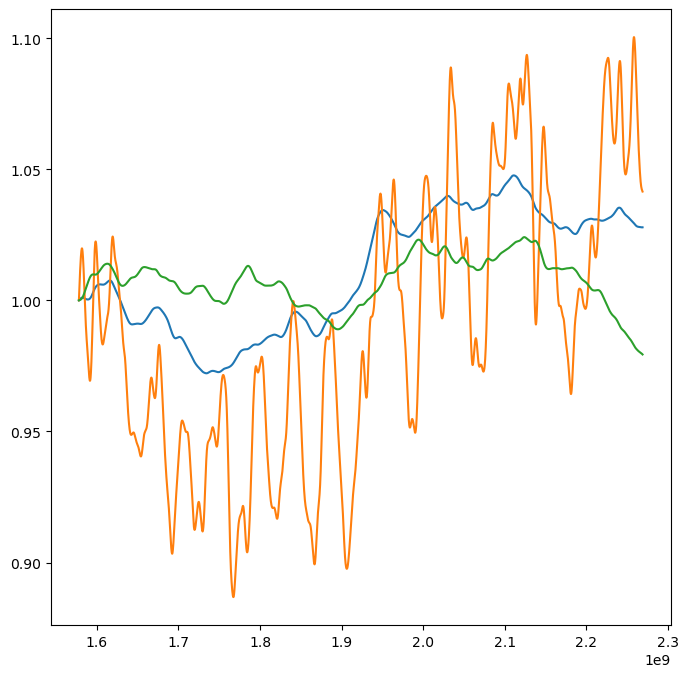

1-element Vector{PyCall.PyObject}:
 PyObject <matplotlib.lines.Line2D object at 0x154c0464e4d0>

In [8]:
fig,ax = plt.subplots(1,1, figsize=(8,8))

ax.plot(a["jld_data"]["t"][2:end], a["jld_data"]["two_layer_xspace_nrgs_ot"][1,1:length(a["jld_data"]["t"][2:end])] ./ a["jld_data"]["two_layer_xspace_nrgs_ot"][1,1])

ax.plot(a["jld_data"]["t"][2:end], a["jld_data"]["two_layer_xspace_nrgs_ot"][2,1:length(a["jld_data"]["t"][2:end])] ./ a["jld_data"]["two_layer_xspace_nrgs_ot"][2,1])

ax.plot(a["jld_data"]["t"][2:end], a["jld_data"]["two_layer_xspace_nrgs_ot"][3,1:length(a["jld_data"]["t"][2:end])] ./ a["jld_data"]["two_layer_xspace_nrgs_ot"][3,1])

9.63504322573587e-9
-8.122333307767925e-8
9.240771103070346e-8
-1.5493347272883612e-9


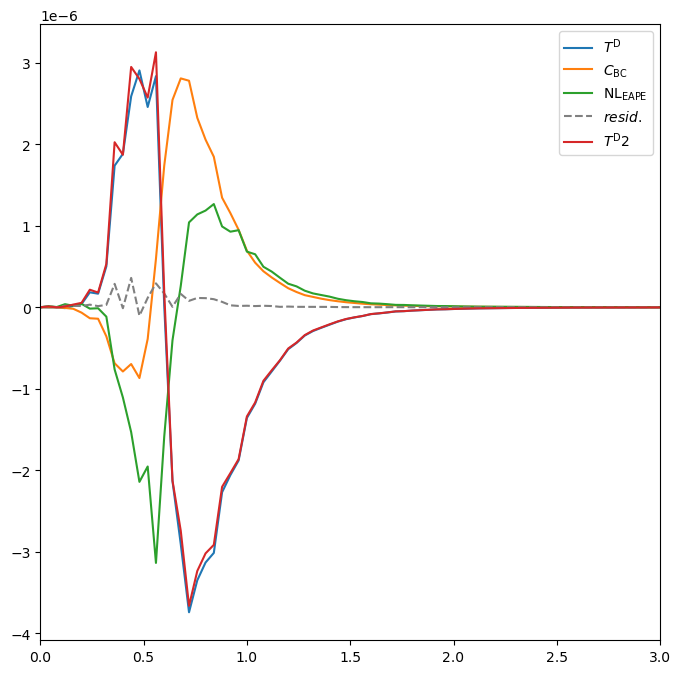

PyObject <matplotlib.legend.Legend object at 0x152a029f9090>

In [8]:
# fig,ax = plt.subplots(1,1, figsize=(8,8))

# norm = a["jld_data"]["two_layer_vBT_scale"]^-3 * Ld^-1
# ax.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .* norm, label=L"T^\mathrm{D}")
# ax.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* norm, label=L"C_\mathrm{BC}")
# ax.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14] .* norm , label=L"\mathrm{NL}_\mathrm{EAPE}")


# # ax.plot(grid.kr*Ld, (a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14]).* norm , label=L"sum")



# residual_EAPE = (a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14]) 
# ax.plot(grid.kr*Ld, residual_EAPE .* norm , color="gray", linestyle="--", label=L"resid.")
# # 
# # ax.plot(grid.kr*Ld, grid.kr .* (residual_EAPE .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4]) .* norm , label=L"T^\mathrm{D} 2")

# println(sum(grid.kr .* residual_EAPE))
# println(sum(grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4]))
# println(sum(grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5]))
# println(sum(grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14]))

# ax.set_xlim(0.0, 3.)
# ax.legend()

# # ax.set_xscale("log")

fig,ax = plt.subplots(1,1, figsize=(8,8))

norm = a["jld_data"]["two_layer_vBT_scale"]^-3 * Ld^-1
ax.plot(grid.kr*Ld, grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .* norm, label=L"T^\mathrm{D}")
ax.plot(grid.kr*Ld, grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* norm, label=L"C_\mathrm{BC}")
ax.plot(grid.kr*Ld, grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14] .* norm , label=L"\mathrm{NL}_\mathrm{EAPE}")


# ax.plot(grid.kr*Ld, (a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14]).* norm , label=L"sum")



residual_EAPE = (a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14]) 
ax.plot(grid.kr*Ld, grid.kr .* residual_EAPE .* norm , color="gray", linestyle="--", label=L"resid.")

ax.plot(grid.kr*Ld, grid.kr .* (residual_EAPE .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4]) .* norm , label=L"T^\mathrm{D} 2")

println(sum(grid.kr .* residual_EAPE))
println(sum(grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4]))
println(sum(grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5]))
println(sum(grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14]))

ax.set_xlim(0.0, 3.)
ax.legend()

# ax.set_xscale("log")

-1.3592734260391893e-9
-5.636229870044225e-7
5.772657992833212e-7
-1.500208570493778e-8


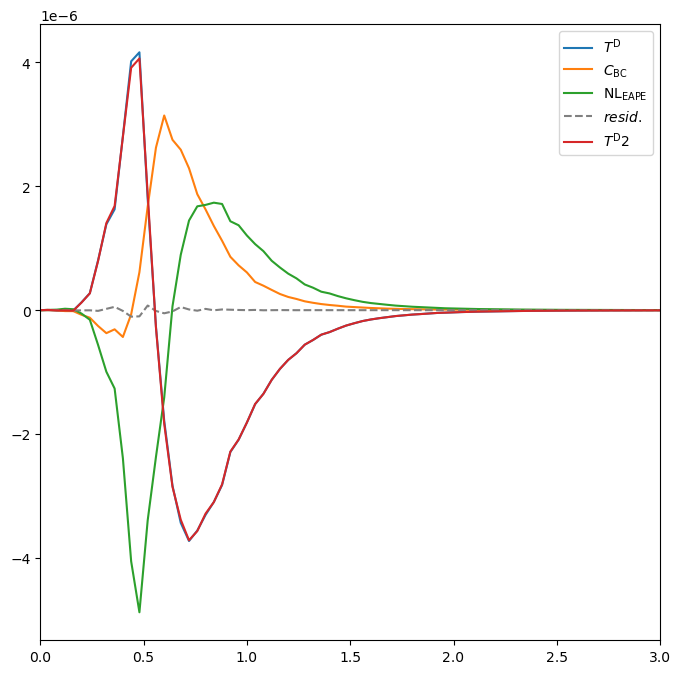

PyObject <matplotlib.legend.Legend object at 0x154b501d4c10>

In [10]:
fig,ax = plt.subplots(1,1, figsize=(8,8))

norm = a["jld_data"]["two_layer_vBT_scale"]^-3 * Ld^-1
ax.plot(grid.kr*Ld, grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .* norm, label=L"T^\mathrm{D}")
ax.plot(grid.kr*Ld, grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* norm, label=L"C_\mathrm{BC}")
ax.plot(grid.kr*Ld, grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14] .* norm , label=L"\mathrm{NL}_\mathrm{EAPE}")


# ax.plot(grid.kr*Ld, (a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14]).* norm , label=L"sum")



residual_EAPE = (a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14]) 
ax.plot(grid.kr*Ld, grid.kr .* residual_EAPE .* norm , color="gray", linestyle="--", label=L"resid.")

ax.plot(grid.kr*Ld, grid.kr .* (residual_EAPE .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4]) .* norm , label=L"T^\mathrm{D} 2")

println(sum(grid.kr .* residual_EAPE))
println(sum(grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4]))
println(sum(grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5]))
println(sum(grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14]))

ax.set_xlim(0.0, 3.)
ax.legend()

# ax.set_xscale("log")

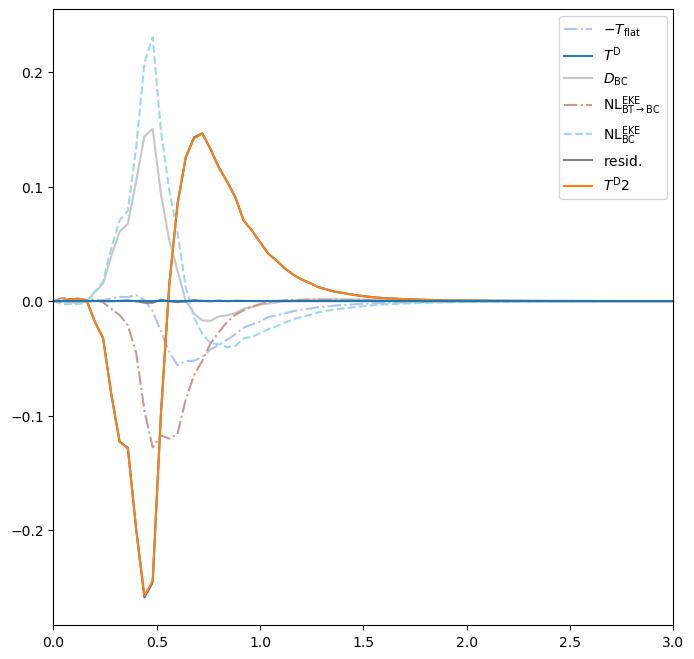

PyObject <matplotlib.legend.Legend object at 0x1549d81760b0>

In [11]:

fig,ax2 = plt.subplots(1,1, figsize=(8,8))

norm = a["jld_data"]["two_layer_vBT_scale"]^-3 * Ld^-1

ax2.plot(grid.kr*Ld, -a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,6] .* norm, label=L"-T_\mathrm{flat}", color=tab20_color(2), linestyle="dashdot")
ax2.plot(grid.kr*Ld, - a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .* norm , label=L"T^\mathrm{D}")
ax2.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9] .* norm , label=L"D_\mathrm{BC}", color=tab20_color(16), linestyle="solid")
ax2.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_{\mathrm{BT} \rightarrow \mathrm{BC}}", color=tab20_color(12), linestyle="dashdot")
ax2.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,13] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_\mathrm{BC}", color=tab20_color(20), linestyle="dashed")    

residual = (-a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,6] .- a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,13]) .* norm    

ax2.plot(grid.kr*Ld, residual , label=L"\mathrm{resid.}", color="gray", linestyle="solid")    

ax2.plot(grid.kr*Ld, -residual .- a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .* norm , label=L"T^\mathrm{D} 2")

# energies are: (1) BTEKE, (2) BCEKE, (3) EAPE; (4) CBC; (5) Tflat, (6) Ttopo; , (7) DBT, (8) DBC;
#               (9) NLBC2BT, (10) NLBTEKE, (11) NLBT2BC; (12) NLBVEKE (13) NLBCEAPE (14) resid

ax2.axhline(0.)

ax2.set_xlim(0., 3.)
ax2.legend()

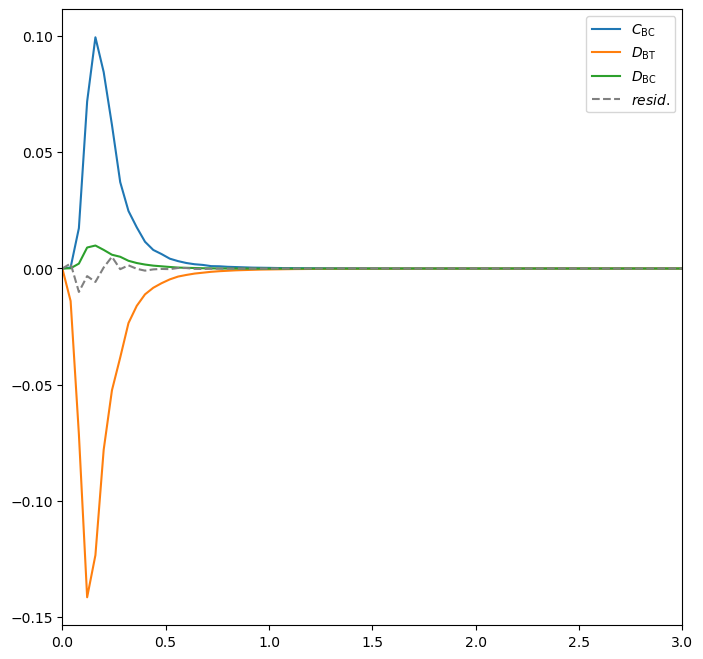

PyObject <matplotlib.legend.Legend object at 0x152826bac670>

In [32]:
fig,ax = plt.subplots(1,1, figsize=(8,8))

norm = a["jld_data"]["two_layer_vBT_scale"]^-3 * Ld^-1
ax.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* norm, label=L"C_\mathrm{BC}")
ax.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* norm, label=L"D_\mathrm{BT}")
ax.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9] .* norm , label=L"D_\mathrm{BC}")


# ax.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,7])

ax.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,15] .* norm, color="gray", linestyle="--", label=L"resid.")

# ax.plot(grid.kr*Ld, sum(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,7:13], dims=2) .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4], "k--")

# println(sum(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,7]))

ax.set_xlim(0., 3.)
ax.legend()

In [9]:

# wh = calc_w_int(prob.vars, prob.grid, a["jld_data"]["psi_yrs_end"], prob.params, model_params)

# plt.pcolormesh(abs.(wh))

# w_32 = deepcopy(vars.u[:,:,1])
# ldiv2D!(w_32, rfftplan, wh)

# plt.pcolormesh(w_32)
# plt.xlim(0,200)
# plt.ylim(0,200)

# plt.figure()
# plt.pcolormesh(a["jld_data"]["psi_yrs_end"][:,:,1])
# plt.xlim(0,200)
# plt.ylim(0,200)
ψ = a["jld_data"]["psi_yrs_end"]

    @unpack_mod_params model_params

    nlayers = Nz

    dev = grid.device
    T = eltype(grid)
    A = device_array(dev)

    rfftplanlayered = plan_flows_rfft(A{T, 3}(undef, grid.nx, grid.ny, nlayers), [1, 2]; flags=FFTW.MEASURE)
    rfftplan = plan_flows_rfft(A{T, 3}(undef, grid.nx, grid.ny, 1), [1, 2]; flags=FFTW.MEASURE)

    # parameters
    gr = gp(rho[1:2],rho0,g) 

    Ld = sqrt(gr * sum(H)) / (2 * f0)
    # ∂yηb = topographic_pv_gradient[2] / (f0 / H[end])
    
    ψh = deepcopy(vars.ψh)

    mul!(ψh, rfftplanlayered, ψ)

    # uh .= -im * grid_jl.l  .* ψh
    # vh .=  im * grid_jl.kr .* ψh

    u = deepcopy(ψ)
    v = deepcopy(ψ)

    ldiv!(u, rfftplanlayered, -im * grid.l  .* ψh)
    ldiv!(v, rfftplanlayered, im * grid.kr  .* ψh)

    U₁, U₂, = view(params.U, :, :, 1), view(params.U, :, :, 2)
    u1, v1 = view(u, :, :, 1), view(v, :, :, 1)
    u2, v2 = view(u, :, :, 2), view(v, :, :, 2)
    # q₁ = view(vars.q, :, :, 1)
    # q₂ = view(vars.q, :, :, 2)
    ψ1, ψ2 = view(ψ, :, :, 1), view(ψ, :, :, 2)
    ψ1h, ψ2h = view(ψh, :, :, 1), view(ψh, :, :, 2)
        
    # # calculating terms used in budget
    # ∂u∂yh = deepcopy(vars.uh)           # use vars.uh as scratch variable
    # ∂u∂y  = deepcopy(vars.u)            # use vars.u  as scratch variable
    # @. ∂u∂yh = im * grid_jl.l * vars.uh
    # invtransform!(∂u∂y, ∂u∂yh, params)
    
    # ∂u∂yh = rfft(∂u∂y)       # FFT{∂u∂y} in x- and y-direction
    # u₂h = rfft(u₂)           # FFT{u₂} in x- and y-direction
    
    ψ₁h, ψ₂h = view(ψh, :, :, 1), view(ψh, :, :, 2)
    
    # nonlinear terms
    ζh = -grid.Krsq .* ψh

    ζ = deepcopy(v)
    ldiv!(ζ, rfftplanlayered, -grid.Krsq .* ψh)

    ζ1, ζ2 = view(ζ, :, :, 1), view(ζ, :, :, 2)

    ∂xζ = deepcopy(ψ)
    ldiv!(∂xζ, rfftplanlayered, im .* grid.kr .* ζh)

    ∂yζ = deepcopy(ψ)
    ldiv!(∂yζ, rfftplanlayered, im .* grid.l .* ζh)

    ∂xζ1, ∂xζ2 = view(∂xζ, :, :, 1), view(∂xζ, :, :, 2)
    ∂yζ1, ∂yζ2 = view(∂yζ, :, :, 1), view(∂yζ, :, :, 2)

    J_ψ1_fpζ1 = @. u1 * ∂xζ1 + v1 * ∂yζ1 + v1 * β
    J_ψ2_fpζ2 = @. u2 * ∂xζ2 + v2 * ∂yζ2 + v2 * β

    J_ψ1_fpζ1h = deepcopy(ψh[:,:,1])
    mul2D!(J_ψ1_fpζ1h, rfftplan, J_ψ1_fpζ1)

    J_ψ2_fpζ2h = deepcopy(ψh[:,:,1])
    mul2D!(J_ψ2_fpζ2h, rfftplan, J_ψ2_fpζ2)

    ##
    J_ψ2_ψ1 = @. v1 * u2 - u1 * v2

    J_ψ2_ψ1h = deepcopy(ψh[:,:,1])
    mul2D!(J_ψ2_ψ1h, rfftplan, J_ψ2_ψ1)

    ∇2J_ψ2_ψ1h = - grid.Krsq .* J_ψ2_ψ1h

    ##
    v2h = im .* grid.kr .* ψ₂h

    J_ψ2_S32h = v2h .* f0 .* U₁ ./ gr

    ∇2J_ψ2_S32h = - grid.Krsq .* J_ψ2_S32h

    U1_∂xfpζ1h = deepcopy(ψh[:,:,1])
    mul2D!(U1_∂xfpζ1h, rfftplan, U₁ .* ∂xζ1 )

    

    # ∇2J_ψ2_ψ1_alt = deepcopy(ψ[:,:,1])
    # ldiv2D!(∇2J_ψ2_ψ1_alt, rfftplan, ∇2J_ψ2_ψ1h)

    # ##########
    # u1h = - im .* grid.l .* ψ₁h
    # v1h = im .* grid.kr .* ψ₁h
    # u2h = - im .* grid.l .* ψ₂h

    # ∇2J_ψ2_ψ1h = @. - v1h * grid.Krsq * u2h - 2 * (grid.kr^2 * u2h * v1h + grid.l^2 * u2h * v1h) - u2h * grid.Krsq * v1h

    # @. ∇2J_ψ2_ψ1h -= - u1h * grid.Krsq * v2h - 2 * (grid.kr^2 * v2h * u1h + grid.l^2 * v2h * u1h) - v2h * grid.Krsq * u1h

    # ∇2J_ψ2_ψ1 = deepcopy(ψ[:,:,1])
    # ldiv2D!(∇2J_ψ2_ψ1, rfftplan, ∇2J_ψ2_ψ1h)

################

    ##
    w_b = @. μ * H[2] * ζ2 / f0

    w_bh = deepcopy(ψh[:,:,1])
    mul2D!(w_bh, rfftplan, w_b)

# rhs_h = @. - (f0/gr) * (∇2J_ψ2_ψ1h + J_ψ2_fpζ2h - J_ψ1_fpζ1h - U1_∂xfpζ1h + (f0 / H[2]) * w_bh)



513×1024 Matrix{ComplexF64}:
 -8.55476e-28-0.0im          …  -8.39656e-13+4.17267e-13im
  6.08036e-14-1.80316e-13im     -8.43429e-13-1.21265e-12im
 -4.06659e-13+7.86857e-13im       5.3743e-13-2.11302e-12im
 -9.78114e-13-1.66658e-12im      1.84169e-12-7.9804e-13im
 -1.68812e-12+6.54799e-12im     -1.47338e-13+2.505e-12im
 -8.54583e-12+7.80395e-12im  …   1.59801e-12-1.30098e-11im
  1.13713e-12-6.64246e-12im     -1.08104e-11+2.19525e-11im
 -5.02123e-12+6.33602e-14im     -1.16057e-11+4.04361e-12im
  9.72904e-12+1.26008e-11im     -6.60261e-12+4.53667e-11im
 -2.14873e-11-2.70865e-11im     -1.75843e-12+6.2409e-12im
 -1.23648e-12-6.65225e-11im  …   1.25756e-11-3.33015e-11im
 -3.62444e-11-4.15779e-11im      2.98595e-11+5.14129e-11im
 -2.49543e-13-1.82315e-11im      -9.1837e-11+3.70117e-11im
             ⋮               ⋱  
  -1.8317e-13+5.2464e-13im       5.74855e-14-7.88639e-13im
 -1.41036e-12-1.10557e-13im     -5.14312e-13+2.11674e-13im
  2.43976e-13-7.32245e-13im     -5.67547e-13+4.25943e-13i

In [16]:
    L⁻¹ = (-grid.Krsq .- 2 * f0^2 / (gr * H[2])).^-1
    CUDA.@allowscalar L⁻¹[1,1] = 0.
    L⁻¹ = A(L⁻¹)

    rhs_h = @. - (f0/gr) * (∇2J_ψ2_ψ1h + J_ψ2_fpζ2h - J_ψ1_fpζ1h + (f0 / H[2]) * w_bh)

    omegah = L⁻¹ .* rhs_h

    T_Dh = @. - (f0 / H[2]) * (omegah) * conj(0.5 * (ψ₁h - ψ₂h))
    T_Dh .+= conj.(T_Dh)

    w_32 = deepcopy(vars.u[:,:,1])
    ldiv2D!(w_32, rfftplan, omegah)

############################################

    L⁻¹ = (-grid.Krsq .- 2 * f0^2 / (gr * H[2])).^-1
    CUDA.@allowscalar L⁻¹[1,1] = 0.
    L⁻¹ = A(L⁻¹)

    rhs_h = @. - (f0/gr) * (∇2J_ψ2_ψ1h + J_ψ2_fpζ2h - J_ψ1_fpζ1h - U1_∂xfpζ1h + (f0 / H[2]) * w_bh) + ∇2J_ψ2_S32h

    omegah = L⁻¹ .* rhs_h

    T_Dh_alt = @. - (f0 / H[2]) * (omegah) * conj(0.5 * (ψ₁h - ψ₂h))
    T_Dh_alt .+= conj.(T_Dh_alt)

    w_32 = deepcopy(vars.u[:,:,1])
    ldiv2D!(w_32, rfftplan, omegah)


1024×1024 Matrix{Float64}:
 1.49623e-6  1.53399e-6   1.53146e-6  …  1.12873e-6  1.26742e-6  1.41059e-6
 1.57477e-6  1.38871e-6   1.37401e-6     9.20662e-7  1.16114e-6  1.52325e-6
 1.75744e-6  1.44752e-6   1.30201e-6     7.78496e-7  1.11002e-6  1.62533e-6
 1.77146e-6  1.58358e-6   1.38005e-6     6.85623e-7  1.05381e-6  1.53516e-6
 1.6475e-6   1.61875e-6   1.47136e-6     6.48507e-7  1.05018e-6  1.40919e-6
 1.52291e-6  1.61134e-6   1.55847e-6  …  6.42487e-7  1.02596e-6  1.28802e-6
 1.39035e-6  1.55543e-6   1.57991e-6     6.52405e-7  9.40789e-7  1.139e-6
 1.29132e-6  1.46333e-6   1.5367e-6      6.42668e-7  8.79957e-7  1.06393e-6
 1.28157e-6  1.47949e-6   1.62789e-6     6.1062e-7   8.52196e-7  1.06599e-6
 1.36157e-6  1.6631e-6    1.91138e-6     6.15109e-7  8.47882e-7  1.09027e-6
 1.4987e-6   1.90073e-6   2.18854e-6  …  6.09584e-7  8.38554e-7  1.11778e-6
 1.56506e-6  2.01884e-6   2.30366e-6     5.1564e-7   7.41987e-7  1.07423e-6
 1.48017e-6  1.93474e-6   2.23419e-6     3.71624e-7  6.07504e-7

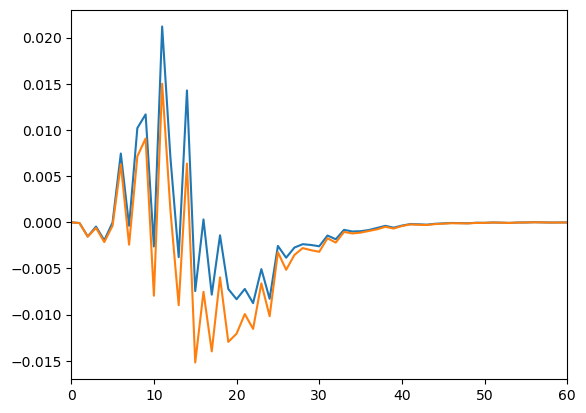

(0.0, 60.0)

In [17]:
rhs_h = @. - (f0/gr) * (∇2J_ψ2_ψ1h + J_ψ2_fpζ2h - J_ψ1_fpζ1h + (f0 / H[2]) * w_bh)

# plt.pcolormesh(∇2J_ψ2_ψ1_alt)
# plt.colorbar()

# plt.xlim(0,400)
# plt.ylim(0,400)

# plt.figure()
# # plt.pcolormesh(∇2J_ψ2_ψ1)
# plt.pcolormesh(J_ψ1_fpζ1)
# plt.colorbar()

# plt.xlim(0,400)
# plt.ylim(0,400)

# plt.colorbar()
# # plt.xlim(250,350)
# # plt.ylim(0,100)


# plt.figure()
# plt.pcolormesh(abs.(∂yζ1))
# plt.xlim(250,350)
# plt.ylim(0,100)

# sum(0.5*(ψ[:,:,1] .- ψ[:,:,2]) .* w_32)

# sum(abs.(T_Dh))

plt.figure()
plt.plot(isotropic_mean(T_Dh, prob.grid))
plt.plot(isotropic_mean(T_Dh_alt, prob.grid))


# # plt.plot(isotropic_mean(w_bh, prob.grid))
# # plt.pcolormesh(∂yζ2)

plt.xlim(0,60)
# plt.ylim(0,60)

# plt.plot(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4])

# sum(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5])


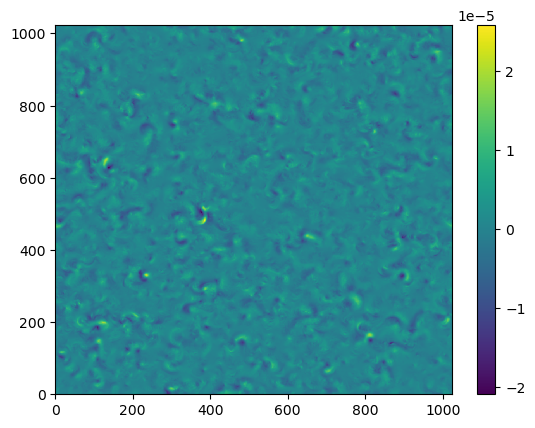

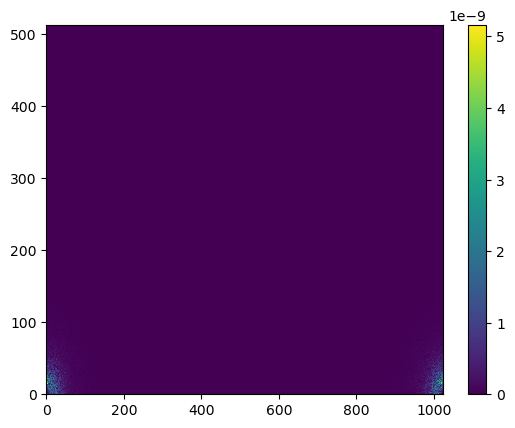

PyObject <matplotlib.colorbar.Colorbar object at 0x146b883e7c10>

In [49]:
plt.pcolormesh(w_32)
plt.colorbar()

plt.figure()

# plt.pcolormesh(w_b)
plt.pcolormesh(abs.((f0 / H[2]) * w_bh))
plt.colorbar()

# D_2 = (w_b .- w_32) ./ H[2]

# D_2h = deepcopy(ψh[:,:,1])
# mul2D!(D_2h, rfftplan, D_2)

# T_D_alt = -2 * f0 * isotropic_mean(real(D_2h .* conj(0.5 * (ψ₁h - ψ₂h))), prob.grid)

# plt.plot(T_D_alt)

# plt.plot(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9])

# T_D_c = - T_D_alt .+ 2 * a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9]
# plt.plot(T_D_c)

# plt.plot(isotropic_mean(T_Dh, prob.grid))

# plt.xlim(0,60)



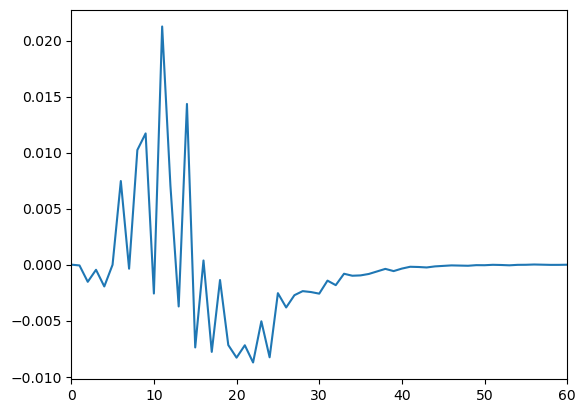

(0.0, 60.0)

In [43]:
    @unpack_mod_params model_params

    nlayers = Nz

    dev = grid.device
    T = eltype(grid)
    A = device_array(dev)

    rfftplanlayered = plan_flows_rfft(A{T, 3}(undef, grid.nx, grid.ny, nlayers), [1, 2]; flags=FFTW.MEASURE)
    rfftplan = plan_flows_rfft(A{T, 3}(undef, grid.nx, grid.ny, 1), [1, 2]; flags=FFTW.MEASURE)

    # parameters
    gr = gp(rho[1:2],rho0,g) 

    Ld = sqrt(gr * sum(H)) / (2 * f0)
    # ∂yηb = topographic_pv_gradient[2] / (f0 / H[end])
    
    ψh = deepcopy(vars.ψh)

    mul!(ψh, rfftplanlayered, ψ)

    # uh .= -im * grid_jl.l  .* ψh
    # vh .=  im * grid_jl.kr .* ψh

    u = deepcopy(ψ)
    v = deepcopy(ψ)

    ldiv!(u, rfftplanlayered, -im * grid.l  .* ψh)
    ldiv!(v, rfftplanlayered, im * grid.kr  .* ψh)

    U₁, U₂, = view(params.U, :, :, 1), view(params.U, :, :, 2)
    u1, v1 = view(u, :, :, 1), view(v, :, :, 1)
    u2, v2 = view(u, :, :, 2), view(v, :, :, 2)
    # q₁ = view(vars.q, :, :, 1)
    # q₂ = view(vars.q, :, :, 2)
    ψ1, ψ2 = view(ψ, :, :, 1), view(ψ, :, :, 2)
    ψ1h, ψ2h = view(ψh, :, :, 1), view(ψh, :, :, 2)
        
    # # calculating terms used in budget
    # ∂u∂yh = deepcopy(vars.uh)           # use vars.uh as scratch variable
    # ∂u∂y  = deepcopy(vars.u)            # use vars.u  as scratch variable
    # @. ∂u∂yh = im * grid_jl.l * vars.uh
    # invtransform!(∂u∂y, ∂u∂yh, params)
    
    # ∂u∂yh = rfft(∂u∂y)       # FFT{∂u∂y} in x- and y-direction
    # u₂h = rfft(u₂)           # FFT{u₂} in x- and y-direction
    
    ψ₁h, ψ₂h = view(ψh, :, :, 1), view(ψh, :, :, 2)
    
    # nonlinear terms
    ζh = -grid.Krsq .* ψh

    ζ = deepcopy(v)
    ldiv!(ζ, rfftplanlayered, -grid.Krsq .* ψh)

    ζ1, ζ2 = view(ζ, :, :, 1), view(ζ, :, :, 2)

    ∂xζ = deepcopy(ψ)
    ldiv!(∂xζ, rfftplanlayered, im .* grid.kr .* ζh)

    ∂yζ = deepcopy(ψ)
    ldiv!(∂yζ, rfftplanlayered, im .* grid.l .* ζh)

    ∂xζ1, ∂xζ2 = view(∂xζ, :, :, 1), view(∂xζ, :, :, 2)
    ∂yζ1, ∂yζ2 = view(∂yζ, :, :, 1), view(∂yζ, :, :, 2)

    J_ψ1_fpζ1 = @. u1 * ∂xζ1 + v1 * ∂yζ1 + v1 * β
    J_ψ2_fpζ2 = @. u2 * ∂xζ2 + v2 * ∂yζ2 + v2 * β

    J_ψ1_fpζ1h = deepcopy(ψh[:,:,1])
    mul2D!(J_ψ1_fpζ1h, rfftplan, J_ψ1_fpζ1)

    J_ψ2_fpζ2h = deepcopy(ψh[:,:,1])
    mul2D!(J_ψ2_fpζ2h, rfftplan, J_ψ2_fpζ2)

    ##
    J_ψ2_ψ1 = @. v1 * u2 - u1 * v2

    J_ψ2_ψ1h = deepcopy(ψh[:,:,1])
    mul2D!(J_ψ2_ψ1h, rfftplan, J_ψ2_ψ1)

    ∇2J_ψ2_ψ1h = - grid.Krsq .* J_ψ2_ψ1h

    ##
    v2h = im .* grid.kr .* ψ2h
    J_ψ2_S32h = v2h .* f0 .* U₁ ./ gr

    ∇2J_ψ2_S32h = - grid.Krsq .* J_ψ2_S32h

    ##
    w_b = @. μ * H[2] * ζ2 / f0

    w_bh = deepcopy(ψh[:,:,1])
    mul2D!(w_bh, rfftplan, w_b)

    # ############################################################################################
    # ############################################################################################

    # typeofSkl = SArray{Tuple{nlayers-1, nlayers-1}, T, 2, (nlayers-1)^2} # StaticArrays of type T and dims = (nlayers, nlayers)

    # L⁻¹ = Array{typeofSkl, 2}(undef, (grid.nkr, grid.nl))  # Array of StaticArrays
    # calcL⁻¹!(L⁻¹, f0, gr, H, nlayers, grid)


    L⁻¹ = (-grid.Krsq .- 2 * f0^2 / (gr * H[2])).^-1
    CUDA.@allowscalar L⁻¹[1,1] = 0.
    L⁻¹ = A(L⁻¹)

    rhs_h = @. - (f0/gr) * (∇2J_ψ2_S32h + ∇2J_ψ2_ψ1h + J_ψ2_fpζ2h - J_ψ1_fpζ1h + (f0 / H[2]) * w_bh)

    omegah = L⁻¹ .* rhs_h

    T_Dh = @. - (f0 / H[2]) * (omegah) * conj(0.5 * (ψ₁h - ψ₂h))
    T_Dh .+= conj.(T_Dh)

    w_32 = deepcopy(vars.u[:,:,1])
    ldiv2D!(w_32, rfftplan, omegah)


plt.figure()
plt.plot(isotropic_mean(T_Dh, prob.grid))
# plt.plot(isotropic_mean(T_Dh_alt, prob.grid))


# # plt.plot(isotropic_mean(w_bh, prob.grid))
# # plt.pcolormesh(∂yζ2)

plt.xlim(0,60)

In [34]:

i=8
j=1
k=5


h0 = (h0s[i], 0.0)
kappa_loc = kappas[j]
mu_loc = mus[k]

global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
global topo_PV, eta = define_topo(model_params)
global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)



r_file_name = jld_name_pre_buoy(model_params, 45.0)

a = load(r_file_name)

psi = ψ = a["jld_data"]["psi_ot"][:,:,:,1];

In [35]:
a["jld_data"]["Qy"][1,1,:]

2-element Vector{Float64}:
  6.23307196252501e-12
 -4.675066172868114e-12

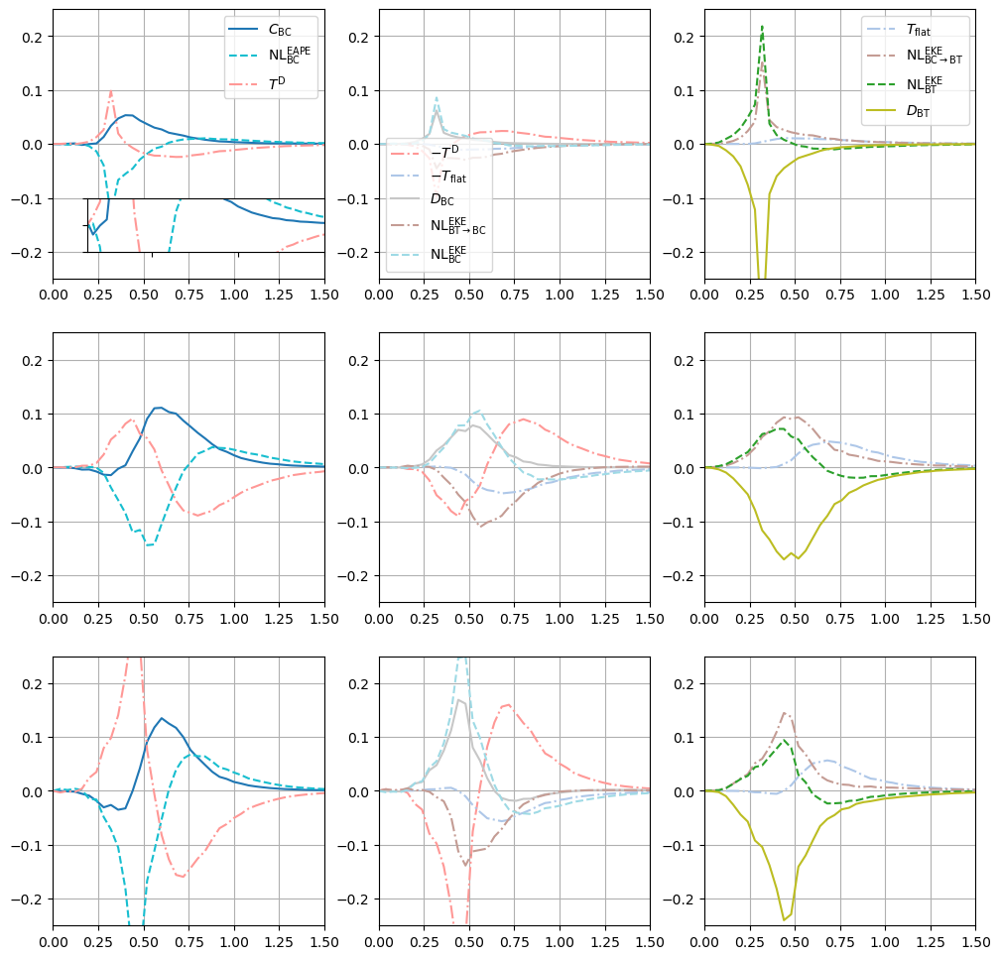

In [30]:
function plot_budget(ax1, ax2, ax3, i, j, k, legend_bool)

    h0 = (h0s[k], 0.0)
    kappa_loc = kappas[j]
    mu_loc = mus[i]
    
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
    global topo_PV, eta = define_topo(model_params)
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)

    
    beta = betas[9]

    global model_params = redef_mu_kappa_beta(model_params, mu_loc, kappa_loc, beta)
    
    a = load(data_dir*jld_name(model_params,62.95))
    

    norm = a["jld_data"]["two_layer_vBT_scale"]^-3 * Ld^-1
    
    ##############################################################
    # EAPE budget
    ##############################################################
    # trans_resid = -(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .+ 2 .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,13] )

    trans_resid = (-a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .- a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,13] )
    
    ax1.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .* norm, label=L"C_\mathrm{BC}", color=tab20_color(1), linestyle="solid")
    ax1.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,13] .* norm , label=L"\mathrm{NL}^\mathrm{EAPE}_\mathrm{BC}", color=tab20_color(19), linestyle="dashed")
    # ax1.plot(grid.kr*Ld, 2 * a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* norm , label=L"-2 \, D_\mathrm{BC}")
    ax1.plot(grid.kr*Ld, trans_resid .* norm, label=L"T^\mathrm{D}", color=tab20_color(8), linestyle="dashdot")

    if i==2
        # from mpl_toolkits.axes_grid1.inset_locator import inset_axes

        # axins = ax1.inset_axes(ax[1], width="30%", height="40%")
        axins = ax1.inset_axes([0.125, 0.1, 1-0.125, 0.2])

        axins.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .* norm, label=L"C_\mathrm{BC}", color=tab20_color(1), linestyle="solid")
        axins.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,13] .* norm , label=L"\mathrm{NL}^\mathrm{EAPE}_\mathrm{BC}", color=tab20_color(19), linestyle="dashed")
        # axins.plot(grid.kr*Ld, 2 * a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* norm , label=L"-2 \, D_\mathrm{BC}")
        axins.plot(grid.kr*Ld, trans_resid .* norm, label=L"T^\mathrm{D}", color=tab20_color(8), linestyle="dashdot")

        axins.set_xlim(0.125, 1.5)
        axins.set_ylim(-0.005, 0.005)

        axins.set_yticklabels([])
        axins.set_xticklabels([])
        
    end
    
    
    ##############################################################
    # BC EKE budget
    ##############################################################
    ax2.plot(grid.kr*Ld, -trans_resid .* norm, label=L"-T^\mathrm{D}", color=tab20_color(8), linestyle="dashdot")
    ax2.plot(grid.kr*Ld, -a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* norm, label=L"-T_\mathrm{flat}", color=tab20_color(2), linestyle="dashdot")
    # ax2.plot(grid.kr*Ld, -a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* norm , label=L"D_\mathrm{BC}")
    ax2.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* norm , label=L"D_\mathrm{BC}", color=tab20_color(16), linestyle="solid")
    ax2.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,11] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_{\mathrm{BT} \rightarrow \mathrm{BC}}", color=tab20_color(12), linestyle="dashdot")
    ax2.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_\mathrm{BC}", color=tab20_color(20), linestyle="dashed")    
    
    
    
    
    ##############################################################
    # BT EKE budget
    ##############################################################
    
    ax3.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* norm, label=L"T_\mathrm{flat}", color=tab20_color(2), linestyle="dashdot")
    ax3.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,10] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_{\mathrm{BC} \rightarrow \mathrm{BT}}", color=tab20_color(12), linestyle="dashdot")
    ax3.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_\mathrm{BT}", color=tab20_color(5), linestyle="dashed")
    ax3.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,7] .* norm , label=L"D_\mathrm{BT}", color=tab20_color(17), linestyle="solid")
    
    
    
    ax1.set_xlim(0., 1.5)
    ax2.set_xlim(0., 1.5)
    ax3.set_xlim(0., 1.5)

    ax1.set_ylim(-0.25, 0.25)
    ax2.set_ylim(-0.25, 0.25)
    ax3.set_ylim(-0.25, 0.25)

    if legend_bool==true
        ax1.legend()
        ax2.legend()
        ax3.legend()
    end

    ax1.grid()
    ax2.grid()
    ax3.grid()

    

end

###################################################################################
###################################################################################

fig,ax = plt.subplots(3,3, figsize=(12,12))

plot_budget(ax[1], ax[4], ax[7], 2, 1, 7, true)

plot_budget(ax[2], ax[5], ax[8], 4, 1, 7, false)

plot_budget(ax[3], ax[6], ax[9], 6, 1, 7, false)




8, 1
8, 2
8, 3
9, 1
9, 2
9, 3
10, 1
10, 2
10, 3


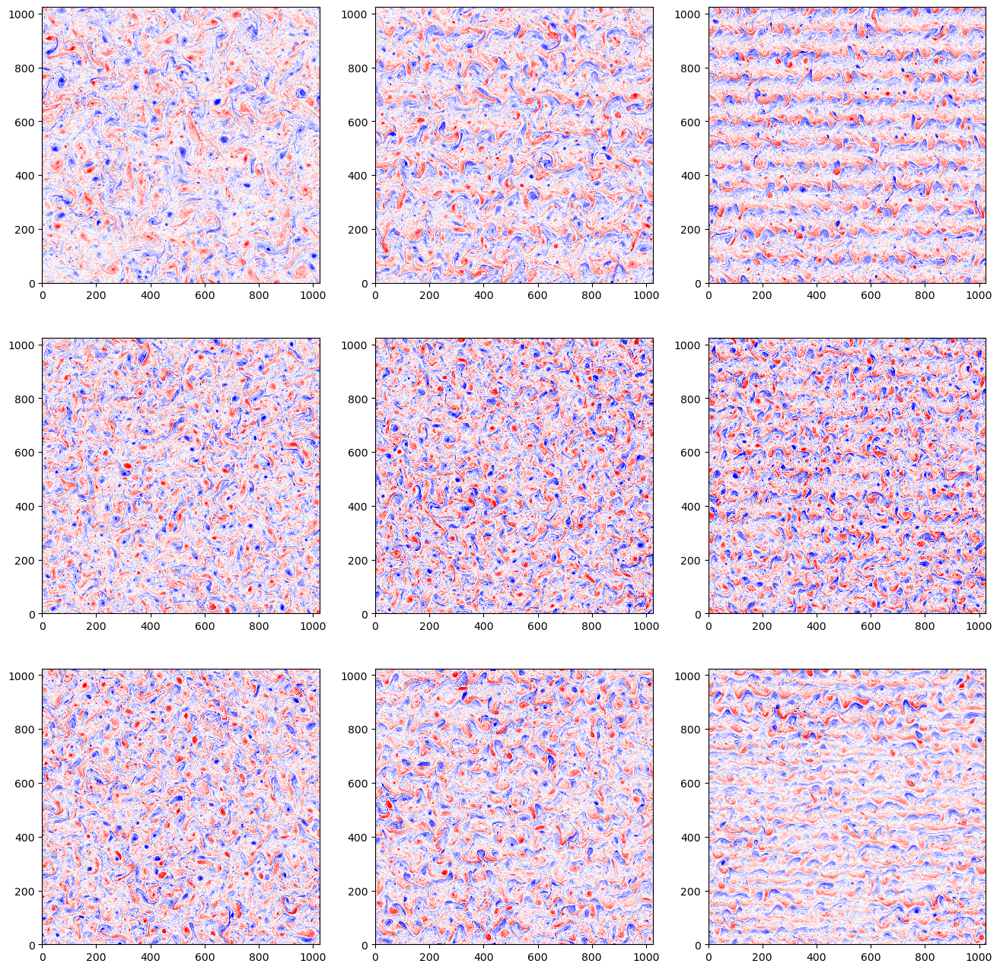

In [24]:
# Late-time snapsots of vorticity
fig, ax = plt.subplots(3,3, figsize=(16,16))

i=1
j=1
k=2


# h0 = (h0s[i], 0.0)
# kappa_loc = kappas[j]
# mu_loc = mus[k]

# global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
# global topo_PV, eta = define_topo(model_params)
# global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)

# a = load(data_dir*jld_name(model_params,62.95))
# ψ = a["jld_data"]["psi_yrs_end"]

# grid = prob.grid
        
# # assigning basic variables
# ψBC = 0.5 * (ψ[:,:,1] .- ψ[:,:,2])
# ψBT = 0.5 * (ψ[:,:,1] .+ ψ[:,:,2])

# ψBCh = deepcopy(vars.uh[:,:,1])
# ψBTh = deepcopy(vars.uh[:,:,1])

# mul2D!(ψBCh, rfftplan, ψBC)
# mul2D!(ψBTh, rfftplan, ψBT)

# ζBCh = - grid.Krsq .* ψBCh
# ζBTh = - grid.Krsq .* ψBTh

# ζBC = deepcopy(vars.u[:,:,1])
# ζBT = deepcopy(vars.u[:,:,1])

# ldiv2D!(ζBC, rfftplan, ζBCh)
# ldiv2D!(ζBT, rfftplan, ζBTh)

# h0s_zeta = [h0s[7], h0s[8], h0s[10]]

n=1

for i in range(8,10)
    for j in range(1,3)
        println(string(i)*", "*string(j))
        h0 = (0., 0.0)
        kappa_loc = kappas[1]
        mu_loc = mus[2 + 2*(j-1)]    
        
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
        global topo_PV, eta = define_topo(model_params)
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
        beta = betas[i]
        
        global model_params = redef_mu_kappa_beta(model_params, mu_loc, kappa_loc, beta)
        
        a = load(data_dir*jld_name(model_params,62.95))

        ψ = a["jld_data"]["psi_yrs_end"]
        
        grid = prob.grid
                
        # assigning basic variables
        ψBC = 0.5 * (ψ[:,:,1] .- ψ[:,:,2])
        ψBT = 0.5 * (ψ[:,:,1] .+ ψ[:,:,2])
        
        ψBCh = deepcopy(vars.uh[:,:,1])
        ψBTh = deepcopy(vars.uh[:,:,1])
        
        mul2D!(ψBCh, rfftplan, ψBC)
        mul2D!(ψBTh, rfftplan, ψBT)
        
        ζBCh = - grid.Krsq .* ψBCh
        ζBTh = - grid.Krsq .* ψBTh
        
        ζBC = deepcopy(vars.u[:,:,1])
        ζBT = deepcopy(vars.u[:,:,1])
        
        ldiv2D!(ζBC, rfftplan, ζBCh)
        ldiv2D!(ζBT, rfftplan, ζBTh)
    
        
        norm = (a["jld_data"]["two_layer_vBT_scale"] / Ld)^-1
        lim = maximum(abs.(ζBT .* norm))/2
        
        ax[n].pcolormesh((ζBT .* norm)', cmap=PyPlot.cm.bwr, vmin=-lim, vmax=lim)

        n+=1
    end
end


# kappas = @. κstars / Ld
# mus = @. μstars * ((U[1]-U[end]) / 2) / Ld


# for i in range(1,length(h0s))
#     global h0 = (h0s[i], 0.)
#     for j in range(1, length(kappas))
#         kappa_loc = kappas[j]
#         for k in range(1, length(mus))
#             mu_loc = mus[k]

#             global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
#             global topo_PV, eta = define_topo(model_params)
#             global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)

#             file1 = jld_name(model_params,1)
#             files = glob(file1[2:findfirst("yr",file1)[2]]*"*", data_dir)
            
#             N_files = round(Int, (length(files)))

#             yr_output = zeros(N_files)
#             for (i, file) in enumerate(files)
#                 yr_output[i] = parse(Float64,file[findfirst("yr",file)[2]+1:findfirst(".jld",file)[1]-1])
#             end
            
#             yr_output = sort(yr_output)

#             kap_str = @sprintf "%.3E" kappa_loc
#             mu_str = @sprintf "%.3E" mu_loc
#             h_str = "_" * topo_type * "_h0_" * (@sprintf "%.3E" h0[1])

#             if isempty(yr_output)
#                 println(kap_str * mu_str * h_str * ": " * string(0.0))
#             else
#                 println(kap_str * mu_str * h_str * ":  " * string(yr_output[end]))
#             end
#         end
#     end
# end




# energies are: (1) BTEKE, (2) BCEKE, (3) EAPE; (4) CBC; (5) Tflat, (6) Ttopo; , (7) DBT, (8) DBC;
#               (9) NLBC2BT, (10) NLBTEKE, (11) NLBT2BC; (12) NLBVEKE (13) NLBCEAPE (14) resid




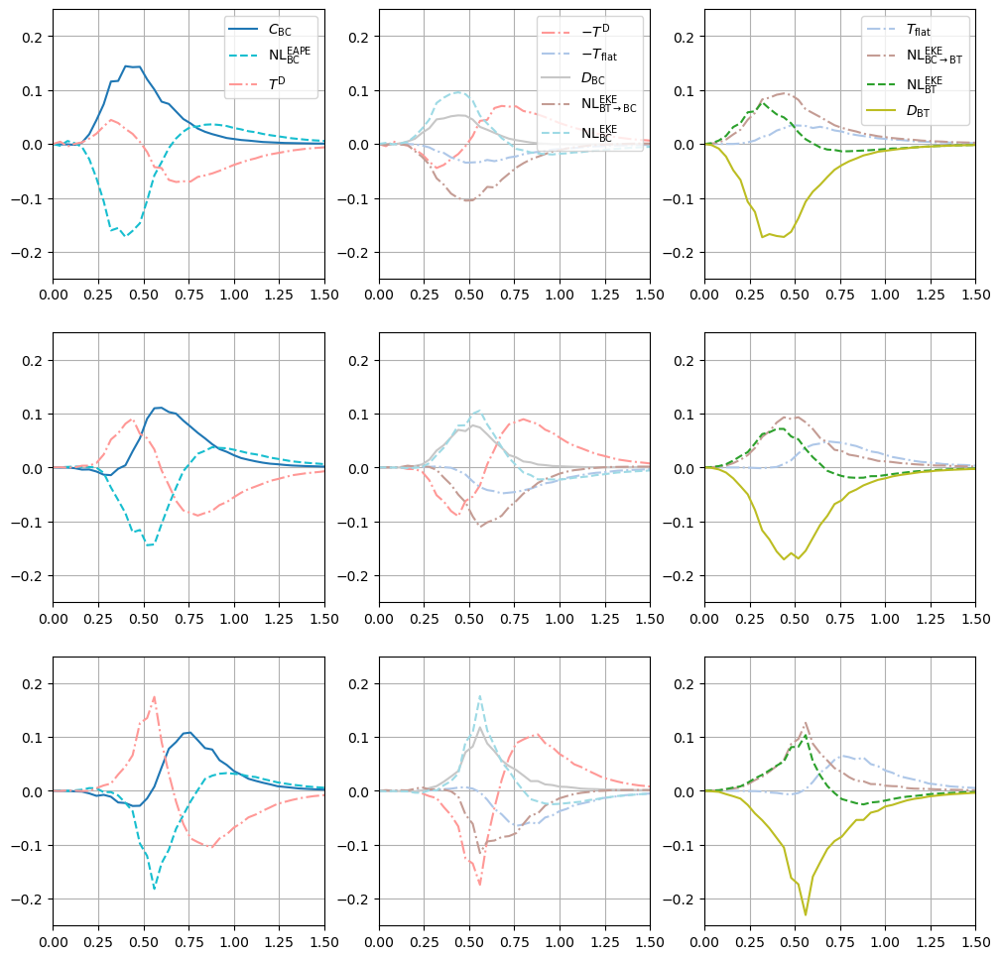

In [6]:
function plot_budget(ax1, ax2, ax3, i, j, k, legend_bool)

    h0 = (h0s[7], 0.0)
    kappa_loc = kappas[j]
    mu_loc = mus[i]
    
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
    global topo_PV, eta = define_topo(model_params)
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)

    beta = betas[k]

    global model_params = redef_mu_kappa_beta(model_params, mu_loc, kappa_loc, beta)
    
    a = load(data_dir*jld_name(model_params,62.95))
    

    norm = a["jld_data"]["two_layer_vBT_scale"]^-3 * Ld^-1
    
    ##############################################################
    # EAPE budget
    ##############################################################
    # trans_resid = -(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .+ 2 .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,13] )

    trans_resid = (-a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .- a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,13] )
    
    ax1.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .* norm, label=L"C_\mathrm{BC}", color=tab20_color(1), linestyle="solid")
    ax1.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,13] .* norm , label=L"\mathrm{NL}^\mathrm{EAPE}_\mathrm{BC}", color=tab20_color(19), linestyle="dashed")
    # ax1.plot(grid.kr*Ld, 2 * a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* norm , label=L"-2 \, D_\mathrm{BC}")
    ax1.plot(grid.kr*Ld, trans_resid .* norm, label=L"T^\mathrm{D}", color=tab20_color(8), linestyle="dashdot")

    # ax1.axvline((0.7 * a["jld_data"]["two_layer_vBT_scale"] / beta)^0.5 / (2 * pi * Ld))
    # ax1.axvline((mu_loc / a["jld_data"]["two_layer_vBT_scale"])^-1 / (2 * pi * Ld))


    # if i==2
    #     # from mpl_toolkits.axes_grid1.inset_locator import inset_axes

    #     # axins = ax1.inset_axes(ax[1], width="30%", height="40%")
    #     axins = ax1.inset_axes([0.125, 0.1, 1-0.125, 0.2])

    #     axins.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .* norm, label=L"C_\mathrm{BC}", color=tab20_color(1), linestyle="solid")
    #     axins.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,13] .* norm , label=L"\mathrm{NL}^\mathrm{EAPE}_\mathrm{BC}", color=tab20_color(19), linestyle="dashed")
    #     # axins.plot(grid.kr*Ld, 2 * a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* norm , label=L"-2 \, D_\mathrm{BC}")
    #     axins.plot(grid.kr*Ld, trans_resid .* norm, label=L"T^\mathrm{D}", color=tab20_color(8), linestyle="dashdot")

    #     axins.set_xlim(0.125, 1.5)
    #     axins.set_ylim(-0.005, 0.005)

    #     axins.set_yticklabels([])
    #     axins.set_xticklabels([])
        
    # end
    
    
    ##############################################################
    # BC EKE budget
    ##############################################################
    ax2.plot(grid.kr*Ld, -trans_resid .* norm, label=L"-T^\mathrm{D}", color=tab20_color(8), linestyle="dashdot")
    ax2.plot(grid.kr*Ld, -a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* norm, label=L"-T_\mathrm{flat}", color=tab20_color(2), linestyle="dashdot")
    # ax2.plot(grid.kr*Ld, -a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* norm , label=L"D_\mathrm{BC}")
    ax2.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* norm , label=L"D_\mathrm{BC}", color=tab20_color(16), linestyle="solid")
    ax2.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,11] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_{\mathrm{BT} \rightarrow \mathrm{BC}}", color=tab20_color(12), linestyle="dashdot")
    ax2.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_\mathrm{BC}", color=tab20_color(20), linestyle="dashed")    
    
    
    
    
    ##############################################################
    # BT EKE budget
    ##############################################################
    
    ax3.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* norm, label=L"T_\mathrm{flat}", color=tab20_color(2), linestyle="dashdot")
    ax3.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,10] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_{\mathrm{BC} \rightarrow \mathrm{BT}}", color=tab20_color(12), linestyle="dashdot")
    ax3.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_\mathrm{BT}", color=tab20_color(5), linestyle="dashed")
    ax3.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,7] .* norm , label=L"D_\mathrm{BT}", color=tab20_color(17), linestyle="solid")
    
    
    
    ax1.set_xlim(0., 1.5)
    ax2.set_xlim(0., 1.5)
    ax3.set_xlim(0., 1.5)

    ax1.set_ylim(-0.25, 0.25)
    ax2.set_ylim(-0.25, 0.25)
    ax3.set_ylim(-0.25, 0.25)

    if legend_bool==true
        ax1.legend(loc="upper right")
        ax2.legend(loc="upper right")
        ax3.legend(loc="upper right")
    end

    ax1.grid()
    ax2.grid()
    ax3.grid()

    

end

###################################################################################
###################################################################################

fig,ax = plt.subplots(3,3, figsize=(12,12))

plot_budget(ax[1], ax[4], ax[7], 4, 1, 8, true)

plot_budget(ax[2], ax[5], ax[8], 4, 1, 9, false)

plot_budget(ax[3], ax[6], ax[9], 4, 1, 10, false)


# plot_budget(ax[1], ax[4], ax[7], 2, 1, 7, true)

# plot_budget(ax[2], ax[5], ax[8], 4, 1, 7, false)

# plot_budget(ax[3], ax[6], ax[9], 6, 1, 7, false)



12-element Vector{Int64}:
  1
  2
  3
  4
  5
  6
  8
  9
 10
 11
 12
  7

plot_info_box (generic function with 1 method)

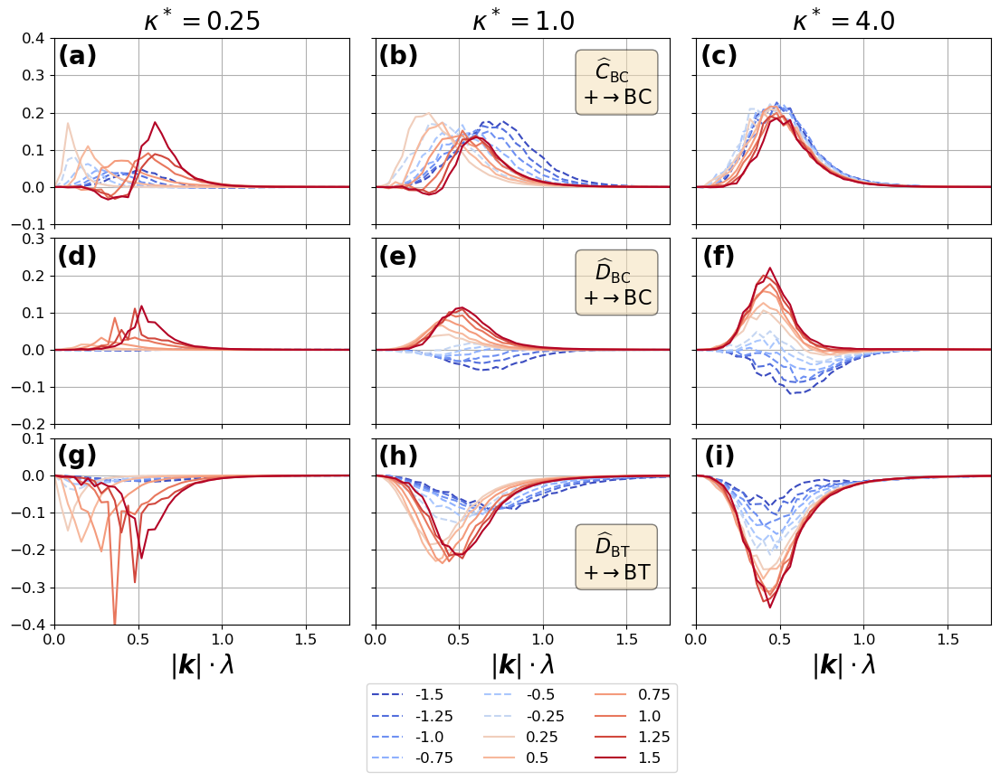

In [13]:

# a plot of KE_1 from all six combos of rho and U
fig,ax = PyPlot.subplots(3,3,figsize=(10.5, 6.5))
fig.tight_layout(pad=-1.0)

# h_ind=17
xmax_ind = 45
x = grid.kr .* Ld

fsize = 20
bsize = 16
lsize = 12


####################################################################

####################################################################

for h_ind in vcat(collect(range(1,6)), collect(range(8,13))) # length(h0s))
    if h_ind<7
        lt = "dashed"
    elseif h_ind>=7
        lt="solid"
    end

    h0 = (h0s[h_ind], 0.0)
    kappa_loc = kappas[1]
    mu_loc = mus[2]
    
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
    global topo_PV, eta = define_topo(model_params)

    # for kappa* = 1.0
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))

    ax[1].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)
    
    ax[2].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[3].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,7] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    

    # for kappa* = 1.0
    mu_loc = mus[4]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))

    ax[4].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[5].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[6].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,7] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    # for kappa* = 4.0
    mu_loc = mus[6]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))

    ax[7].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[8].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[9].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,7] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)


    GC.gc()
end


####################################################################################
ax[1].set_xticklabels([])
ax[2].set_xticklabels([])
ax[4].set_xticklabels([])
ax[5].set_xticklabels([])
ax[7].set_xticklabels([])
ax[8].set_xticklabels([])

ax[4].set_yticklabels([])
ax[5].set_yticklabels([])
ax[6].set_yticklabels([])
ax[7].set_yticklabels([])
ax[8].set_yticklabels([])
ax[9].set_yticklabels([])

ax[6].legend(fontsize=lsize, bbox_to_anchor=(1.05,-0.275), ncol=3)


ax[1].set_title(L"\kappa^* = 0.25", fontsize=fsize)
ax[4].set_title(L"\kappa^* = 1.0", fontsize=fsize)
ax[7].set_title(L"\kappa^* = 4.0", fontsize=fsize)

ax[3].set_xlabel(L" | \boldsymbol{k} | \cdot \lambda", fontsize=fsize)

ax[6].set_xlabel(L" | \boldsymbol{k} | \cdot \lambda", fontsize=fsize)

ax[9].set_xlabel(L" | \boldsymbol{k} | \cdot \lambda", fontsize=fsize)


# ax3.set_ylim(ax3.get_ylim()[1],1.2)

ax[1].text(0.075, 0.9, L"\mathbf{(a)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[1].transAxes);
ax[2].text(0.075, 0.9, L"\mathbf{(d)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[2].transAxes);
ax[3].text(0.075, 0.9, L"\mathbf{(g)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[3].transAxes);
ax[4].text(0.075, 0.9, L"\mathbf{(b)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[4].transAxes);
ax[5].text(0.075, 0.9, L"\mathbf{(e)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[5].transAxes);
ax[6].text(0.075, 0.9, L"\mathbf{(h)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[6].transAxes);
ax[7].text(0.075, 0.9, L"\mathbf{(c)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[7].transAxes);
ax[8].text(0.075, 0.9, L"\mathbf{(f)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[8].transAxes);
ax[9].text(0.075, 0.9, L"\mathbf{(i)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[9].transAxes);


ymins = [-0.1, -0.2, -0.4]
ymaxes = ymins .+ 0.5

for i in range(1,length(ax))
    
    axn = ax[i]
    axn.grid()
    axn.tick_params(labelsize=lsize)
    axn.set_xlim(x[1], x[xmax_ind])
    
end


for i in range(1,size(ax)[1])
    # ymax = maximum([ax[i].get_ylim()[2], ax[i+size(ax)[1]].get_ylim()[2]])
    # ymin = minimum([ax[i].get_ylim()[1], ax[i+size(ax)[1]].get_ylim()[1]])

    # ax[i].set_ylim(ymin, ymax)
    # ax[i+size(ax)[1]].set_ylim(ymin, ymax)

    ax[i].set_ylim(ymins[i], ymaxes[i])
    ax[i+size(ax)[1]].set_ylim(ymins[i], ymaxes[i])
    ax[i+2*size(ax)[1]].set_ylim(ymins[i], ymaxes[i])
end

# ax[3].set_ylim(ax[3].get_ylim()[1], ax[3].get_ylim()[2]+0.2)
# ax[6].set_ylim(ax[6].get_ylim()[1], ax[6].get_ylim()[2]+0.2)



###################################################################
###################################################################

plot_info_box(ax[4], L"\ \ \widehat{C}_\mathrm{BC}", 0.7, 0.9, "BC", bsize)
plot_info_box(ax[5], L"\ \ \widehat{D}_\mathrm{BC}", 0.7, 0.9, "BC", bsize)
plot_info_box(ax[6], L"\ \ \widehat{D}_\mathrm{BT}", 0.7, 0.5, "BT", bsize)


# savefig("./drag_figs/SS_kspace.pdf",bbox_inches="tight", transparent=true)



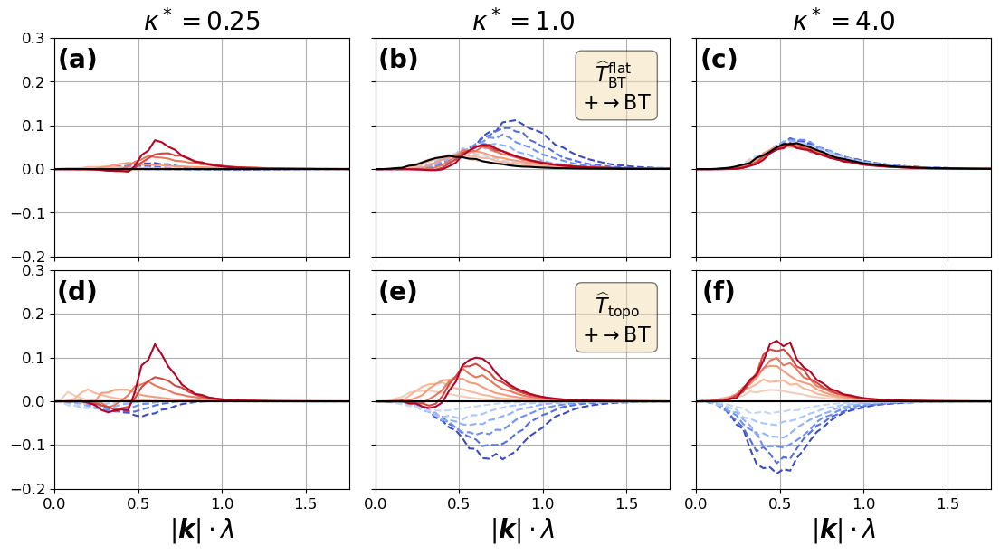

In [25]:

# a plot of KE_1 from all six combos of rho and U
fig,ax = PyPlot.subplots(2,3,figsize=(10.5,5))
fig.tight_layout(pad=-1.0)

# h_ind=17

xmax_ind = 45
x = grid.kr .* Ld

fsize = 20
bsize = 16
lsize = 12

# energies are: (1) BTEKE, (2) BCEKE, (3) EAPE; (4) CBC; (5) Tflat, (6) Ttopo; , (7) DBT, (8) DBC;
#               (9) NLBC2BT, (10) NLBTEKE, (11) NLBT2BC; (12) NLBCEKE (13) NLBCEAPE (14) resid

####################################################################

####################################################################

for h_ind in vcat(collect(range(1,6)), collect(range(8,13)), 7) # length(h0s))
    if h_ind<7
        lt = "dashed"
    elseif h_ind>=7
        lt="solid"
    end

    h0 = (h0s[h_ind], 0.0)
    kappa_loc = kappas[1]
    mu_loc = mus[1]
    
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
    global topo_PV, eta = define_topo(model_params)

    # for kappa* = 0.25
    mu_loc = mus[1]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))
    
    ax[1].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[2].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,6] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    
    # for kappa* = 1.0
    mu_loc = mus[3]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))
    
    ax[3].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[4].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,6] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)


    # kappa* = 4.0
    mu_loc = mus[5]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))

    ax[5].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[6].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,6] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)
    
    GC.gc()
end

for i in range(1,length(ax))
    
    axn = ax[i]
    axn.grid()
    axn.tick_params(labelsize=lsize)
    axn.set_xlim(x[1], x[xmax_ind])
    
end



####################################################################################

ax[1].set_xticklabels([])
ax[3].set_xticklabels([])
ax[5].set_xticklabels([])

ax[3].set_yticklabels([])
ax[4].set_yticklabels([])
ax[5].set_yticklabels([])
ax[6].set_yticklabels([])


# ax[4].legend(fontsize=lsize, bbox_to_anchor=(1.8,-0.275), ncol=3)


ax[1].set_title(L"\kappa^* = 0.25", fontsize=fsize)
ax[3].set_title(L"\kappa^* = 1.0", fontsize=fsize)
ax[5].set_title(L"\kappa^* = 4.0", fontsize=fsize)

ax[2].set_xlabel(L" | \boldsymbol{k} | \cdot \lambda", fontsize=fsize)

ax[4].set_xlabel(L" | \boldsymbol{k} | \cdot \lambda", fontsize=fsize)

ax[6].set_xlabel(L" | \boldsymbol{k} | \cdot \lambda", fontsize=fsize)

ax[1].text(0.075, 0.9, L"\mathbf{(a)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[1].transAxes);
ax[2].text(0.075, 0.9, L"\mathbf{(d)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[2].transAxes);
ax[3].text(0.075, 0.9, L"\mathbf{(b)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[3].transAxes);
ax[4].text(0.075, 0.9, L"\mathbf{(e)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[4].transAxes);
ax[5].text(0.075, 0.9, L"\mathbf{(c)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[5].transAxes);
ax[6].text(0.075, 0.9, L"\mathbf{(f)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[6].transAxes);


ymins = [-0.2, -0.2]
ymaxes = ymins .+ 0.5

for i in range(1,size(ax)[1])
    # ymax = maximum([ax[i].get_ylim()[2], ax[i+size(ax)[1]].get_ylim()[2]])
    # ymin = minimum([ax[i].get_ylim()[1], ax[i+size(ax)[1]].get_ylim()[1]])

    # ax[i].set_ylim(ymin, ymax)
    # ax[i+size(ax)[1]].set_ylim(ymin, ymax)

    ax[i].set_ylim(ymins[i], ymaxes[i])
    ax[i+size(ax)[1]].set_ylim(ymins[i], ymaxes[i])
    ax[i+2*size(ax)[1]].set_ylim(ymins[i], ymaxes[i])
end

###################################################################
###################################################################

plot_info_box(ax[3], L"\ \ \widehat{T}^\mathrm{flat}_\mathrm{BT}", 0.7, 0.9, "BT", bsize)
plot_info_box(ax[4], L"\ \ \widehat{T}_\mathrm{topo}", 0.7, 0.9, "BT", bsize)

savefig("./drag_figs/LF_kspace.pdf",bbox_inches="tight", transparent=true)


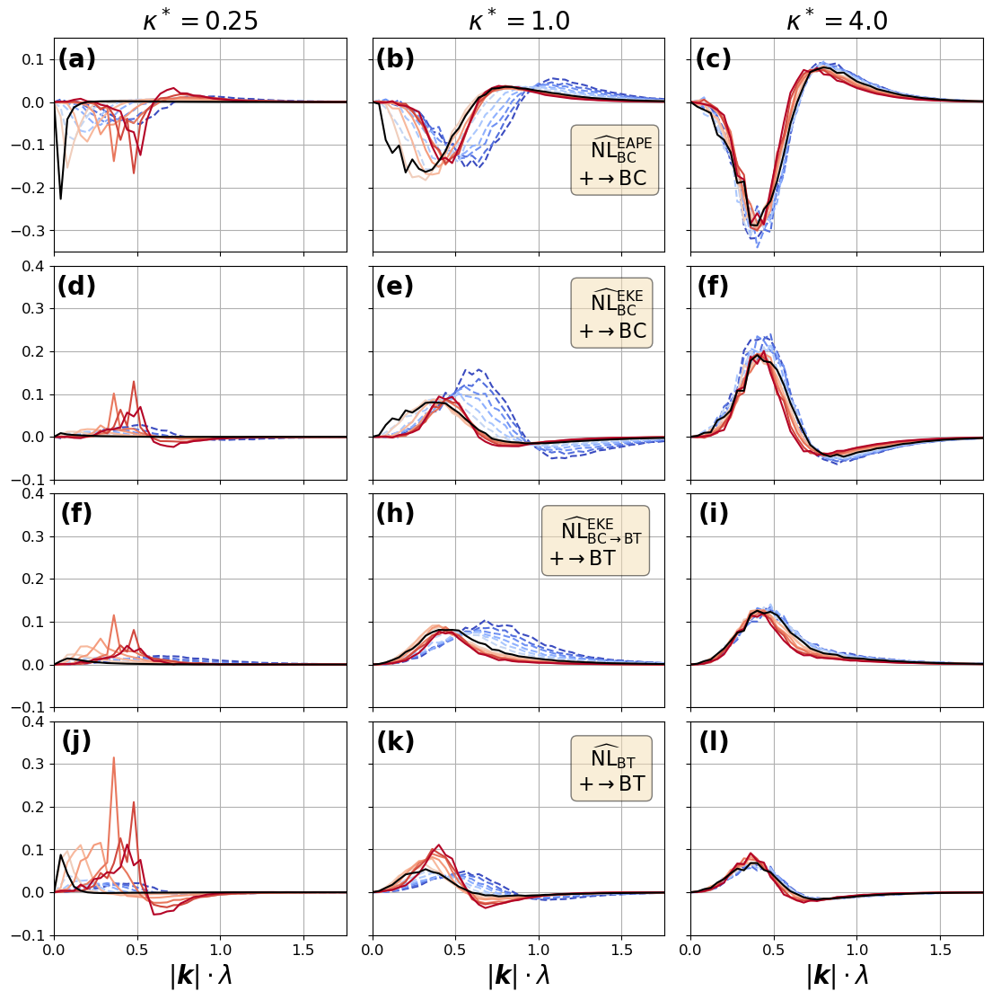

In [27]:

# a plot of KE_1 from all six combos of rho and U
fig,ax = PyPlot.subplots(4,3,figsize=(10.5,10))
fig.tight_layout(pad=-1.0)

xmax_ind = 45

x = grid.kr .* Ld

fsize = 20
bsize=16
lsize = 12

# energies are: (1) BTEKE, (2) BCEKE, (3) EAPE; (4) CBC; (5) Tflat, (6) Ttopo; , (7) DBT, (8) DBC;
#               (9) NLBTEKE, (10) NLBC2BT , (11) NLBT2BC; (12) NLBCEKE (13) NLBCEAPE (14) resid

####################################################################

####################################################################

for h_ind in vcat(collect(range(1,6)), collect(range(8,13)), 7) # length(h0s))
    # if h_ind==5
    #     axn.plot(NaN, NaN, "-", color="none", label="")
    # end
    
    if h_ind<7
        lt = "dashed"
    elseif h_ind>=7
        lt="solid"
    end


    h0 = (h0s[h_ind], 0.0)
    kappa_loc = kappas[1]
    mu_loc = mus[3]
    
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
    global topo_PV, eta = define_topo(model_params)

    # for kappa* = 0.25
    mu_loc = mus[1]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))
    
    ax[1].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,13] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[2].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    # ax[3].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,11] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)
    ax[3].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,10] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[4].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)


    # for kappa* = 1.0
    mu_loc = mus[3]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))
    
    ax[5].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,13] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[6].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    # ax[7].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,11] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)
    ax[7].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,10] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[8].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    # for kappa* = 4.0
    mu_loc = mus[5]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))

    ax[9].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,13] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[10].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    # ax[11].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,11] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)
    ax[11].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,10] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    ax[12].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9] .* (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld), label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    GC.gc()
end

for i in range(1,length(ax))
    
    axn = ax[i]
    axn.grid()
    axn.tick_params(labelsize=lsize)
    axn.set_xlim(x[1], x[xmax_ind])
    
end


####################################################################################
ax[1].set_xticklabels([])
ax[2].set_xticklabels([])
ax[3].set_xticklabels([])
ax[5].set_xticklabels([])
ax[6].set_xticklabels([])
ax[7].set_xticklabels([])
ax[9].set_xticklabels([])
ax[10].set_xticklabels([])
ax[11].set_xticklabels([])

ax[5].set_yticklabels([])
ax[6].set_yticklabels([])
ax[7].set_yticklabels([])
ax[8].set_yticklabels([])

ax[9].set_yticklabels([])
ax[10].set_yticklabels([])
ax[11].set_yticklabels([])
ax[12].set_yticklabels([])


# ax[4].legend(fontsize=lsize, bbox_to_anchor=(1.8,-0.275), ncol=3)


ax[1].set_title(L"\kappa^* = 0.25", fontsize=fsize)
ax[5].set_title(L"\kappa^* = 1.0", fontsize=fsize)
ax[9].set_title(L"\kappa^* = 4.0", fontsize=fsize)

ax[4].set_xlabel(L" | \boldsymbol{k} | \cdot \lambda", fontsize=fsize)

ax[8].set_xlabel(L" | \boldsymbol{k} | \cdot \lambda", fontsize=fsize)

ax[12].set_xlabel(L" | \boldsymbol{k} | \cdot \lambda", fontsize=fsize)


ax[1].text(0.075, 0.9, L"\mathbf{(a)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[1].transAxes);
ax[2].text(0.075, 0.9, L"\mathbf{(d)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[2].transAxes);
ax[3].text(0.075, 0.9, L"\mathbf{(f)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[3].transAxes);
ax[4].text(0.075, 0.9, L"\mathbf{(j)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[4].transAxes);
ax[5].text(0.075, 0.9, L"\mathbf{(b)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[5].transAxes);
ax[6].text(0.075, 0.9, L"\mathbf{(e)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[6].transAxes);
ax[7].text(0.075, 0.9, L"\mathbf{(h)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[7].transAxes);
ax[8].text(0.075, 0.9, L"\mathbf{(k)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[8].transAxes);
ax[9].text(0.075, 0.9, L"\mathbf{(c)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[9].transAxes);
ax[10].text(0.075, 0.9, L"\mathbf{(f)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[10].transAxes);
ax[11].text(0.075, 0.9, L"\mathbf{(i)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[11].transAxes);
ax[12].text(0.075, 0.9, L"\mathbf{(l)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[12].transAxes);


ymins = [-0.35, -0.1, -0.1, -0.1]
ymaxes = ymins .+ 0.5

for i in range(1,size(ax)[1])
    # ymax = maximum([ax[i].get_ylim()[2], ax[i+size(ax)[1]].get_ylim()[2]])
    # ymin = minimum([ax[i].get_ylim()[1], ax[i+size(ax)[1]].get_ylim()[1]])

    # ax[i].set_ylim(ymin, ymax)
    # ax[i+size(ax)[1]].set_ylim(ymin, ymax)

    ax[i].set_ylim(ymins[i], ymaxes[i])
    ax[i+size(ax)[1]].set_ylim(ymins[i], ymaxes[i])
    ax[i+2*size(ax)[1]].set_ylim(ymins[i], ymaxes[i])
end
# ax4.set_yscale("symlog")

######################################################################################
######################################################################################

plot_info_box(ax[5], L"\ \ \widehat{\mathrm{NL}}^\mathrm{EAPE}_\mathrm{BC}", 0.7, 0.55, "BC", bsize)
plot_info_box(ax[6], L"\ \ \widehat{\mathrm{NL}}^\mathrm{EKE}_\mathrm{BC}", 0.7, 0.9, "BC", bsize)
plot_info_box(ax[7], L"\ \ \widehat{\mathrm{NL}}^\mathrm{EKE}_{\mathrm{BC} \rightarrow \mathrm{BT}}", 0.6, 0.9, "BT", bsize)
plot_info_box(ax[8], L"\ \ \widehat{\mathrm{NL}}_\mathrm{BT}", 0.7, 0.9, "BT", bsize)



savefig("./drag_figs/NL_kspace.pdf",bbox_inches="tight", transparent=true)


# negative phase shifts for the positive slopes at large wavenumbers corresponds
# to the slight forward cascade seen in their spectra

# will we see same thing for flat-bottom as drag is varied?

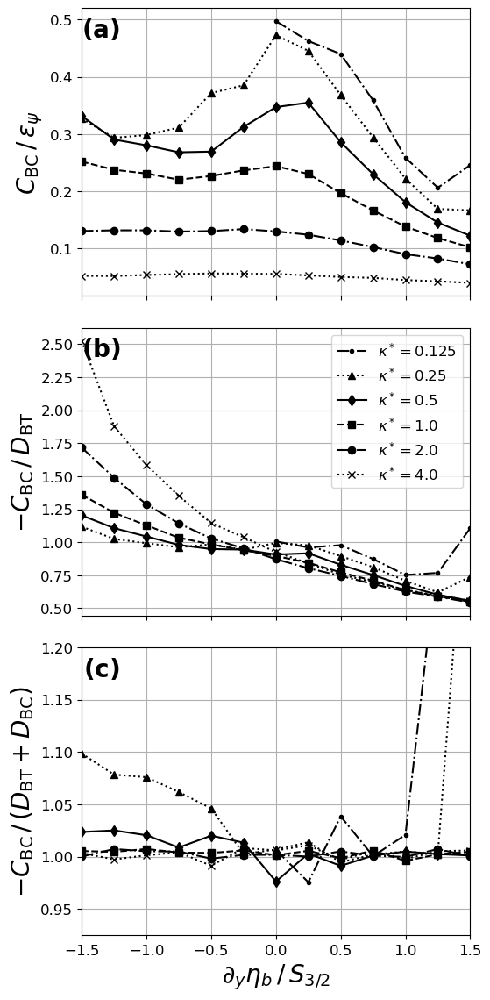

In [217]:
fig, ax = plt.subplots(3,1, figsize=(5,11))
fig.tight_layout(pad=0.5)

ax1=ax[1]; ax2=ax[2]; ax3=ax[3]

lsize = 20
tsize = 12

x = h0s ./ S32
x2 = x[7:end]

# BTKE_x, BCKE_x, BCEAPE_x, LT_x, TT_x, BC_x, NL_x, DBT_x, DBC_x, resid_x)

function define_source_sink_ratios(mu_loc)

    if mu_loc > mus[1]
        h0_range = range(1, length(h0s))

        CBC_over_eps_psi = zeros(length(h0s)) .* NaN
        CBC_over_DBT = zeros(length(h0s)) .* NaN
        CBC_over_drag_tot = zeros(length(h0s)) .* NaN
        
    else
        h0_range = range(7, length(h0s))

        CBC_over_eps_psi = zeros(length(h0s[7:end])) .* NaN
        CBC_over_DBT = zeros(length(h0s[7:end])) .* NaN
        CBC_over_drag_tot = zeros(length(h0s[7:end])) .* NaN
        
    end
    
    for (i, h_ind) in enumerate(h0_range)
    
        h0 = (h0s[h_ind], 0.0)
        kappa_loc = kappas[1]
        
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
        global topo_PV, eta = define_topo(model_params)
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
            
        a = load(data_dir*jld_name(model_params,62.95))

        xmn = a["jld_data"]["two_layer_xspace_modal_nrg_budget"]  # xspace modal nrgs (xmn)

        CBC_over_eps_psi[i] = xmn[6] / (2 * mu_loc * xmn[1])  # CBC/ eps_psi
    
        CBC_over_DBT[i] = -xmn[6] / xmn[8]          # -CBC / DBT
    
        CBC_over_drag_tot[i] = - xmn[6] / (xmn[8] + xmn[9])  # -CBC / (DBT+DBC)

    end
        
    return CBC_over_eps_psi, CBC_over_DBT, CBC_over_drag_tot
end

CBC_over_eps_psi_mu0, CBC_over_DBT_mu0, CBC_over_drag_tot_mu0 = define_source_sink_ratios(mus[1])

CBC_over_eps_psi_mu1, CBC_over_DBT_mu1, CBC_over_drag_tot_mu1 = define_source_sink_ratios(mus[2])

CBC_over_eps_psi_mu2, CBC_over_DBT_mu2, CBC_over_drag_tot_mu2 = define_source_sink_ratios(mus[3])

CBC_over_eps_psi_mu3, CBC_over_DBT_mu3, CBC_over_drag_tot_mu3 = define_source_sink_ratios(mus[4])

CBC_over_eps_psi_mu4, CBC_over_DBT_mu4, CBC_over_drag_tot_mu4 = define_source_sink_ratios(mus[5])

CBC_over_eps_psi_mu5, CBC_over_DBT_mu5, CBC_over_drag_tot_mu5 = define_source_sink_ratios(mus[6])


# for i in range(1,length(ax))
    
#     axn = ax[i]
#     axn.grid()
#     axn.tick_params(labelsize=lsize)
#     axn.set_xlim(x[1], x[end])
    
# end

#########################################################################################################
## 
#########################################################################################################

ax1.plot(x2, CBC_over_eps_psi_mu0, color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
ax1.plot(x, CBC_over_eps_psi_mu1, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
ax1.plot(x, CBC_over_eps_psi_mu2, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax1.plot(x, CBC_over_eps_psi_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
ax1.plot(x, CBC_over_eps_psi_mu4, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax1.plot(x, CBC_over_eps_psi_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")


ax1.set_ylabel(L" C_\mathrm{BC} \, / \, \epsilon_{\psi} ", fontsize=lsize)
# ax1.set_xlabel(L"\partial_y \eta_b \, / \, S_{3/2} ", fontsize=lsize)


# ax1.set_yscale("log")

ax1.set_xlim(x[1], x[end])
ax1.grid()


#########################################################################################################
## 
#########################################################################################################
ax2.plot(x2, CBC_over_DBT_mu0, color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
ax2.plot(x, CBC_over_DBT_mu1, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
ax2.plot(x, CBC_over_DBT_mu2, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax2.plot(x, CBC_over_DBT_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
ax2.plot(x, CBC_over_DBT_mu4, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax2.plot(x, CBC_over_DBT_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")


ax2.set_ylabel(L"-  C_\mathrm{BC} \, / \, D_\mathrm{BT}", fontsize=lsize)
# ax2.set_xlabel(L"\partial_y \eta_b \, / \, S_{3/2} ", fontsize=lsize)

ax2.set_xlim(x[1], x[end])
ax2.grid()


#########################################################################################################
## 
#########################################################################################################
ax3.plot(x2, CBC_over_drag_tot_mu0, color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
ax3.plot(x, CBC_over_drag_tot_mu1, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
ax3.plot(x, CBC_over_drag_tot_mu2, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax3.plot(x, CBC_over_drag_tot_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
ax3.plot(x, CBC_over_drag_tot_mu4, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax3.plot(x, CBC_over_drag_tot_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")


ax3.set_xlim(x[1], x[end])
ax3.grid()
ax3.set_ylabel(L"- C_\mathrm{BC} \, / \, \left ( D_\mathrm{BT}  + D_\mathrm{BC} \right ) ", fontsize=lsize)
ax3.set_xlabel(L"\partial_y \eta_b \, / \, S_{3/2} ", fontsize=lsize)

ax3.set_ylim(0.925, 1.2)
#########################################################################################################
## 
#########################################################################################################


ax1.text(0.05, 0.925, L"\mathbf{(a)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax1.transAxes);
ax2.text(0.05, 0.925, L"\mathbf{(b)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax2.transAxes);
ax3.text(0.05, 0.925, L"\mathbf{(c)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax3.transAxes);

ax2.legend(fontsize=tsize)


ax1.tick_params(labelsize=tsize)
ax2.tick_params(labelsize=tsize)
ax3.tick_params(labelsize=tsize)

ax1.set_xticklabels([])
ax2.set_xticklabels([]);



savefig("./drag_figs/source_sink_ratios.pdf",bbox_inches="tight")



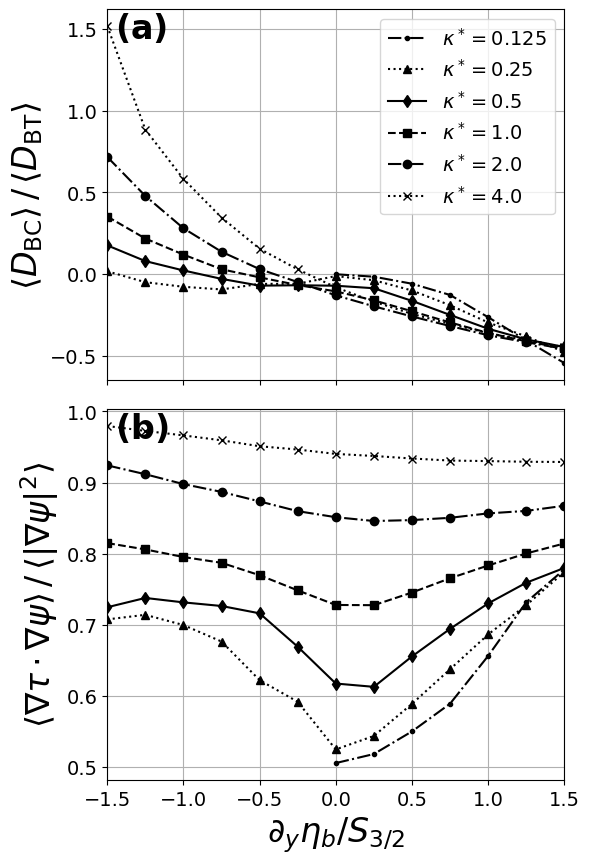

In [216]:
fig, ax = plt.subplots(2,1,figsize=(5,8))
fig.tight_layout(pad=0.0)
ax1=ax[1]; ax2=ax[2]

lsize = 24
tsize = 14

x = h0s ./ S32
x2 = x[7:end]


# (1) BTKE_x, (2) BCKE_x, (3) BCEAPE_x, (4) LT_x, (5) TT_x, (6) BC_x, (7) NL_x, (8) DBT_x, (9) DBC_x, (10) resid_x

function define_sink_ratios(mu_loc)
        
    if mu_loc > mus[1]
        h0_range = range(1, length(h0s))

        DBC_over_DBT = zeros(length(h0s)) .* NaN
        CI_over_2BT_EKE = zeros(length(h0s)) .* NaN
        
    else
        h0_range = range(7, length(h0s))

        DBC_over_DBT = zeros(length(h0s[7:end])) .* NaN
        CI_over_2BT_EKE = zeros(length(h0s[7:end])) .* NaN
        
    end
    
    for (i, h_ind) in enumerate(h0_range)
    
        h0 = (h0s[h_ind], 0.0)
        kappa_loc = kappas[1]
        
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
        global topo_PV, eta = define_topo(model_params)
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
            
        a = load(data_dir*jld_name(model_params,62.95))

        xmn = a["jld_data"]["two_layer_xspace_modal_nrg_budget"]  # xspace modal nrgs (xmn)
    
        DBC_over_DBT[i] = xmn[9] / xmn[8]          # 
    
        CI_over_2BT_EKE[i] = ((xmn[8] + 2 * mu_loc * xmn[1]) / mu_loc ) / (2 * xmn[1])  # 

    end
        
    return DBC_over_DBT, CI_over_2BT_EKE
end

DBC_over_DBT_mu0, CI_over_2BT_EKE_mu0 = define_sink_ratios(mus[1])

DBC_over_DBT_mu1, CI_over_2BT_EKE_mu1 = define_sink_ratios(mus[2])

DBC_over_DBT_mu2, CI_over_2BT_EKE_mu2 = define_sink_ratios(mus[3])

DBC_over_DBT_mu3, CI_over_2BT_EKE_mu3 = define_sink_ratios(mus[4])

DBC_over_DBT_mu4, CI_over_2BT_EKE_mu4 = define_sink_ratios(mus[5])

DBC_over_DBT_mu5, CI_over_2BT_EKE_mu5 = define_sink_ratios(mus[6])


# for i in range(1,length(ax))
    
#     axn = ax[i]
#     axn.grid()
#     axn.tick_params(labelsize=lsize)
#     axn.set_xlim(x[1], x[end])
    
# end

#########################################################################################################
## 
#########################################################################################################

ax1.plot(x2, DBC_over_DBT_mu0, color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
ax1.plot(x, DBC_over_DBT_mu1, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
ax1.plot(x, DBC_over_DBT_mu2, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax1.plot(x, DBC_over_DBT_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
ax1.plot(x, DBC_over_DBT_mu4, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax1.plot(x, DBC_over_DBT_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")

#########################################################################################################
## 
#########################################################################################################
ax2.plot(x2, CI_over_2BT_EKE_mu0, color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
ax2.plot(x, CI_over_2BT_EKE_mu1, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
ax2.plot(x, CI_over_2BT_EKE_mu2, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax2.plot(x, CI_over_2BT_EKE_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
ax2.plot(x, CI_over_2BT_EKE_mu4, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax2.plot(x, CI_over_2BT_EKE_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")

#########################################################################################################
## 
#########################################################################################################

#######################################################################################################

ax1.set_xlim(x[1], x[end])
ax1.tick_params(labelsize=tsize)
# ax2.set_xlabel(L"\partial_y \eta_b / S_{3/2}", fontsize=lsize)
ax1.grid()
ax1.set_ylabel(L"\langle D_\mathrm{BC} \rangle \,  / \, \langle D_\mathrm{BT} \rangle", fontsize=lsize)



ax2.set_xlim(x[1], x[end])
ax2.tick_params(labelsize=tsize)
ax2.set_xlabel(L"\partial_y \eta_b / S_{3/2}", fontsize=lsize)
ax2.grid()
ax2.set_ylabel(L"\langle \nabla \tau \cdot \nabla \psi \rangle \,  / \, \langle | \nabla \psi | ^2 \rangle", fontsize=lsize)

# ax2.text(-0.15, 0.5, L"\langle D_\mathrm{BC} \rangle \,  / \, \langle D_\mathrm{BT} \rangle", fontsize=lsize, rotation=90, 
#             verticalalignment="center", horizontalalignment="right", 
#             transform=ax2.transAxes)


ax1.legend(fontsize=tsize) # , bbox_to_anchor=(0.525, 0.4)) #,loc="upper left")

# ax1.set_xlabel(L"\partial_y \eta_b / S_{3/2}", fontsize=lsize)
ax1.set_xticklabels([])

# ax1.set_ylim(-0.5,1.75)
# ax2.set_ylim(0.0,1.1)

# ax1.set_yscale("log")


ax1.text(0.075, 0.95, L"\mathbf{(a)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax1.transAxes);
ax2.text(0.075, 0.95, L"\mathbf{(b)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax2.transAxes);
# ax3.text(0.075, 0.95, L"\mathbf{(c)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax3.transAxes);

#######################################################################################################

savefig("./drag_figs/cross_inv_assumptions.pdf",bbox_inches="tight")



In [213]:
function int_IC_pos(NL)
    # NL is EKE inverse cascade term for BT or BC mode
    term_sign = NL[1:end-1] .* NL[2:end]
        ind = findall(x->x<0, term_sign)
    if ind[1]<10
        if ind[2]<10
            if ind[3]<10
                is = ind[4]
            else
                is = ind[3]
            end
        else
            is = ind[2]
        end
    else
        is = ind[1]
    end
    return sum(NL[1:is])
end


DC_ratio_kap0p125 = zeros(length(h0s[7:end]))
DC_ratio_kap0p25 = zeros(length(h0s))
DC_ratio_kap0p5 = zeros(length(h0s))
DC_ratio_kap1   = zeros(length(h0s))
DC_ratio_kap2   = zeros(length(h0s))
DC_ratio_kap4   = zeros(length(h0s))

# energies are: (1) BTEKE, (2) BCEKE, (3) EAPE; (4) CBC; (5) Tflat, (6) Ttopo; , (7) DBT, (8) DBC;
#               (9) NLBTEKE, (10) NLBC2BT , (11) NLBT2BC; (12) NLBCEKE (13) NLBCEAPE (14) resid

for i in range(1, length(h0s))
    # if i>6
    #     DC_ratio_kap0p125[i-6] = int_IC_pos(NLBC_nu0_kap0p125[:,i-6,2]) / int_IC_pos(NLBT_nu0_kap0p125[:,i-6,1])
    # end

    h0 = (h0s[i], 0.0)
    kappa_loc = kappas[1]
    mu_loc = mus[1]
    
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
    global topo_PV, eta = define_topo(model_params)

    if i>6
        # kappa* = 0.125
        mu_loc = mus[1]
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
            
        a = load(data_dir*jld_name(model_params,62.95))
    
        DC_ratio_kap0p125[i-6]   = int_IC_pos(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12]) / int_IC_pos(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9])
    end
    
    # kappa* = 0.25
    mu_loc = mus[2]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))

    DC_ratio_kap0p25[i]   = int_IC_pos(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12]) / int_IC_pos(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9])


    # kappa* = 0.5
    mu_loc = mus[4]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))

    DC_ratio_kap0p5[i]   = int_IC_pos(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12]) / int_IC_pos(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9])

    # kappa* = 1.0
    mu_loc = mus[4]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))

    DC_ratio_kap1[i]   = int_IC_pos(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12]) / int_IC_pos(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9])

    # kappa* = 2.0
    mu_loc = mus[5]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))
    
    DC_ratio_kap2[i]   = int_IC_pos(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12]) / int_IC_pos(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9])
    
    
    # kappa* = 4.0
    mu_loc = mus[6]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))
    
    DC_ratio_kap4[i]   = int_IC_pos(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12]) / int_IC_pos(a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9])
    
end






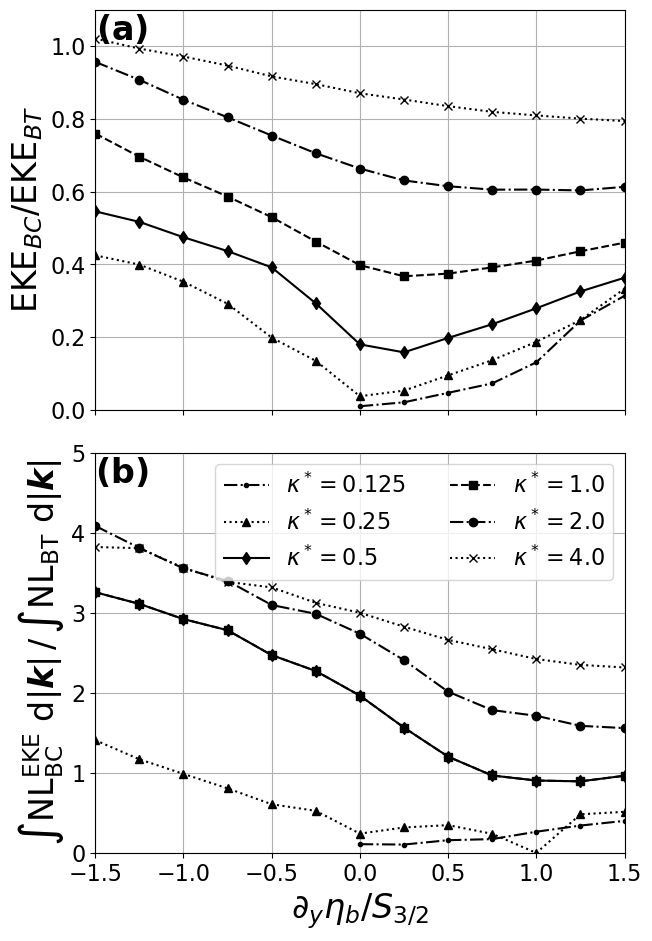

In [215]:
# fig, ax = plt.subplots(3,1, figsize=(6,13.5))
fig, ax = plt.subplots(2,1, figsize=(6,9))

fig.tight_layout(pad=1.0)

ax1=ax[1]; ax2=ax[2]; # ax3=ax[3];

lsize = 24
tsize = 16

x = h0s ./ S32
x2 = x[7:end]


# BTKE_x, BCKE_x, BCEAPE_x, LT_x, TT_x, BC_x, NL_x, DBT_x, DBC_x, resid_x)

function define_modal_nrg_ratios(mu_loc)
        
    if mu_loc > mus[1]
        h0_range = range(1, length(h0s))

        EKEBC_over_EKEBT = zeros(length(h0s)) .* NaN
        
    else
        h0_range = range(7, length(h0s))

        EKEBC_over_EKEBT = zeros(length(h0s[7:end])) .* NaN
        
    end
    
    for (i, h_ind) in enumerate(h0_range)
    
        h0 = (h0s[h_ind], 0.0)
        kappa_loc = kappas[1]
        
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
        global topo_PV, eta = define_topo(model_params)
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
            
        a = load(data_dir*jld_name(model_params,62.95))

        xmn = a["jld_data"]["two_layer_xspace_modal_nrg_budget"]  # xspace modal nrgs (xmn)
    
        EKEBC_over_EKEBT[i] = xmn[2] / xmn[1]          # 
    
    end
        
    return EKEBC_over_EKEBT
end

EKEBC_over_EKEBT_mu0 = define_modal_nrg_ratios(mus[1])

EKEBC_over_EKEBT_mu1 = define_modal_nrg_ratios(mus[2])

EKEBC_over_EKEBT_mu2 = define_modal_nrg_ratios(mus[3])

EKEBC_over_EKEBT_mu3 = define_modal_nrg_ratios(mus[4])

EKEBC_over_EKEBT_mu4 = define_modal_nrg_ratios(mus[5])

EKEBC_over_EKEBT_mu5 = define_modal_nrg_ratios(mus[6])


############################################################################
ax1.plot(x2, EKEBC_over_EKEBT_mu0, color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
ax1.plot(x, EKEBC_over_EKEBT_mu1, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
ax1.plot(x, EKEBC_over_EKEBT_mu2, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax1.plot(x, EKEBC_over_EKEBT_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
ax1.plot(x, EKEBC_over_EKEBT_mu4, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax1.plot(x, EKEBC_over_EKEBT_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")

# ax1.plot(x, BCEKE_nu0_mu1 ./ BTEKE_nu0_mu1, color="r", marker="x", linestyle="--", label=L"\mu^* = 1.0")

ax1.set_ylabel(L" \mathrm{EKE}_{BC} /  \mathrm{EKE}_{BT} ", fontsize=lsize)

ax1.set_xlim(x[1], x[end])
# ax1.set_ylim(ax1.get_ylim()[1], 1.3)  # minimum(BCEKE_nu0_kap0p25 ./ BTEKE_nu0_kap0p25), 1.3) # 
ax1.set_ylim(0.0, 1.1)

ax1.set_xticklabels([])
# ax1.set_yscale("log")

ax1.tick_params(labelsize=tsize, which="both")

# ax1.legend(fontsize=tsize)

ax1.grid()



############################################################################
# # ax2.plot(x2, BTEKE_nu0_kap0p125, color="k", marker="^", linestyle="--", label=L"\kappa^* = 0.125")
# ax2.plot(x, BTEKE_nu0_kap0p5, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
# ax2.plot(x, BTEKE_nu0_kap1, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
# ax2.plot(x, BTEKE_nu0_kap2, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
# ax2.plot(x, BTEKE_nu0_kap4, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")

# ax2.set_ylabel(L"\langle \mathrm{EKE}_{BT} \rangle \ \ [ \mathrm{m}^2 \mathrm{s}^{-2} ]", fontsize=lsize)
# # ax2.set_xticklabels([])


# ax2.set_xlim(x[1], x[end])

# ax2.set_yscale("log")

# ax2.tick_params(labelsize=tsize, which="both")
# ax2.grid()


# ax2.set_xlabel(L"\partial_y \eta_b / S_{3/2}", fontsize=lsize)

############################################################################

ax2.plot(x2, DC_ratio_kap0p125, color="k", marker=".", linestyle="-.",      label=L"\kappa^* = 0.125")
ax2.plot(x, DC_ratio_kap0p25,   color="k", marker="^", linestyle="dotted",     label=L"\kappa^* = 0.25")
ax2.plot(x, DC_ratio_kap0p5, color="k", marker="d", linestyle="-",      label=L"\kappa^* = 0.5")
ax2.plot(x, DC_ratio_kap1,   color="k", marker="s", linestyle="--",     label=L"\kappa^* = 1.0")
ax2.plot(x, DC_ratio_kap2,   color="k", marker="o", linestyle="-.",     label=L"\kappa^* = 2.0")
ax2.plot(x, DC_ratio_kap4,   color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")

ax2.set_xlim(x[1], x[end])
ax2.grid()

ax2.legend(fontsize=tsize, ncol=2)

ax2.set_ylabel(L"\int \mathrm{NL}_\mathrm{BC}^\mathrm{EKE} \ \mathrm{d} | \boldsymbol{k} | \, / \, \int  \mathrm{NL}_\mathrm{BT} \ \mathrm{d} | \boldsymbol{k} |",fontsize=lsize)
ax2.set_xlabel(L"\partial_y \eta_b / S_{3/2} ",fontsize=lsize)
# ax2.set_xticklabels([])

ax2.tick_params(labelsize=tsize, which="both")

ax2.set_ylim(0., 5)


############################################################################
############################################################################


############################################################################
############################################################################

ax1.text(0.05, 0.95, L"\mathbf{(a)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax1.transAxes);
ax2.text(0.05, 0.95, L"\mathbf{(b)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax2.transAxes);

savefig("./drag_figs/modal_nrgs.pdf",bbox_inches="tight")




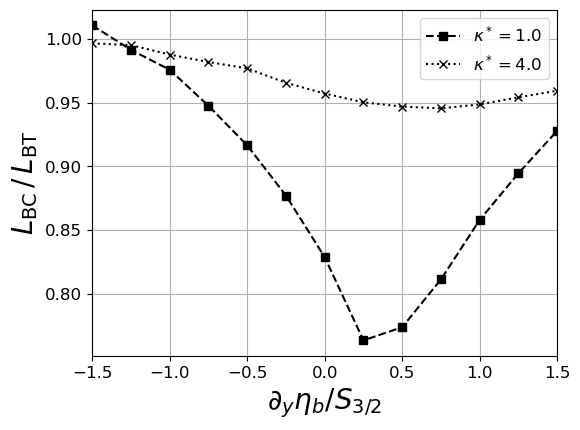

(-1.5, 1.5)

In [13]:
fig, ax2 = plt.subplots(1,1, figsize=(6,4.5))

lsize = 20
tsize = 12

x = h0s ./ S32
x2 = x[7:end-1]

############################################################################

############################################################################
function define_modal_scale_ratios(mu_loc)

    LBC_over_LBT = zeros(length(h0s)) .* NaN
        
    for h_ind in range(1, length(h0s))
    
        h0 = (h0s[h_ind], 0.0)
        kappa_loc = kappas[1]
        
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
        global topo_PV, eta = define_topo(model_params)
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
            
        a = load(data_dir*jld_name(model_params,62.95))
    
        LBC_over_LBT[h_ind] = a["jld_data"]["two_layer_modal_length_scales"][1] / a["jld_data"]["two_layer_modal_length_scales"][2]
        
    end
        
    return LBC_over_LBT
end

LBC_over_LBT_mu3 = define_modal_scale_ratios(mus[3])

LBC_over_LBT_mu5 = define_modal_scale_ratios(mus[5])



############################################################################

############################################################################

# ax2.plot(x2, LS_nu0_kap0p125[1:end-1,2] ./ LS_nu0_kap0p125[1:end-1,1], color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
# ax2.plot(x[4:end], LS_nu0_kap0p25[4:end,2] ./ LS_nu0_kap0p25[4:end,1], color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax2.plot(x, LS_nu0_kap0p5[:,2] ./ LS_nu0_kap0p5[:,1], color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax2.plot(x, LBC_over_LBT_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
# ax2.plot(x, LS_nu0_kap2[:,2] ./ LS_nu0_kap2[:,1], color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax2.plot(x,LBC_over_LBT_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")

ax2.set_ylabel(L"L_\mathrm{BC}  \, / \, L_\mathrm{BT} ", fontsize=lsize)
# ax3.set_xlabel(L"\partial_y \eta_b / S_{3/2}", fontsize=lsize)
ax2.legend(fontsize=tsize)
ax2.set_xlabel(L"\partial_y \eta_b / S_{3/2}", fontsize=lsize)

ax2.grid()

ax2.tick_params(labelsize=tsize, which="both")

# ax1.set_yscale("log")

ax2.set_xlim(x[1], x[end])





############################################################################

############################################################################

# savefig("./drag_figs/BC_BT_scale_ratio.pdf",bbox_inches="tight")


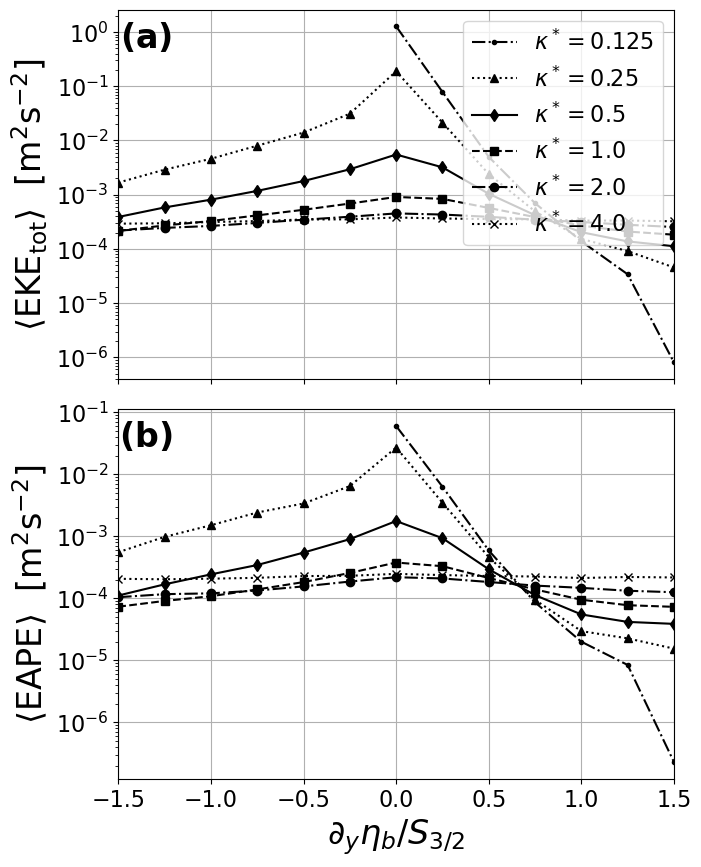

In [221]:

function define_layered_nrgs(mu_loc)

    EKE_tot = zeros(length(h0s)) .* NaN
    EAPE = zeros(length(h0s)) .* NaN
        
    if mu_loc > mus[1]
        h0_range = range(1, length(h0s))

        EKE_tot = zeros(length(h0s)) .* NaN
        EAPE = zeros(length(h0s)) .* NaN
        
    else
        h0_range = range(7, length(h0s))

        EKE_tot = zeros(length(h0s[7:end])) .* NaN
        EAPE = zeros(length(h0s[7:end])) .* NaN
        
    end
    
    for (i, h_ind) in enumerate(h0_range)
    
        h0 = (h0s[h_ind], 0.0)
        kappa_loc = kappas[1]
        
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
        global topo_PV, eta = define_topo(model_params)
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
            
        a = load(data_dir*jld_name(model_params,62.95))

        xmn = a["jld_data"]["two_layer_xspace_nrgs_ot"]  # xspace modal nrgs (xmn)
    
        EKE_tot[i] = mean(xmn[1,:]) + mean(xmn[2,:])          # 

        EAPE[i] = mean(xmn[3,:])
    
    end
        
    return EKE_tot, EAPE
end

EKE_tot_mu0, EAPE_mu0 = define_layered_nrgs(mus[1])

EKE_tot_mu1, EAPE_mu1 = define_layered_nrgs(mus[2])

EKE_tot_mu2, EAPE_mu2 = define_layered_nrgs(mus[3])

EKE_tot_mu3, EAPE_mu3 = define_layered_nrgs(mus[4])

EKE_tot_mu4, EAPE_mu4 = define_layered_nrgs(mus[5])

EKE_tot_mu5, EAPE_mu5 = define_layered_nrgs(mus[6])


############################################################################
fig, ax = plt.subplots(2,1, figsize=(6,8))
fig.tight_layout(pad=0.05)

ax1=ax[1]; ax3=ax[2]; # ax3=ax[3];

lsize = 24
tsize = 16

x = h0s ./ S32
x2 = x[7:end]

############################################################################
ax1.plot(x2, EKE_tot_mu0, color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
ax1.plot(x, EKE_tot_mu1, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
ax1.plot(x, EKE_tot_mu2, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax1.plot(x, EKE_tot_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
ax1.plot(x, EKE_tot_mu4, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax1.plot(x, EKE_tot_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")


ax1.set_ylabel(L"\langle \mathrm{EKE}_\mathrm{tot} \rangle \ \ [ \mathrm{m}^2 \mathrm{s}^{-2} ]", fontsize=lsize)

ax1.set_xlim(x[1], x[end])

ax1.set_xticklabels([])
ax1.tick_params(labelsize=tsize, which="both")


ax1.set_yscale("log")
ax1.grid()

# ############################################################################
# # ax2.plot(x2, EKE12_nu0_kap0p125[:,1] ./ EKE12_nu0_kap0p125[:,2], color="k", marker="^", linestyle="--", label=L"\kappa^* = 0.125")
# ax2.plot(x, EKE12_nu0_kap0p5[:,1] ./ EKE12_nu0_kap0p5[:,2], color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
# ax2.plot(x, EKE12_nu0_kap1[:,1] ./ EKE12_nu0_kap1[:,2], color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
# ax2.plot(x, EKE12_nu0_kap2[:,1] ./ EKE12_nu0_kap2[:,2], color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
# ax2.plot(x, EKE12_nu0_kap4[:,1] ./ EKE12_nu0_kap4[:,2], color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")

# ax2.set_ylabel(L"\langle \mathrm{EKE}_{1} \rangle / \langle \mathrm{EKE}_{2} \rangle", fontsize=lsize)
# ax2.set_xticklabels([])


# ax2.set_xlim(x[1], x[end])

# ax2.tick_params(labelsize=tsize, which="both")

# ax2.set_yscale("log")
# ax2.grid()

############################################################################
ax3.plot(x2, EAPE_mu0, color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
ax3.plot(x, EAPE_mu1, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
ax3.plot(x, EAPE_mu2, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax3.plot(x, EAPE_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
ax3.plot(x, EAPE_mu4, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax3.plot(x, EAPE_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")


ax3.set_ylabel(L"\langle \mathrm{EAPE} \rangle \ \ [ \mathrm{m}^2 \mathrm{s}^{-2} ]", fontsize=lsize)

ax3.set_xlabel(L"\partial_y \eta_b / S_{3/2}", fontsize=lsize)

ax3.set_xlim(x[1], x[end])

ax3.tick_params(labelsize=tsize, which="both")
ax3.set_yscale("log")
ax3.grid()

############################################################################
ax1.legend(fontsize=tsize, loc="upper right")

ax1.text(0.05, 0.925, L"\mathbf{(a)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax1.transAxes);
# ax2.text(0.05, 0.95, L"\mathbf{(b)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax2.transAxes);
ax3.text(0.05, 0.925, L"\mathbf{(b)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax3.transAxes);

# savefig("./drag_figs/total_nrgs.pdf",bbox_inches="tight")




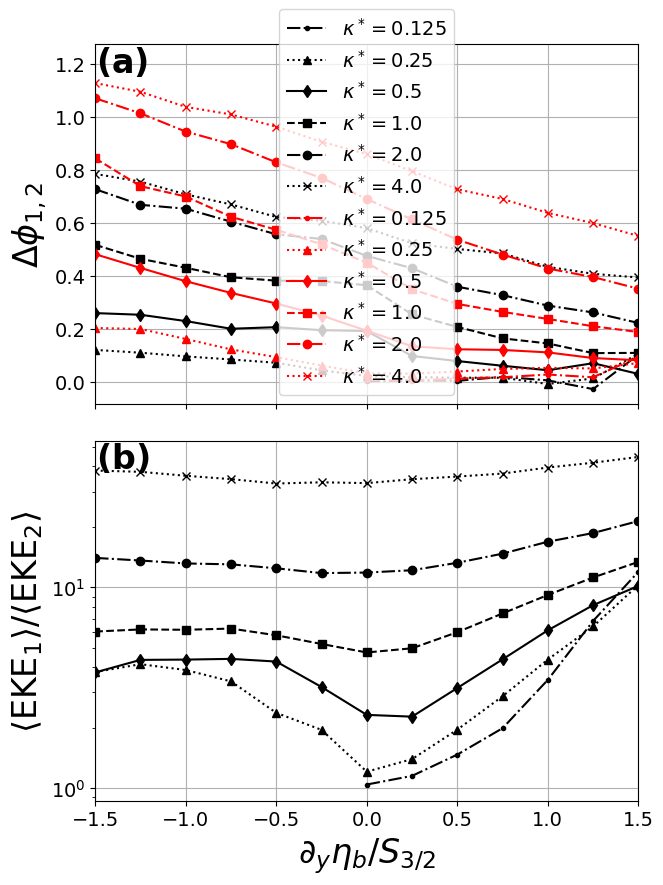

In [223]:

function define_layered_ratio_and_phases(mu_loc)
            
    if mu_loc > mus[1]
        h0_range = range(1, length(h0s))

        EKE1_over_EKE2 = zeros(length(h0s)) .* NaN
        ph_iso = zeros(length(h0s)) .* NaN
        ph_zonal = zeros(length(h0s)) .* NaN
            
    else
        h0_range = range(7, length(h0s))

        EKE1_over_EKE2 = zeros(length(h0s[7:end])) .* NaN
        ph_iso = zeros(length(h0s[7:end])) .* NaN
        ph_zonal = zeros(length(h0s[7:end])) .* NaN
            
    end
    
    for (i, h_ind) in enumerate(h0_range)
    
    
        h0 = (h0s[h_ind], 0.0)
        kappa_loc = kappas[1]
        
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
        global topo_PV, eta = define_topo(model_params)
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
            
        a = load(data_dir*jld_name(model_params,62.95))

        xmn = a["jld_data"]["two_layer_xspace_nrgs_ot"]  # xspace modal nrgs (xmn)
    
        EKE1_over_EKE2[i] = mean(xmn[1,:]) / mean(xmn[2,:])          # 

        ph_iso[i] = a["jld_data"]["ph_iso"]

        ph_zonal[i] = a["jld_data"]["ph_slices"]
    
    end
        
    return EKE1_over_EKE2, ph_iso, ph_zonal
end

EKE1_over_EKE2_mu0, ph_iso_mu0, ph_zonal_mu0 = define_layered_ratio_and_phases(mus[1])

EKE1_over_EKE2_mu1, ph_iso_mu1, ph_zonal_mu1 = define_layered_ratio_and_phases(mus[2])

EKE1_over_EKE2_mu2, ph_iso_mu2, ph_zonal_mu2 = define_layered_ratio_and_phases(mus[3])

EKE1_over_EKE2_mu3, ph_iso_mu3, ph_zonal_mu3 = define_layered_ratio_and_phases(mus[4])

EKE1_over_EKE2_mu4, ph_iso_mu4, ph_zonal_mu4 = define_layered_ratio_and_phases(mus[5])

EKE1_over_EKE2_mu5, ph_iso_mu5, ph_zonal_mu5 = define_layered_ratio_and_phases(mus[6])


#################################################################################
##


fig, ax = plt.subplots(2,1,figsize=(6,8))
fig.tight_layout(pad=0.5)
ax1=ax[1]; ax2=ax[2];

lsize = 24
tsize = 14

x = h0s ./ S32
x2 =x[7:end]

############################################################################
##
#######################################################################################################
ax1.plot(x2, ph_iso_mu0, color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
ax1.plot(x, ph_iso_mu1, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
ax1.plot(x, ph_iso_mu2, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax1.plot(x, ph_iso_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
ax1.plot(x, ph_iso_mu4, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax1.plot(x, ph_iso_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")


ax1.plot(x2, ph_zonal_mu0, color="r", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
ax1.plot(x, ph_zonal_mu1, color="r", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
ax1.plot(x, ph_zonal_mu2, color="r", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax1.plot(x, ph_zonal_mu3, color="r", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
ax1.plot(x, ph_zonal_mu4, color="r", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax1.plot(x, ph_zonal_mu5, color="r", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")


ax1.set_ylabel(L"\Delta \phi_{1,2}", fontsize=lsize)

ax1.set_xlim(x[1], x[end])
ax1.set_ylim(ax1.get_ylim()[1], 1.275)

ax1.set_xticklabels([])
ax1.tick_params(labelsize=tsize)

ax1.legend(fontsize=tsize)
ax1.grid()

# #######################################################################################################
##
############################################################################
ax2.plot(x2, EKE1_over_EKE2_mu0, color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
ax2.plot(x, EKE1_over_EKE2_mu1, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
ax2.plot(x, EKE1_over_EKE2_mu2, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax2.plot(x, EKE1_over_EKE2_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
ax2.plot(x, EKE1_over_EKE2_mu4, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax2.plot(x, EKE1_over_EKE2_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")

ax2.set_ylabel(L"\langle \mathrm{EKE}_{1} \rangle / \langle \mathrm{EKE}_{2} \rangle", fontsize=lsize)
# ax2.set_xticklabels([])


ax2.set_xlim(x[1], x[end])

ax2.tick_params(labelsize=tsize, which="both")

ax2.set_yscale("log")
ax2.grid()
ax2.set_xlabel(L"\partial_y \eta_b / S_{3/2}", fontsize=lsize)



#######################################################################################################

ax1.text(0.05, 0.95, L"\mathbf{(a)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax1.transAxes);
ax2.text(0.05, 0.95, L"\mathbf{(b)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax2.transAxes);

# savefig("./drag_figs/layered_vert_struc.pdf",bbox_inches="tight")





sys:1: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.


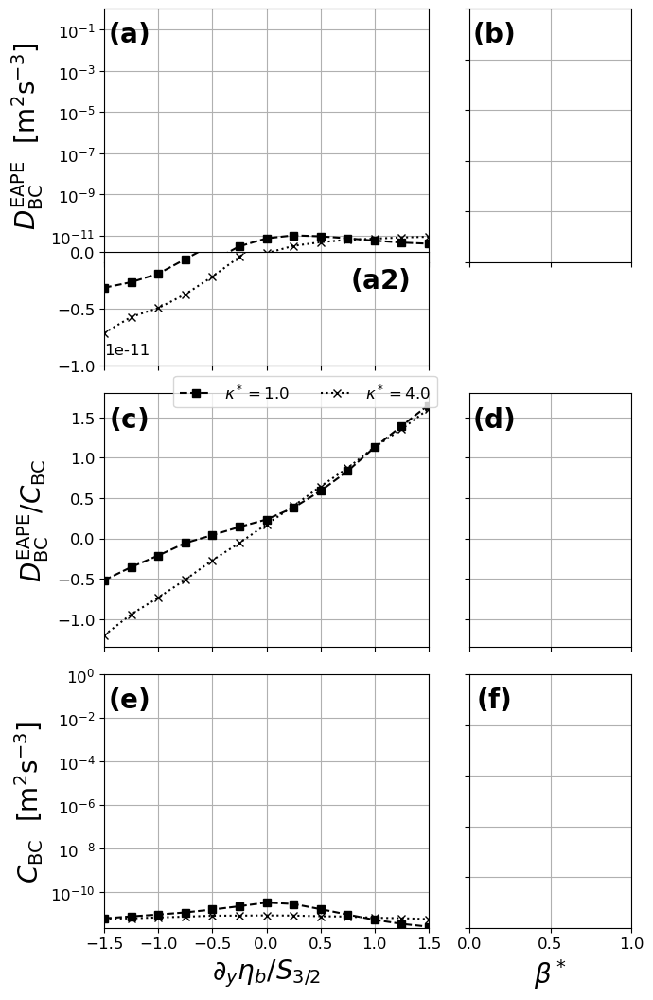

PyObject Text(47.66562499999999, 0.5, '$C_\\mathrm{BC} \\ \\ [ \\mathrm{m}^2 \\mathrm{s}^{-3} ]$')

In [16]:
using FileIO, JLD2

# fn = data_dir*"modal_nrg_budget_xspace_nu0_kap1_betas.jld"

# a = load(fn);

# for (k,v) in a["jld_data"]
#     @eval $(Symbol(k)) = $(v)
# end

########################################################################3
# BETAS
########################################################################3
##########################################################################
fig, ax = plt.subplots(4,2, figsize=(6,10), width_ratios=[2.,1.], height_ratios=[1.,0.3,1.,1.])
fig.tight_layout(pad=0.0)

ax1=ax[5]; ax2=ax[7]; ax3=ax[8]

ax[6].axis("off")

lsize = 20
tsize = 12

# x = betas ./ ((U[1]/2) * Ld^-2)



# ############################################################################
# ax1.plot(x[1:end-1], 2 * DS_nu0_kap0p125[1:end-1, 2] , color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
# ax1.plot(x, 2 * DS_nu0_kap0p25[:, 2] , color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax1.plot(x, 2 * DS_nu0_kap0p5[:, 2], color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
# ax1.plot(x, 2 * DS_nu0_kap1[:, 2], color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")


# ax1.set_yscale("log")


# ############################################################################
# ax2.plot(x[1:end-1], 2 * DS_nu0_kap0p125[1:end-1, 2] ./ BC_nu0_kap0p125[1:end-1], color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
# ax2.plot(x, 2 * DS_nu0_kap0p25[:, 2] ./ BC_nu0_kap0p25, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax2.plot(x, 2 * DS_nu0_kap0p5[:, 2] ./ BC_nu0_kap0p5, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
# ax2.plot(x, 2 * DS_nu0_kap1[:, 2] ./ BC_nu0_kap1, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")


# ############################################################################
# ax3.plot(x[1:end-1], BC_nu0_kap0p125[1:end-1], color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
# ax3.plot(x, BC_nu0_kap0p25, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax3.plot(x, BC_nu0_kap0p5, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
# ax3.plot(x, BC_nu0_kap1, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")



# ax3.set_yscale("log")


# ############################################################################

ax1.set_xticklabels([])
ax2.set_xticklabels([])

ax1.set_yticklabels([])
ax2.set_yticklabels([])
ax3.set_yticklabels([])


# ax1.set_xlim(x[1], x[end])
# ax2.set_xlim(x[1], x[end])
# ax3.set_xlim(x[1], x[end])


ax1.tick_params(labelsize=tsize)
ax2.tick_params(labelsize=tsize)
ax3.tick_params(labelsize=tsize)

# ax3.set_yscale("log")

ax1.yaxis.offsetText.set(size=tsize)
ax2.yaxis.offsetText.set(size=tsize)
ax3.yaxis.offsetText.set(size=tsize)

ax1.grid()
ax2.grid()
ax3.grid()

ax3.set_xlabel(L"\beta^*", fontsize=lsize)

ax1.text(0.15, 0.9, L"\mathbf{(b)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax1.transAxes);
ax2.text(0.15, 0.9, L"\mathbf{(d)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax2.transAxes);
ax3.text(0.15, 0.9, L"\mathbf{(f)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax3.transAxes);


############################################################################

############################################################################

############################################################################

############################################################################

####################################################################

####################################################################

############################################################################

############################################################################

############################################################################

# BTKE_x, BCKE_x, BCEAPE_x, LT_x, TT_x, BC_x, NL_x, DBT_x, DBC_x, resid_x)

function define_xspace_modal_nrg_terms(mu_loc)

    CBC = zeros(length(h0s)) .* NaN
    DBC_over_CBC = zeros(length(h0s)) .* NaN
    DBC = zeros(length(h0s)) .* NaN
        
    for h_ind in range(1, length(h0s))
    
        h0 = (h0s[h_ind], 0.0)
        kappa_loc = kappas[1]
        
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
        global topo_PV, eta = define_topo(model_params)
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
            
        a = load(data_dir*jld_name(model_params,62.95))

        xmn = a["jld_data"]["two_layer_xspace_modal_nrg_budget"]  # xspace modal nrgs (xmn)
    
        CBC[h_ind] = xmn[6]
        DBC_over_CBC[h_ind] = 2 * xmn[9] / xmn[6]
        DBC[h_ind] = 2 * xmn[9]

    end
        
    return CBC, DBC_over_CBC, DBC
end

CBC_mu3, DBC_over_CBC_mu3, DBC_mu3 = define_xspace_modal_nrg_terms(mus[3])

CBC_mu5, DBC_over_CBC_mu5, DBC_mu5 = define_xspace_modal_nrg_terms(mus[5])


############################################################################

############################################################################


ax1=ax[1]; ax1b=ax[2]; ax2=ax[3]; ax3=ax[4];

x= h0s ./ S32
x2 = x[7:end]

ax1b.axis("off")

############################################################################

# ax1.plot(x2[1:end-1], 2 * DS_nu0_kap0p125[1:end-1, 2] , color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
# ax1.plot(x[4:end], 2 * DS_nu0_kap0p25[4:end, 2] , color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax1.plot(x[4:end], 2 * DS_nu0_kap0p5[4:end, 2], color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax1.plot(x[5:end], DBC_mu3[5:end], color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
# ax1.plot(x[6:end], 2 * DS_nu0_kap2[6:end, 2], color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax1.plot(x[7:end], DBC_mu5[7:end], color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")


# ax2.plot(x, TT_nu0_kap2 ./ BC_nu0_kap2, color="k", marker="o", linestyle="--", label=L"\kappa^* = 2.0")
# ax2.plot(x, TT_nu0_kap1 ./ BC_nu0_kap1, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
# ax2.plot(x, TT_nu0_kap0p5 ./ BC_nu0_kap0p5, color="k", marker="d", linestyle="--", label=L"\kappa^* = 0.5")


# ax1.set_ylabel(L"D_\mathrm{BC, \, EAPE} \ \ [ \mathrm{m}^2 \mathrm{s}^{-3} ]", fontsize=lsize)
# ax3.set_xlabel(L"\partial_y \eta_b / S_{3/2}", fontsize=lsize)
# ax1.legend(fontsize=tsize)

ax1.set_yscale("log")

############################################################################


pos = ax1b.get_position().get_points()  # [[xmin, ymin], [xmax, ymax]]

left = pos[1,1]
bottom = pos[1,2]

width = pos[2,1] - left
height = pos[2,2] - bottom

ax1b = fig.add_axes([left, bottom, width, height*1.5])


# ax1b.plot(x2[1:end-3], 2 * DS_nu0_kap0p125[1:end-3, 2] , color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
# ax1b.plot(x[4:end], 2 * DS_nu0_kap0p25[4:end, 2] , color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax1b.plot(x[1:end-3], 2 * DS_nu0_kap0p5[1:end-3, 2], color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax1b.plot(x[1:end-3], DBC_mu3[1:end-3], color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
# ax1b.plot(x[1:end-3], 2 * DS_nu0_kap2[1:end-3, 2], color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax1b.plot(x[1:end-3], DBC_mu5[1:end-3], color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")

ax1b.set_ylim(-1.e-11, 0.)

# ax1b.ticklabel_format(axis="y", style="sci", scilimits=(0,0))

# ax1b.get_yaxis().set_major_formatter(plt.LogFormatter(10,  labelOnlyBase=false))

# ax1b.yaxis.get_offset_text().set_position((0.,-1000))
ax1b.yaxis.get_offset_text().set_visible(false)
ax1b.text(0.0,0.1, "1e-11", fontsize=tsize, transform = ax1b.transAxes)


############################################################################
# ax2.plot(x2[1:end-1], 2 * DS_nu0_kap0p125[1:end-1, 2] ./ BC_nu0_kap0p125[1:end-1], color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
# ax2.plot(x[4:end], 2 * DS_nu0_kap0p25[4:end, 2] ./ BC_nu0_kap0p25[4:end], color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax2.plot(x, 2 * DS_nu0_kap0p5[:, 2] ./ BC_nu0_kap0p5, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax2.plot(x, DBC_over_CBC_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
# ax2.plot(x, 2 * DS_nu0_kap2[:, 2] ./ BC_nu0_kap2, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax2.plot(x, DBC_over_CBC_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")



# ax2.plot(x, TT_nu0_kap2 ./ BC_nu0_kap2, color="k", marker="o", linestyle="--", label=L"\kappa^* = 2.0")
# ax2.plot(x, TT_nu0_kap1 ./ BC_nu0_kap1, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
# ax2.plot(x, TT_nu0_kap0p5 ./ BC_nu0_kap0p5, color="k", marker="d", linestyle="--", label=L"\kappa^* = 0.5")


# ax2.set_ylabel(L"D_\mathrm{BC, \, EAPE} / C_\mathrm{BC}", fontsize=lsize)
# ax3.set_xlabel(L"\partial_y \eta_b / S_{3/2}", fontsize=lsize)



############################################################################
# ax3.plot(x2[1:end-1], BC_nu0_kap0p125[1:end-1], color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
# ax3.plot(x[4:end], BC_nu0_kap0p25[4:end], color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax3.plot(x, BC_nu0_kap0p5, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax3.plot(x, CBC_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
# ax3.plot(x, BC_nu0_kap2, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax3.plot(x, CBC_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")


ax3.set_yscale("log")

# ax3.set_ylabel(L"C_\mathrm{BC} \ \ [ \mathrm{m}^2 \mathrm{s}^{-3} ]", fontsize=lsize)



############################################################################
ax2.legend(loc="upper right", fontsize=tsize, ncol=2,bbox_to_anchor=(1.05,1.1))

ax1.set_xticklabels([])
ax1b.set_xticklabels([])
ax2.set_xticklabels([])


ax1.set_xlim(x[1], x[end])
ax1b.set_xlim(x[1], x[end])
ax2.set_xlim(x[1], x[end])
ax3.set_xlim(x[1], x[end])


ax1.tick_params(labelsize=tsize)
ax1b.tick_params(labelsize=tsize)
ax2.tick_params(labelsize=tsize)
ax3.tick_params(labelsize=tsize)

ax1.yaxis.offsetText.set(size=tsize)
ax1b.yaxis.offsetText.set(size=tsize)
ax2.yaxis.offsetText.set(size=tsize)
ax3.yaxis.offsetText.set(size=tsize)

ax1.grid()
ax1b.grid()
ax2.grid()
ax3.grid()

ax3.set_xlabel(L"\partial_y \eta_b / S_{3/2}", fontsize=lsize)

ax1.text(0.075, 0.9, L"\mathbf{(a)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax1.transAxes);
ax1b.text(0.85, 0.75, L"\mathbf{(a2)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax1b.transAxes);
ax2.text(0.075, 0.9, L"\mathbf{(c)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax2.transAxes);
ax3.text(0.075, 0.9, L"\mathbf{(e)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax3.transAxes);


r1_ymin = minimum([ax[1].get_ylim()[1], ax[5].get_ylim()[1]])
r1_ymax = maximum([ax[1].get_ylim()[2], ax[5].get_ylim()[2]]); # r1_ymax = 3e-11
r2_ymin = minimum([ax[3].get_ylim()[1], ax[7].get_ylim()[1]])
r2_ymax = maximum([ax[3].get_ylim()[2], ax[7].get_ylim()[2]])
r3_ymin = minimum([ax[4].get_ylim()[1], ax[8].get_ylim()[1]])
r3_ymax = maximum([ax[4].get_ylim()[2], ax[8].get_ylim()[2]])



ax[1].set_ylim(r1_ymin, r1_ymax)
ax[3].set_ylim(r2_ymin, r2_ymax)
ax[4].set_ylim(r3_ymin, r3_ymax)
ax[5].set_ylim(r1_ymin, r1_ymax)
ax[7].set_ylim(r2_ymin, r2_ymax)
ax[8].set_ylim(r3_ymin, r3_ymax)


ax1.set_ylabel(L"D_\mathrm{BC}^\mathrm{EAPE} \ \ [ \mathrm{m}^2 \mathrm{s}^{-3} ]", fontsize=lsize)

ax2.set_ylabel(L"D_\mathrm{BC}^\mathrm{EAPE} / C_\mathrm{BC}", fontsize=lsize)
ax3.set_ylabel(L"C_\mathrm{BC} \ \ [ \mathrm{m}^2 \mathrm{s}^{-3} ]", fontsize=lsize)



# savefig("./drag_figs/modal_xspace_budget_terms_beta_merged.pdf",bbox_inches="tight")




sys:1: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.


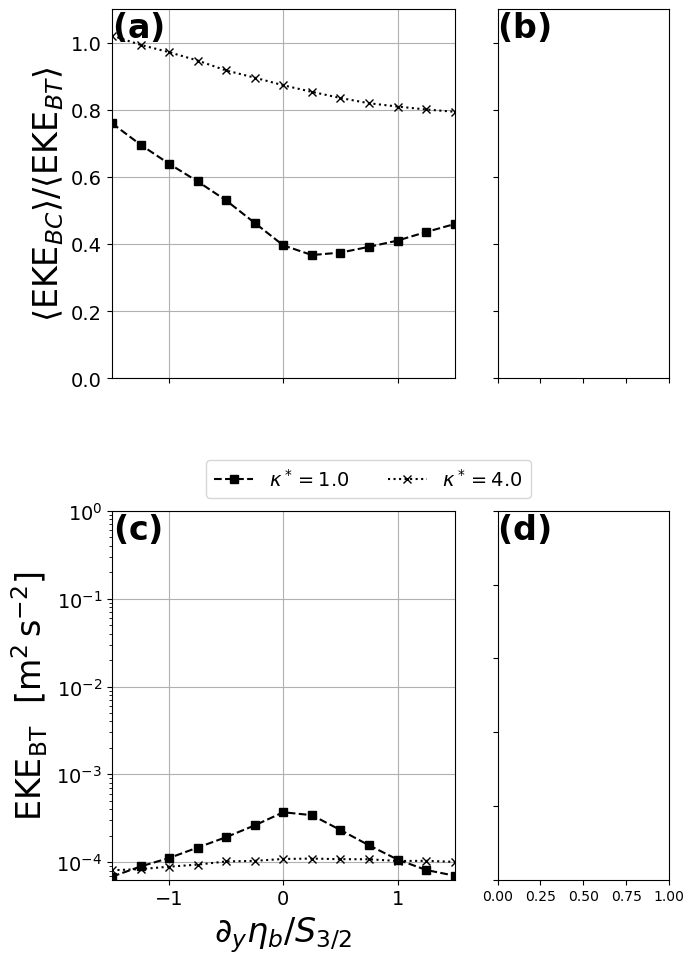

In [17]:
# LOAD BETAS


########################################################################3
##########################################################################

fig, ax = plt.subplots(3,2, figsize=(6,9), height_ratios=[1.,0.2,1.], width_ratios=[1.0,0.5])
fig.tight_layout(pad=0.0)

ax[2].axis("off")
ax[5].axis("off")

ax1=ax[4]; ax2=ax[6]; 

lsize = 24
tsize = 14

# x = betas / (U[1] * Ld^-2 / 2 ) 

# ############################################################################
# ax1.plot(x[1:end-1], BCEKE_nu0_kap0p125[1:end-1] ./ BTEKE_nu0_kap0p125[1:end-1], color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
# ax1.plot(x, BCEKE_nu0_kap0p25 ./ BTEKE_nu0_kap0p25, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax1.plot(x, BCEKE_nu0_kap0p5 ./ BTEKE_nu0_kap0p5, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
# ax1.plot(x, BCEKE_nu0_kap1 ./ BTEKE_nu0_kap1, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")


# ax1.set_xlim(x[1], x[end])
# ax1.set_ylim(0.0, 1.1)

# ax1.set_xticklabels([])

# ax1.tick_params(labelsize=tsize, which="both")

# ax1.grid()



# ##############################################################################

# ax2.plot(x[1:end-1], BTEKE_nu0_kap0p125[1:end-1], color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
# ax2.plot(x, BTEKE_nu0_kap0p25, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax2.plot(x, BTEKE_nu0_kap0p5, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
# ax2.plot(x, BTEKE_nu0_kap1, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")

# ax2.set_yscale("log")

# ax2.set_xlim(x[1], x[end])
# ax2.grid()

# ax2.set_xlabel(L"\beta^* ",fontsize=lsize)

# ax2.tick_params(labelsize=tsize, which="both")


# ############################################################################

############################################################################

############################################################################

############################################################################

############################################################################

############################################################################

####################################################################

############################################################################

############################################################################

############################################################################

# BTKE_x, BCKE_x, BCEAPE_x, LT_x, TT_x, BC_x, NL_x, DBT_x, DBC_x, resid_x)

function define_modal_nrg_ratios(mu_loc)

    EKEBC_over_EKEBT = zeros(length(h0s)) .* NaN
    EKE_BT = zeros(length(h0s)) .* NaN
        
    for h_ind in range(1, length(h0s))
    
        h0 = (h0s[h_ind], 0.0)
        kappa_loc = kappas[1]
        
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
        global topo_PV, eta = define_topo(model_params)
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
            
        a = load(data_dir*jld_name(model_params,62.95))

        xmn = a["jld_data"]["two_layer_xspace_modal_nrg_budget"]  # xspace modal nrgs (xmn)
    
        EKEBC_over_EKEBT[h_ind] = xmn[2] / xmn[1]          # 
        EKE_BT[h_ind] = xmn[1]
    
    end
        
    return EKEBC_over_EKEBT, EKE_BT
end

EKEBC_over_EKEBT_mu3, EKE_BT_mu3 = define_modal_nrg_ratios(mus[3])

EKEBC_over_EKEBT_mu5, EKE_BT_mu5 = define_modal_nrg_ratios(mus[5])



############################################################################

############################################################################


ax1=ax[1]; ax2=ax[3];

x= h0s ./ S32
x2 = x[7:end]


############################################################################
# ax1.plot(x2[1:end-1], BCEKE_nu0_kap0p125[1:end-1] ./ BTEKE_nu0_kap0p125[1:end-1], color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
# ax1.plot(x[4:end], BCEKE_nu0_kap0p25[4:end] ./ BTEKE_nu0_kap0p25[4:end], color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax1.plot(x, BCEKE_nu0_kap0p5 ./ BTEKE_nu0_kap0p5, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax1.plot(x, EKEBC_over_EKEBT_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
# ax1.plot(x, BCEKE_nu0_kap2 ./ BTEKE_nu0_kap2, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax1.plot(x, EKEBC_over_EKEBT_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")


# ax1.plot(x, BCEKE_nu0_mu1 ./ BTEKE_nu0_mu1, color="r", marker="x", linestyle="--", label=L"\mu^* = 1.0")

ax1.set_ylabel(L" \langle \mathrm{EKE}_{BC} \rangle / \langle \mathrm{EKE}_{BT} \rangle ", fontsize=lsize)

ax1.set_xlim(x[1], x[end])
# ax1.set_ylim(ax1.get_ylim()[1], 1.3)  # minimum(BCEKE_nu0_kap0p25 ./ BTEKE_nu0_kap0p25), 1.3) # 
ax1.set_ylim(0.0, 1.1)

ax1.set_xticklabels([])
# ax1.set_yscale("log")

ax1.tick_params(labelsize=tsize, which="both")


ax1.grid()



##############################################################################

# ax2.plot(x2[1:end-1], BTEKE_nu0_kap0p125[1:end-1], color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
# ax2.plot(x[4:end], BTEKE_nu0_kap0p25[4:end], color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax2.plot(x, BTEKE_nu0_kap0p5, color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax2.plot(x, EKE_BT_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
# ax2.plot(x, BTEKE_nu0_kap1, color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax2.plot(x, EKE_BT_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")

ax2.set_yscale("log")

ax2.set_xlim(x[1], x[end])
ax2.grid()

# # ax2.legend(fontsize=tsize)

# ax2.set_ylabel(L"\int \mathrm{NL}_\mathrm{BC} 2 \ \mathrm{d} k \, / \, \int  \mathrm{NL}_\mathrm{BT} \ \mathrm{d} k",fontsize=lsize)
ax2.set_ylabel(L"\mathrm{EKE}_\mathrm{BT} \ \ [ \mathrm{m}^2 \, \mathrm{s}^{-2} ]",fontsize=lsize)
ax2.set_xlabel(L"\partial_y \eta_b / S_{3/2} ",fontsize=lsize)

ax2.tick_params(labelsize=tsize, which="both")


#######################
ax1.legend(fontsize=tsize, loc="lower right", bbox_to_anchor=(1.25,-0.35), ncol=2)


r1_ymin = minimum([ax[1].get_ylim()[1], ax[4].get_ylim()[1]])
r1_ymax = maximum([ax[1].get_ylim()[2], ax[4].get_ylim()[2]]); # r1_ymax = 3e-11
r2_ymin = minimum([ax[3].get_ylim()[1], ax[6].get_ylim()[1]])
r2_ymax = maximum([ax[3].get_ylim()[2], ax[6].get_ylim()[2]])



ax[1].set_ylim(r1_ymin, r1_ymax)
ax[3].set_ylim(r2_ymin, r2_ymax)
ax[4].set_ylim(r1_ymin, r1_ymax)
ax[6].set_ylim(r2_ymin, r2_ymax)

ax[4].set_yticklabels([])
ax[6].set_yticklabels([])

ax[1].set_xticklabels([])
ax[4].set_xticklabels([])


ax[1].text(0.075, 0.95, L"\mathbf{(a)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax[1].transAxes);
ax[3].text(0.075, 0.95, L"\mathbf{(c)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax[3].transAxes);

ax[4].text(0.15, 0.95, L"\mathbf{(b)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax[4].transAxes);
ax[6].text(0.15, 0.95, L"\mathbf{(d)}", fontsize=lsize, horizontalalignment="center",verticalalignment="center", transform = ax[6].transAxes);

# savefig("./drag_figs/modal_nrgs_slope_n_beta.pdf",bbox_inches="tight")



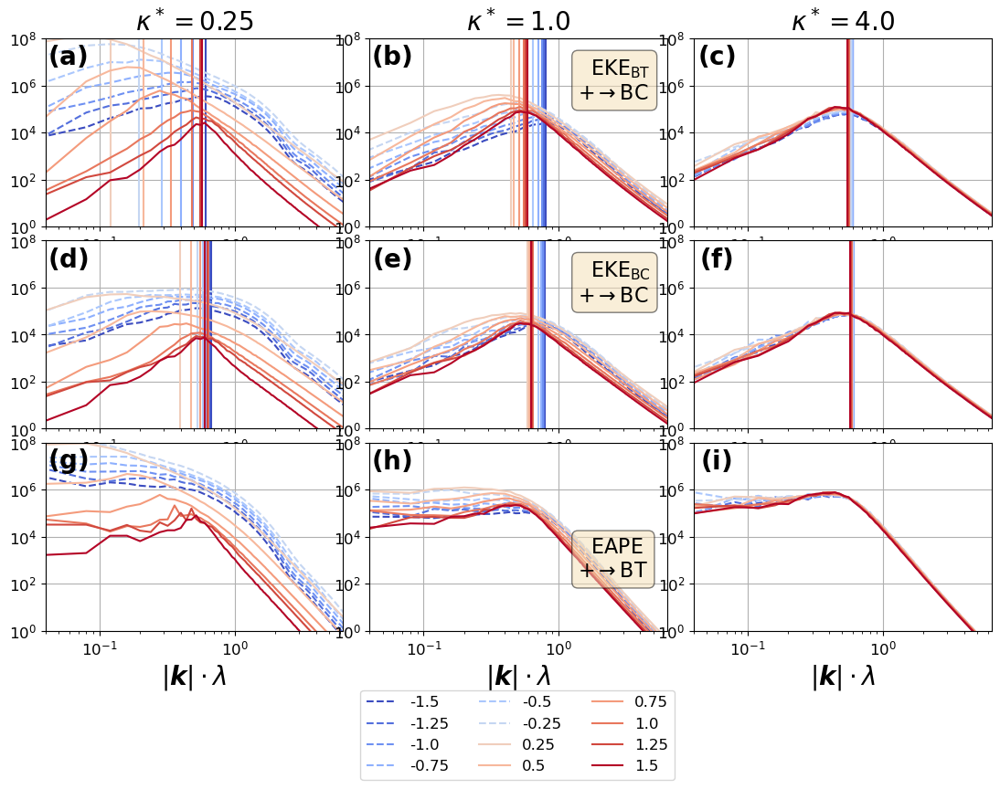

In [35]:

# a plot of KE_1 from all six combos of rho and U
fig,ax = PyPlot.subplots(3,3,figsize=(10.5, 6.5))
fig.tight_layout(pad=-1.0)

# h_ind=17
xmax_ind = 160
x = grid.kr .* Ld

fsize = 20
bsize = 16
lsize = 12


####################################################################

####################################################################

for h_ind in vcat(collect(range(1,6)), collect(range(8,13))) # length(h0s))
    if h_ind<7
        lt = "dashed"
    elseif h_ind>=7
        lt="solid"
    end

    h0 = (h0s[h_ind], 0.0)
    kappa_loc = kappas[1]
    mu_loc = mus[2]
    
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
    global topo_PV, eta = define_topo(model_params)

    # for kappa* = 1.0
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))

    norm = 1 # (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld)

    ax[1].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,1] .* norm, label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)
    ax[1].axvline(a["jld_data"]["two_layer_modal_length_scales"][1]*Ld, color=h_color(h0s[h_ind],hc_range,colors))
    # ax[1].axvline(sqrt(abs(topo_PV[2]) / a["jld_data"]["two_layer_vBT_scale"]) * Ld, color=h_color(h0s[h_ind],hc_range,colors))
    
    ax[2].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,2] .* norm, label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)
    ax[2].axvline(a["jld_data"]["two_layer_modal_length_scales"][2]*Ld, color=h_color(h0s[h_ind],hc_range,colors))
    
    ax[3].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,3] .* norm, label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    

    # for kappa* = 1.0
    mu_loc = mus[4]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))

    norm = 1 # (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld)

    ax[4].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,1] .* norm, label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)
    ax[4].axvline(a["jld_data"]["two_layer_modal_length_scales"][1]*Ld, color=h_color(h0s[h_ind],hc_range,colors))
    
    ax[5].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,2] .* norm, label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)
    ax[5].axvline(a["jld_data"]["two_layer_modal_length_scales"][2]*Ld, color=h_color(h0s[h_ind],hc_range,colors))
    
    ax[6].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,3] .* norm, label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)

    # for kappa* = 4.0
    mu_loc = mus[6]
    global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)
        
    a = load(data_dir*jld_name(model_params,62.95))

    norm = 1 # (a["jld_data"]["two_layer_vBT_scale"]^-3 / Ld)

    ax[7].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,1] .* norm, label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)
    ax[7].axvline(a["jld_data"]["two_layer_modal_length_scales"][1]*Ld, color=h_color(h0s[h_ind],hc_range,colors))
    
    ax[8].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,2] .* norm, label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)
    ax[8].axvline(a["jld_data"]["two_layer_modal_length_scales"][2]*Ld, color=h_color(h0s[h_ind],hc_range,colors))
    
    ax[9].plot(x, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,3] .* norm, label=string(round(h0s[h_ind] / S32, sigdigits=3)), color=h_color(h0s[h_ind],hc_range,colors),linestyle=lt)


    GC.gc()
end


####################################################################################
ax[1].set_xticklabels([])
ax[2].set_xticklabels([])
ax[4].set_xticklabels([])
ax[5].set_xticklabels([])
ax[7].set_xticklabels([])
ax[8].set_xticklabels([])

ax[4].set_yticklabels([])
ax[5].set_yticklabels([])
ax[6].set_yticklabels([])
ax[7].set_yticklabels([])
ax[8].set_yticklabels([])
ax[9].set_yticklabels([])

ax[6].legend(fontsize=lsize, bbox_to_anchor=(1.05,-0.275), ncol=3)


ax[1].set_title(L"\kappa^* = 0.25", fontsize=fsize)
ax[4].set_title(L"\kappa^* = 1.0", fontsize=fsize)
ax[7].set_title(L"\kappa^* = 4.0", fontsize=fsize)

ax[3].set_xlabel(L" | \boldsymbol{k} | \cdot \lambda", fontsize=fsize)

ax[6].set_xlabel(L" | \boldsymbol{k} | \cdot \lambda", fontsize=fsize)

ax[9].set_xlabel(L" | \boldsymbol{k} | \cdot \lambda", fontsize=fsize)


# ax3.set_ylim(ax3.get_ylim()[1],1.2)

ax[1].text(0.075, 0.9, L"\mathbf{(a)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[1].transAxes);
ax[2].text(0.075, 0.9, L"\mathbf{(d)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[2].transAxes);
ax[3].text(0.075, 0.9, L"\mathbf{(g)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[3].transAxes);
ax[4].text(0.075, 0.9, L"\mathbf{(b)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[4].transAxes);
ax[5].text(0.075, 0.9, L"\mathbf{(e)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[5].transAxes);
ax[6].text(0.075, 0.9, L"\mathbf{(h)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[6].transAxes);
ax[7].text(0.075, 0.9, L"\mathbf{(c)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[7].transAxes);
ax[8].text(0.075, 0.9, L"\mathbf{(f)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[8].transAxes);
ax[9].text(0.075, 0.9, L"\mathbf{(i)}", fontsize=fsize, horizontalalignment="center",verticalalignment="center", transform = ax[9].transAxes);


ymins = [10^0, 10^0, 10^0]
ymaxes = ymins .* 10^8

for i in range(1,length(ax))
    
    axn = ax[i]
    axn.grid()
    axn.tick_params(labelsize=lsize)
    axn.set_xlim(x[2], x[xmax_ind])
    
end


for i in range(1,size(ax)[1])

    ax[i].set_ylim(ymins[i], ymaxes[i])
    ax[i+size(ax)[1]].set_ylim(ymins[i], ymaxes[i])
    ax[i+2*size(ax)[1]].set_ylim(ymins[i], ymaxes[i])

    ax[i].set_yscale("log")
    ax[i+size(ax)[1]].set_yscale("log")
    ax[i+2*size(ax)[1]].set_yscale("log")

    ax[i].set_xscale("log")
    ax[i+size(ax)[1]].set_xscale("log")
    ax[i+2*size(ax)[1]].set_xscale("log")
end

# ax[3].set_ylim(ax[3].get_ylim()[1], ax[3].get_ylim()[2]+0.2)
# ax[6].set_ylim(ax[6].get_ylim()[1], ax[6].get_ylim()[2]+0.2)



###################################################################
###################################################################

plot_info_box(ax[4], L"\ \ \mathrm{EKE}_\mathrm{BT}", 0.7, 0.9, "BC", bsize)
plot_info_box(ax[5], L"\ \ \mathrm{EKE}_\mathrm{BC}", 0.7, 0.9, "BC", bsize)
plot_info_box(ax[6], L"\ \ \mathrm{EAPE}", 0.7, 0.5, "BT", bsize)


# savefig("./drag_figs/nrgs_kspace.pdf",bbox_inches="tight", transparent=true)



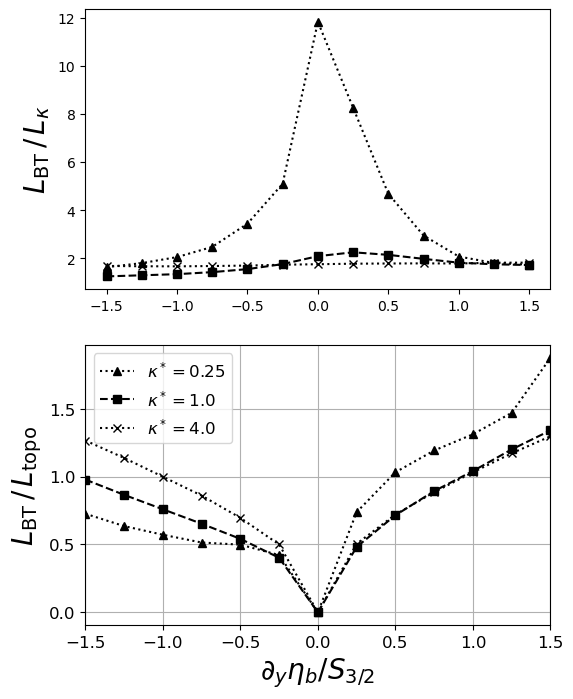

(-1.5, 1.5)

In [46]:
fig, ax = plt.subplots(2,1, figsize=(6,8))
ax1=ax[1]; ax2=ax[2];

lsize = 20
tsize = 12

x = h0s ./ S32
x2 = x[7:end-1]

############################################################################

############################################################################
vs_ind = 1

# vel scales are twelve
# total BT, U BT, V BT, total BC, U BC, V BC, (7) total L1, U L1, V L1, total L2, U L2, V L2

############################################################################

############################################################################

function define_modal_scale_ratios(mu_loc, vel_scale)

    LBC_over_LBT = zeros(length(h0s)) .* NaN
    LBT = zeros(length(h0s)) .* NaN
        
    for h_ind in range(1, length(h0s))
    
        h0 = (h0s[h_ind], 0.0)
        kappa_loc = kappas[1]
        
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
        global topo_PV, eta = define_topo(model_params)
        global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)

        if h_ind != 14
            a = load(data_dir*jld_name(model_params,62.95))

            c1 = 5
            c2 = 0.36
            
            v_scale = a["jld_data"]["two_layer_vBT_scale"]  # vel_scale[h_ind, vs_ind] #  U[1]/2 #  
            # LBC_over_LBT[h_ind] = a["jld_data"]["two_layer_modal_length_scales"][1] / (mu_loc /  (v_scale) ) * 2 * pi

            # L_VG = (Ld * c1 *exp(c2 / (mu_loc * Ld / (U[1]/2))))  / 2 / pi
            # L_VG = (Ld * c1 *exp(c2 / (mu_loc * Ld / (v_scale))))  / 2 / pi
            
            # LBC_over_LBT[h_ind] = a["jld_data"]["two_layer_modal_length_scales"][1] * (L_VG)

            L_R = sqrt(abs(v_scale / topo_PV[2])) 
            

            LBT[h_ind] = a["jld_data"]["two_layer_modal_length_scales"][1] * Ld # / (mu_loc /  (v_scale) ) # a["jld_data"]["two_layer_modal_length_scales"][1]^-1 / Ld  # L_VG  # 
            LBC_over_LBT[h_ind] = a["jld_data"]["two_layer_modal_length_scales"][1] * L_R
        end
        
    end
        
    return LBT.^-1, LBC_over_LBT.^-1
end

LBT_mu1, LBC_over_LBT_mu1 = define_modal_scale_ratios(mus[2], vel_scales_kap0p25)

LBT_mu3, LBC_over_LBT_mu3 = define_modal_scale_ratios(mus[4], vel_scales_kap1)

LBT_mu5, LBC_over_LBT_mu5 = define_modal_scale_ratios(mus[6], vel_scales_kap4)



############################################################################

############################################################################

ax1.plot(x, LBT_mu1, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax2.plot(x, LS_nu0_kap0p5[:,2] ./ LS_nu0_kap0p5[:,1], color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax1.plot(x, LBT_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
# ax2.plot(x, LS_nu0_kap2[:,2] ./ LS_nu0_kap2[:,1], color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax1.plot(x, LBT_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")

ax1.set_ylabel(L"L_\mathrm{BT} \, / \, L_{\kappa}  ", fontsize=lsize)


# ax2.plot(x2, LS_nu0_kap0p125[1:end-1,2] ./ LS_nu0_kap0p125[1:end-1,1], color="k", marker=".", linestyle="-.", label=L"\kappa^* = 0.125")
ax2.plot(x, LBC_over_LBT_mu1, color="k", marker="^", linestyle="dotted", label=L"\kappa^* = 0.25")
# ax2.plot(x, LS_nu0_kap0p5[:,2] ./ LS_nu0_kap0p5[:,1], color="k", marker="d", linestyle="-", label=L"\kappa^* = 0.5")
ax2.plot(x, LBC_over_LBT_mu3, color="k", marker="s", linestyle="--", label=L"\kappa^* = 1.0")
# ax2.plot(x, LS_nu0_kap2[:,2] ./ LS_nu0_kap2[:,1], color="k", marker="o", linestyle="-.", label=L"\kappa^* = 2.0")
ax2.plot(x,LBC_over_LBT_mu5, color="k", marker="x", linestyle="dotted", label=L"\kappa^* = 4.0")

ax2.set_ylabel(L"L_\mathrm{BT}  \, / \, L_\mathrm{topo} ", fontsize=lsize)
# ax3.set_xlabel(L"\partial_y \eta_b / S_{3/2}", fontsize=lsize)
ax2.legend(fontsize=tsize)
ax2.set_xlabel(L"\partial_y \eta_b / S_{3/2}", fontsize=lsize)

ax2.grid()

ax2.tick_params(labelsize=tsize, which="both")

# ax1.set_yscale("log")

ax2.set_xlim(x[1], x[end])


# ax2.set_ylim(0., 4)



############################################################################

############################################################################

# savefig("./drag_figs/BC_BT_scale_ratio.pdf",bbox_inches="tight")


In [7]:
using FileIO, JLD2

data_dir_old = "../../data/two_layer_drag_study/";

fn = data_dir_old*"vel_scales.jld"

# jld_data = Dict("vel_scales_kap0p5" => vel_scales_kap0p5,
#     "vel_scales_kap1" => vel_scales_kap1,
#     "vel_scales_kap2" => vel_scales_kap2,
#     "vel_scales_kap4" => vel_scales_kap4)


# jldsave(fn; jld_data)


a = load(fn);

for (k,v) in a["jld_data"]
    @eval $(Symbol(k)) = $(v)
end

############################################################################
# vel scales are twelve
# total BT, U BT, V BT, total BC, U BC, V BC, total L1, U L1, V L1, total L2, U L2, V L2

# first index is h_ind
# vel_scales_kap0p25[:,vs_ind]


In [75]:
restart_yr0 = ceil(300 * (Ld / ((U[1]-U[end])/2)) / 3600 / 24 / 365.25)  # number of eddy periods converted to years for model run


a = load(jld_name_pre_buoy(model_params,restart_yr0))



Dict{String, Any} with 1 entry:
  "jld_data" => Dict{String, Any}("nu"=>0.0, "Nz"=>2, "Qy"=>[1.09071e-11 1.0907…

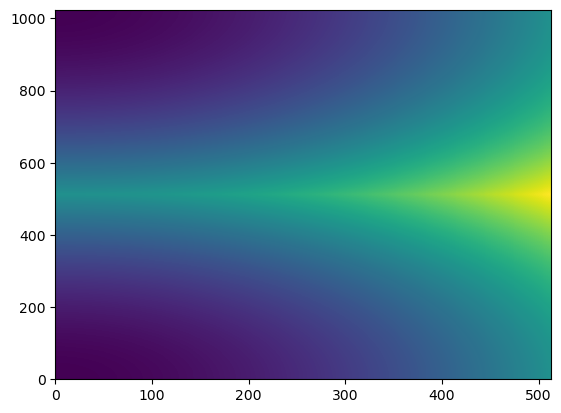

PyObject <matplotlib.collections.QuadMesh object at 0x147e98501300>

In [28]:
    # ##############################################################
    # # BC EKE budget
    # ##############################################################
    # ax2.plot(grid.kr*Ld, -trans_resid .* norm, label=L"-T^\mathrm{D}", color=tab20_color(8), linestyle="dashdot")
    # ax2.plot(grid.kr*Ld, -a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* norm, label=L"-T_\mathrm{flat}", color=tab20_color(2), linestyle="dashdot")
    # # ax2.plot(grid.kr*Ld, -a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* norm , label=L"D_\mathrm{BC}")
    # ax2.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,8] .* norm , label=L"D_\mathrm{BC}", color=tab20_color(16), linestyle="solid")
    # ax2.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,11] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_{\mathrm{BT} \rightarrow \mathrm{BC}}", color=tab20_color(12), linestyle="dashdot")
    # ax2.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_\mathrm{BC}", color=tab20_color(20), linestyle="dashed")    
    
    
        
    # println(sum(grid.kr.^2 .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,11]))
    
    # println(sum(grid.kr.^2 .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,12]))

    
    # ##############################################################
    # # BT EKE budget
    # ##############################################################
    
    # ax3.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* norm, label=L"T_\mathrm{flat}", color=tab20_color(2), linestyle="dashdot")
    # ax3.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,10] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_{\mathrm{BC} \rightarrow \mathrm{BT}}", color=tab20_color(12), linestyle="dashdot")
    # ax3.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9] .* norm , label=L"\mathrm{NL}^\mathrm{EKE}_\mathrm{BT}", color=tab20_color(5), linestyle="dashed")
    # ax3.plot(grid.kr*Ld, a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,7] .* norm , label=L"D_\mathrm{BT}", color=tab20_color(17), linestyle="solid")



println(sum(grid.kr.^2 .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,10]))

println(sum(grid.kr.^2 .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,9]))



-3.822770443348104e-12
1.092387262248999e-11


In [ ]:
plt.plot(grid.kr.^2)
plt.plot(sqrt.(grid.kr.^2 .+ grid.

In [21]:

i=7
j=1
k=2


h0 = (h0s[i], 0.0)
kappa_loc = kappas[j]
mu_loc = mus[k]

global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
global topo_PV, eta = define_topo(model_params)
global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)

beta = betas[7]
global model_params = redef_mu_kappa_beta(model_params, mu_loc, kappa_loc, beta)


# a = load(alt_data_dir*jld_name(model_params,71.99))
a = load(alt_data_dir*jld_name(model_params, 71.95))

    

# energies are: (1) BTEKE, (2) BCEKE, (3) EAPE; (4) CBC; (5) Tflat, (6) Ttopo; , (7) DBT, (8) DBC;
#               (9) NLBC2BT, (10) NLBTEKE, (11) NLBT2BC; (12) NLBVEKE (13) NLBCEAPE (14) resid

# layer2_Htot_4000.0_L_2pi4.449E+06_y_slope_h0_0.000E+00_beta3.116E-12_uni_shear_uni_strat_mu8.826E-08_kappa0.000E+00_nu0.000E+00_res1024_yr57.7.jld


Dict{String, Any} with 1 entry:
  "jld_data" => Dict{String, Any}("ph_slices"=>0.031725, "two_layer_modal_lengt…

In [22]:
    ψ = a["jld_data"]["psi_yrs_end"]
    # ψ = a["jld_data"]["psi_ot"][:,:,:,end]

    ψh = deepcopy(vars.uh)

    rfftplanlayered = plan_flows_rfft(A{T, 3}(undef, grid.nx, grid.ny, nlayers), [1, 2]; flags=FFTW.MEASURE)

    fwdtransform!(ψh, ψ, params)

    @unpack_mod_params model_params

    dev = grid.device
    T = eltype(grid)
    A = device_array(dev)

    rfftplan = plan_flows_rfft(A{T, 3}(undef, grid.nx, grid.ny, 1), [1, 2]; flags=FFTW.MEASURE)

    # parameters
    nlayers = 2
    δ = [params.H[1]/sum(params.H), params.H[2]/sum(params.H)]
    g′ = g * (rho[2] -   rho[1]) / rho0 # reduced gravity at each interface
    Ld1 = (f0^2 / (g′ * params.H[1]))^-0.5
    ∂yηb = params.topographic_pv_gradient[2] / (f0 / params.H[end])
    
    # assigning basic variables
    ψBC = 0.5 * (ψ[:,:,1] .- ψ[:,:,2])
    ψBT = 0.5 * (ψ[:,:,1] .+ ψ[:,:,2])

    ψBCh = deepcopy(vars.uh[:,:,1])
    ψBTh = deepcopy(vars.uh[:,:,1])

    mul2D!(ψBCh, rfftplan, deepcopy(ψBC))
    mul2D!(ψBTh, rfftplan, deepcopy(ψBT))
    
    U₁, U₂, = view(params.U, :, :, 1), view(params.U, :, :, 2)
    
    S32 = CUDA.@allowscalar f0 * U₁[1,1] / g′

    # streamfunction stuff
    ∂xψBTh = im * grid.kr .* ψBTh
    ∂yψBTh = im * grid.l .* ψBTh
    
    ∂xψBT = deepcopy(vars.u[:,:,1])
    ∂yψBT = deepcopy(vars.u[:,:,1])

    ldiv2D!(∂xψBT, rfftplan, im * grid.kr .* ψBTh)
    ldiv2D!(∂yψBT, rfftplan, im * grid.l .* ψBTh)

    ∂xψBCh = im * grid.kr .* ψBCh
    ∂yψBCh = im * grid.l .* ψBCh

    ∂xψBC = deepcopy(vars.u[:,:,1])
    ∂yψBC = deepcopy(vars.u[:,:,1])

    ldiv2D!(∂xψBC, rfftplan, im * grid.kr .* ψBCh)
    ldiv2D!(∂yψBC, rfftplan, im * grid.l .* ψBCh)

    # ∂xψBT_∂yψBCh = deepcopy(vars.uh[:,:,1])

    # mul2D!(∂xψBT_∂yψBCh, rfftplan, ∂xψBT * ∂yψBC)

    # ∂yψBT_∂xψBCh = deepcopy(vars.uh[:,:,1])

    # mul2D!(∂yψBT_∂xψBCh, rfftplan, ∂yψBT * ∂xψBC)

    J_ψBT_ψBCh = deepcopy(vars.uh[:,:,1])

    mul2D!(J_ψBT_ψBCh, rfftplan, ∂xψBT * ∂yψBC - ∂yψBT * ∂xψBC)  #  (uBT .* vBC .- uBC .* vBT))
    
    # nonlinear terms
    ζ = deepcopy(vars.v)

    ζ[:,:,1] .= irfft(-grid.Krsq .* ψh[:,:,1], grid.ny)
    ζ[:,:,2] .= irfft(-grid.Krsq .* ψh[:,:,2], grid.ny)

    ζ₁, ζ₂ = view(ζ, :, :, 1), view(ζ, :, :, 2)

    ζBCh = - grid.Krsq .* ψBCh
    ζBTh = - grid.Krsq .* ψBTh

    ζBC = deepcopy(vars.u[:,:,1])
    ζBT = deepcopy(vars.u[:,:,1])

    ldiv2D!(ζBC, rfftplan, - grid.Krsq .* ψBCh)
    ldiv2D!(ζBT, rfftplan, - grid.Krsq .* ψBTh)

    ∂xζBCh = im * grid.kr .* ζBCh
    ∂xζBTh = im * grid.kr .* ζBTh

    ∂yζBCh = im * grid.l .* ζBCh
    ∂yζBTh = im * grid.l .* ζBTh

    ∂xζBC = deepcopy(vars.u[:,:,1])
    ∂xζBT = deepcopy(vars.u[:,:,1])

    ldiv2D!(∂xζBC, rfftplan, im * grid.kr .* ζBCh)
    ldiv2D!(∂xζBT, rfftplan, im * grid.kr .* ζBTh)

    ∂yζBC = deepcopy(vars.u[:,:,1])
    ∂yζBT = deepcopy(vars.u[:,:,1])

    ldiv2D!(∂yζBC, rfftplan, im * grid.l .* ζBCh)
    ldiv2D!(∂yζBT, rfftplan, im * grid.l .* ζBTh)

    ##
    ζBT∂xψBTh = deepcopy(vars.uh[:,:,1])
    ζBT∂yψBTh = deepcopy(vars.uh[:,:,1])

    ζBC∂xψBCh = deepcopy(vars.uh[:,:,1])
    ζBC∂yψBCh = deepcopy(vars.uh[:,:,1])

    ζBC∂xψBTh = deepcopy(vars.uh[:,:,1])
    ζBC∂yψBTh = deepcopy(vars.uh[:,:,1])

    ζBT∂xψBCh = deepcopy(vars.uh[:,:,1])
    ζBT∂yψBCh = deepcopy(vars.uh[:,:,1])

    ψBC∂xψBTh = deepcopy(vars.uh[:,:,1])
    ψBC∂yψBTh = deepcopy(vars.uh[:,:,1])

    
    mul2D!(ζBT∂xψBTh, rfftplan, ζBT .* ∂xψBT)
    mul2D!(ζBT∂yψBTh, rfftplan, ζBT .* ∂yψBT)

    mul2D!(ζBC∂xψBCh, rfftplan, ζBC .* ∂xψBC)
    mul2D!(ζBC∂yψBCh, rfftplan, ζBC .* ∂yψBC)

    mul2D!(ζBC∂xψBTh, rfftplan, ζBC .* ∂xψBT)
    mul2D!(ζBC∂yψBTh, rfftplan, ζBC .* ∂yψBT)

    mul2D!(ζBT∂xψBCh, rfftplan, ζBT .* ∂xψBC)
    mul2D!(ζBT∂yψBCh, rfftplan, ζBT .* ∂yψBC)

    mul2D!(ψBC∂xψBTh, rfftplan, ψBC .* ∂xψBT)
    mul2D!(ψBC∂yψBTh, rfftplan, ψBC .* ∂yψBT)

    J_ψBT_ζBT = ∂xψBT .* ∂yζBT .- ∂yψBT .* ∂xζBT

    J_ψBT_ζBTh = deepcopy(vars.uh[:,:,1])
    
    mul2D!(J_ψBT_ζBTh, rfftplan, ∂xψBT .* ∂yζBT .- ∂yψBT .* ∂xζBT)

    ζ₁h = deepcopy(vars.uh[:,:,1])
    
    mul2D!(ζ₁h, rfftplan, ζ₁)
    
    # ζ₂h = rfft(ζ₂)

    ∂xζ1 = deepcopy(vars.u[:,:,1])

    ldiv2D!(∂xζ1, rfftplan, im * grid.kr .* ζ₁h)

    ############################################################################################
    w_32h = calc_w_int(vars, grid, ψ, params, model_params)
    T_Dh = @. - (f0 / H[2]) * w_32h * conj(ψBCh)
    T_Dh .+= conj.(T_Dh)

    w_32 = deepcopy(vars.u[:,:,1])
    ldiv2D!(w_32, rfftplan, deepcopy(w_32h))

    ############################################################################################
    BTEKE = @. 0.5 * (conj(ψBTh) * (grid.kr^2 * ψBTh) + ψBTh * conj(grid.kr^2 * ψBTh))

    BCEKE = @. 0.5 * grid.kr^2 * (conj(ψBCh) * ψBCh + ψBCh * conj(ψBCh))
    BCEAPE = @. 0.5 * 2 * Ld1^-2 * (conj(ψBCh) * ψBCh + ψBCh * conj(ψBCh))

    ############################################################################################
    # Baroclinic conversion term
    CBC = @. S32 * (params.f₀ / params.H[1]) * ( conj(ψBCh) * ∂xψBTh + ψBCh * conj(∂xψBTh)) # these are equivalent!

    # CBC = @. U₁ * Ld1^-2 * (conj(ψBCh) * ∂xψBTh)
    # CBC .+= conj(CBC)
    
    ############################################################################################
    # Linear BC-BT flux (flat-bottom) term
    BC2BT = @. 0.5 * U₁ * (conj(ψBTh) * ∂xζBCh + ψBTh * conj(∂xζBCh))

    ############################################################################################
    # Nonlinear terms in BT budget
    NLBT = zeros(dev, T, (grid.nkr,grid.ny,2)) .+ 0im
    @views NLBT[:,:,1] = @. conj(ψBTh) * J_ψBT_ζBTh + ψBTh * conj(J_ψBT_ζBTh)  # im * (grid.l * ζBT∂xψBTh - grid.kr * ζBT∂yψBTh)
    # NLBT[:,:,1] .+= conj.(NLBT[:,:,1])

    @views NLBT[:,:,2] = @. conj(ψBTh) * im * (grid.l * ζBC∂xψBCh - grid.kr * ζBC∂yψBCh)
    @views NLBT[:,:,2] .+= conj.(NLBT[:,:,2])

    ############################################################################################
    # Nonlinear terms in BC budget
    NLBC = zeros(dev, T, (grid.nkr,grid.ny,3)) .+ 0im

    #NLBC2BT
    @views NLBC[:,:,1] = @. conj(ψBCh) * im * (grid.l * ζBC∂xψBTh - grid.kr * ζBC∂yψBTh)
    @views NLBC[:,:,1] .+= conj.(NLBC[:,:,1])

    #NLBCEKE
    @views NLBC[:,:,2] = @. conj(ψBCh) * im * (grid.l * ζBT∂xψBCh - grid.kr * ζBT∂yψBCh)
    @views NLBC[:,:,2] .+= conj.(NLBC[:,:,2])

    #NLBCEAPE
    @views NLBC[:,:,3] = @. - 2 * Ld1^-2 * conj(ψBCh) * im * (grid.l * ψBC∂xψBTh - grid.kr * ψBC∂yψBTh)
    @views NLBC[:,:,3] .+= conj.(NLBC[:,:,3])

    NL_EAPE = @. - Ld^-2 * conj(ψBCh) * J_ψBT_ψBCh  # wrong .. product of FT is not FT of products (∂xψBTh * ∂yψBCh - ∂yψBTh * ∂xψ∂xψBTBCh) # 
    NL_EAPE .+= conj.(NL_EAPE)

    #- Ld^-2 .* psi_BC_hpf .* (uBT .* vBC .- uBC .* vBT))
    ############################################################################################
    TopoT = @. -0.5 * (params.f₀ / params.H[2]) * ∂yηb * (conj(ψBTh) * ∂xψBCh + ψBTh * conj(∂xψBCh))

    ############################################################################################
    # BT drag
    DBT = @. - 0.5 * params.μ * (conj(ψBTh) * (ζBCh - ζBTh) + ψBTh * conj(ζBCh - ζBTh))

    ############################################################################################
    # BC drag
    DBC = @. 0.5 * params.μ * (conj(ψBCh) * (ζBCh - ζBTh) + ψBCh * conj(ζBCh - ζBTh) );



5.135419648208664e-8
5.945144583737509e-9
-5.710747842020918e-8
1.918626456149727e-10


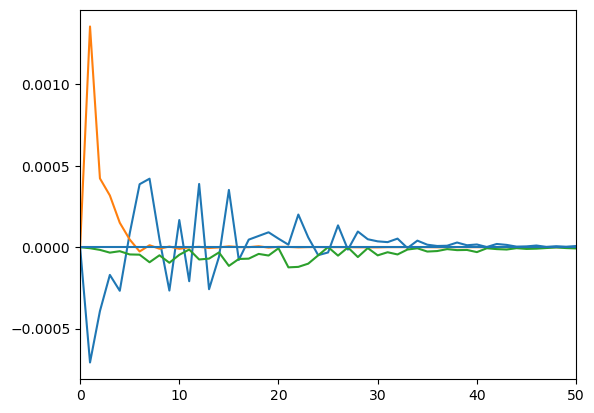

(0.0, 50.0)

In [23]:
aaa = sum(isotropic_mean((grid.Krsq) .* NLBC[:,:,3], prob.grid))
bbb = sum(isotropic_mean((grid.Krsq) .* CBC, prob.grid))
ccc = sum(isotropic_mean((grid.Krsq) .* T_Dh, prob.grid))

println(aaa)
println(bbb)
println(ccc)


println(aaa .+ bbb .+ ccc)

# println(sum(real.(grid.Krsq .* NLBC[:,:,3])))

# println(sum(real.(grid.Krsq .* CBC)))

# println(sum(real.(grid.Krsq .* T_Dh)))

# -2 * Ld1^-2 / (-Ld^-2)
plt.plot(isotropic_mean(sqrt.(grid.Krsq) .* NLBC[:,:,3], prob.grid))
plt.plot(isotropic_mean(sqrt.(grid.Krsq) .* CBC, prob.grid))
plt.plot(isotropic_mean(sqrt.(grid.Krsq) .* T_Dh, prob.grid))

plt.axhline(0)

plt.xlim(0,50)


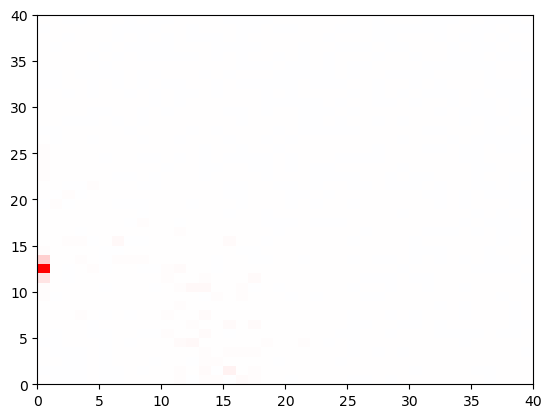

(0.0, 40.0)

In [44]:
# NL_BC_EKE1 = @. conj(ψBCh) * im * (grid.l * ζBT∂xψBCh - grid.kr * ζBT∂yψBCh)
# NL_BC_EKE1 .+= conj.(NL_BC_EKE1)


# NL_BC_EKE2 = @. conj(ψBCh) * (∂xψBCh * ∂yζBTh - ∂yψBCh * ∂xζBTh)
# NL_BC_EKE2 .+= conj.(NL_BC_EKE2)



# plt.pcolormesh(real.(NL_BC_EKE1)')
# plt.colorbar()

# plt.xlim(0,30)
# plt.ylim(0,30)

# plt.figure()
# plt.plot(isotropic_mean(NL_BC_EKE1, prob.grid))
# plt.xlim(0,30)


# ##
# plt.figure()
# plt.pcolormesh(real.(NL_BC_EKE2)')
# plt.colorbar()

# plt.xlim(0,30)
# plt.ylim(0,30)

# plt.figure()
# plt.plot(isotropic_mean(NL_BC_EKE2, prob.grid))
# plt.xlim(0,30)




# lim = maximum(abs.(real.(ψBCh)))

# plt.pcolormesh((real.(ψBCh))', vmin=-lim, vmax=lim, cmap=PyPlot.cm.bwr)

lim = maximum(abs.(real.(DBC)))

plt.pcolormesh((real.(DBC))', vmin=-lim, vmax=lim, cmap=PyPlot.cm.bwr)


plt.xlim(0,40)
plt.ylim(0,40)

1.8936283377787976e-6


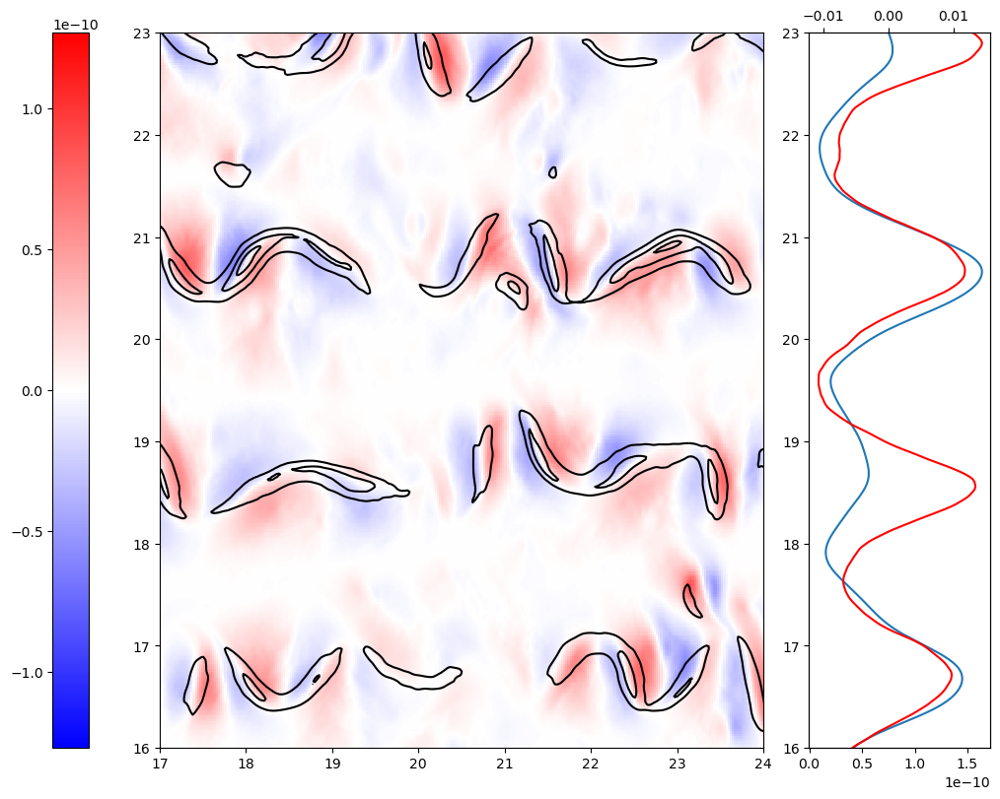

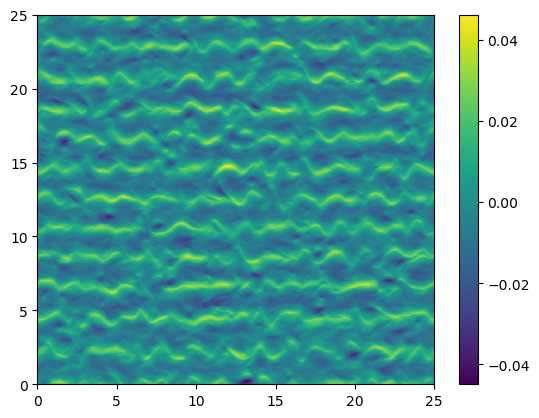

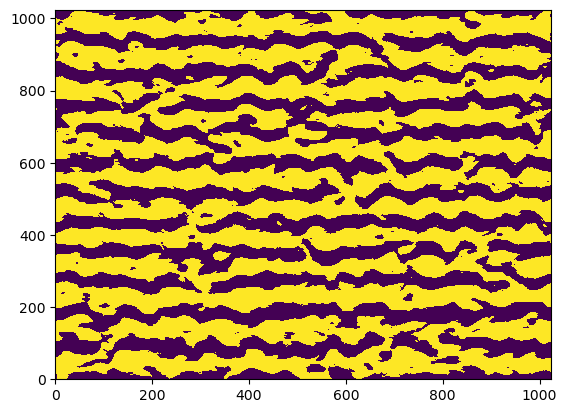

PyObject <matplotlib.collections.QuadMesh object at 0x15248ae515a0>

In [28]:
using DSP

w_mask = zeros(513, 1024)

for i in range(1,513)
    for j in range(1,1024)
        if grid.kr[i] + abs(grid.l[j]) > 2*abs(grid.l[j])
            w_mask[i,j] = 1
        end
    end
end


w_32_mask = deepcopy(vars.u[:,:,1])
# ldiv2D!(w_32_mask, rfftplan, abs.(w_mask .- 1.) .* NLBT[:,:,2])  # deepcopy(w_32h))
ldiv2D!(w_32_mask, rfftplan, deepcopy(w_32h))   # NLBT[:,:,2]

x = collect(range(0, Lx, 1025)) ./ (Ld * 2 * pi)
y = collect(range(0, Lx, 1025)) ./ (Ld * 2 * pi)

NL_BC_EKE = @. ψBC * (∂xψBC * ∂yζBT - ∂yψBC * ∂xζBT)

EKE_xy = @. ∂xψBT^2 + ∂yψBT^2 

##############

hpf = ifelse.(((Kr .< K[15]) .&& (Kr .> K[1])), Kr ./ Kr, 0 .* Kr)

# Filter the Fourier transformed fields
psi_BCh_hpf = hpf .* 0.5 .* (psih[:,:,1] .- psih[:,:,2])

psi_BC_hpf = A(zeros(nx, nx))
ldiv2D!(psi_BC_hpf, rfftplan, psi_BCh_hpf)

##################

T_D2 = @. S32 * (f0 / H[2]) * ψBC * ∂xψBT # - f0 * (w_32 * ψBC) / H[2]  # ψBC * (uBC * zeta_BT_dx + vBC * zeta_BT_dy) # 
println(sum(T_D2))

CBC2 = @. S32 * (f0 / H[2]) * ψBC * ∂xψBT
DBC2 = @. params.μ * ψBC * (ζBC - ζBT)


lim = maximum(abs.(T_D2))

fig, ax = plt.subplots(1,2,figsize=(10,8), width_ratios=[1.0,0.3], layout="constrained")

pc1 = ax[1].pcolormesh(x, y, T_D2', vmin=-lim, vmax=lim, cmap = PyPlot.cm.bwr)

plt.colorbar(pc1, location="left")

ax[1].contour(x[1:end-1], y[1:end-1], EKE_xy', colors="black", levels=3)

# xl1 = 4; xl2=14
# yl1 = 11.5; yl2=21.5

xl1 = 17; xl2=24.
yl1 = 16.; yl2=23.

# xl1 = 0.; xl2=25.
# yl1 = 0.; yl2=25.

ax[1].set_xlim(xl1, xl2)
ax[1].set_ylim(yl1, yl2)


##

# ax[2].plot(mean(T_D2, dims=1)', y[1:end-1])
ax[2].plot(conv(ones(30), (mean(T_D2, dims=1)'))[15:end-15], y[1:end-1])


ax2t = ax[2].twiny()
ax2t.plot(mean(-∂yψBT, dims=1)', y[1:end-1], color="red")

ax[2].set_ylim(yl1, yl2)
ax2t.set_ylim(yl1, yl2)

#############################################################################
#############################################################################
# plt.figure()

# pc2 = plt.pcolormesh(x, y, -∂yψBT')
# plt.colorbar(pc2)

# plt.contour(x[1:end-1], y[1:end-1], EKE_xy', colors="black", levels=2)

# plt.xlim(xl1, xl2)
# plt.ylim(yl1, yl2)


# #############################################################################
# #############################################################################
# plt.figure()

# pc3 = plt.pcolormesh(x, y, ∂xψBT')
# plt.colorbar(pc3)

# plt.contour(x[1:end-1], y[1:end-1], EKE_xy', colors="black", levels=2)

# plt.xlim(xl1, xl2)
# plt.ylim(yl1, yl2)


#############################################################################
#############################################################################



# plt.figure()

# plt.plot(sum(w_32_mask, dims=1)')


# plt.figure()

# plt.plot(sum(w_32_mask, dims=2))

# # println(sum(w_32_mask))

# plt.figure()
# plt.pcolormesh(abs.(w_32h)')

# plt.xlim(0,40)
# plt.ylim(0,40)

# plt.figure()
# plt.pcolormesh(abs.(rfft(T_D2 .- mean(T_D2)))')


# plt.xlim(0,50)
# plt.ylim(0,50)

fig, ax = plt.subplots(1,1)

pc = ax.pcolormesh(x, y, -∂yψBT')
plt.colorbar(pc)

# ax.set_xlim(xl1, xl2)
# ax.set_ylim(yl1, yl2)

plt.figure()
plt.pcolormesh((-∂yψBT .< 0.)')


1.1891321896101047e-8


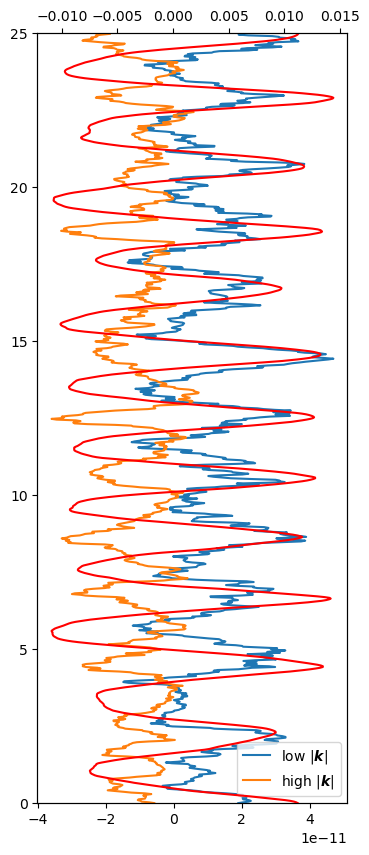

In [14]:
psih = ψh  ##
hpf = ifelse.(((Kr .< K[15]) .&& (Kr .> K[1])), Kr ./ Kr, 0 .* Kr)
psi_BCh_hpf = hpf .* 0.5 .* (psih[:,:,1] .- psih[:,:,2])
psi_BC_hpf = A(zeros(nx, nx))
ldiv2D!(psi_BC_hpf, rfftplan, psi_BCh_hpf)

N_BC_EKE_lo = @. psi_BC_hpf * (uBC * zeta_BT_dx + vBC * zeta_BT_dy)

##
hpf = ifelse.(((Kr .< K[40]) .&& (Kr .> K[15])), Kr ./ Kr, 0 .* Kr)
psi_BCh_hpf = hpf .* 0.5 .* (psih[:,:,1] .- psih[:,:,2])
psi_BC_hpf = A(zeros(nx, nx))
ldiv2D!(psi_BC_hpf, rfftplan, psi_BCh_hpf)

N_BC_EKE_hi = @. psi_BC_hpf * (uBC * zeta_BT_dx + vBC * zeta_BT_dy)


##
fig,ax = plt.subplots(1,1, figsize=(4,10))

ax.plot(conv(ones(20), (mean(N_BC_EKE_lo, dims=1)'))[10:end-10], y[1:end-1], label=L"\mathrm{low } \  |\boldsymbol{k}|")
ax.plot(conv(ones(20), (mean(N_BC_EKE_hi, dims=1)'))[10:end-10], y[1:end-1], label=L"\mathrm{high} \  |\boldsymbol{k}|")

# ax.plot(conv(ones(20), (mean(N_BC_EKE_lo, dims=2)))[10:end-10], y[1:end-1], label=L"\mathrm{low } \  |\boldsymbol{k}|")
# ax.plot(conv(ones(20), (mean(N_BC_EKE_hi, dims=2)))[10:end-10], y[1:end-1], label=L"\mathrm{high} \  |\boldsymbol{k}|")


ax.set_ylim(0,25)

ax.legend()


axt = ax.twiny()
axt.plot(mean(-∂yψBT, dims=1)', y[1:end-1], color="red")

println(sum(N_BC_EKE_lo) + sum(N_BC_EKE_hi))

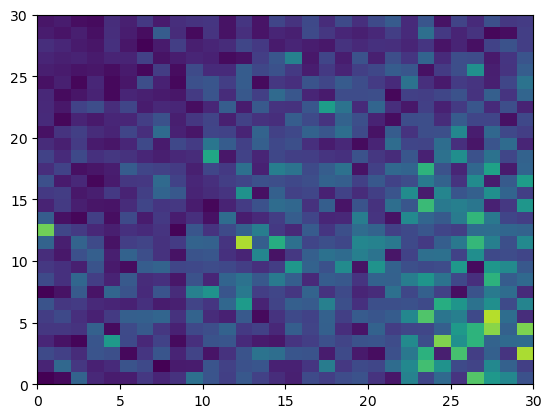

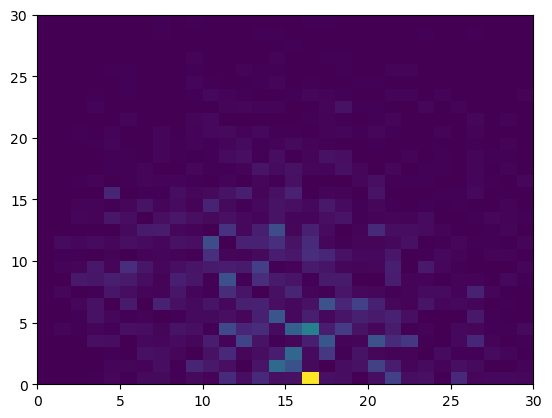

(0.0, 30.0)

In [108]:


T_D2h = deepcopy(vars.uh[:,:,1])
# mul2D!(T_D2h, rfftplan, T_D2 .- mean(T_D2))  # w_32 .- mean(w_32))  # NLBT_x2k)

mul2D!(T_D2h, rfftplan, deepcopy(CBC2 .- mean(CBC2)))  # w_32 .- mean(w_32))  # NLBT_x2k)

# CBC2_h = imfilter(twodim_zeropad(rfft(ψBC)), reflect(twodim_zeropad(rfft(∂xψBT))))

# CBC2_h = conv2(twodim_zeropad(rfft(ψBC)), twodim_zeropad(rfft(∂xψBT)))

# plt.pcolormesh(real.(NLBT[:,:,1]))

# plt.colorbar()

# plt.xlim(0,30)
# plt.ylim(0,30)



plt.figure()
plt.pcolormesh((abs.(T_D2h))')

# edge_ind_x = 256
# edge_ind_y = 512

# plt.xlim(edge_ind_x, edge_ind_x + 30)
# plt.ylim(edge_ind_y, edge_ind_y + 30)

plt.xlim(0,30)
plt.ylim(0,30)


plt.figure()
plt.pcolormesh((abs.(CBC))')

plt.xlim(0,30)
plt.ylim(0,30)



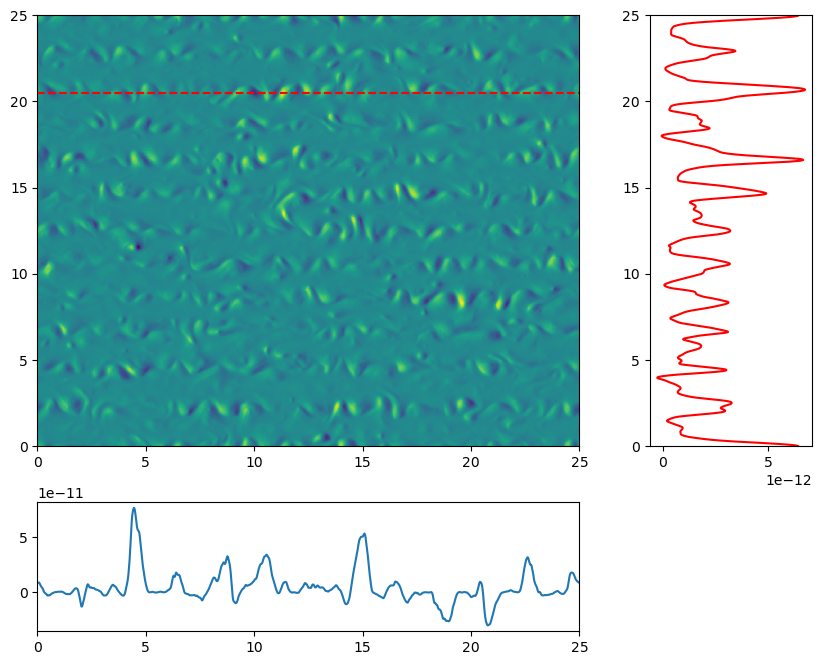

(0.0, 1.0, 0.0, 1.0)

In [9]:
fig, ax = plt.subplots(2,2, figsize=(10,8), width_ratios=[1.0, 0.3], height_ratios=[1.0, 0.3])

ax[1].pcolormesh(x[1:end-1], y[1:end-1], CBC2')
ax[1].axhline(x[840], color="red", linestyle="dashed")

ax[2].plot(x[1:end-1], CBC2[840, :])

ax[3].plot(mean(CBC2, dims=1)', y[1:end-1], color="red")


xl1 = 0.; xl2=25.
yl1 = 0.; yl2=25.

ax[1].set_xlim(xl1, xl2)
ax[1].set_ylim(yl1, yl2)


##

ax[2].set_xlim(xl1, xl2)


ax[3].set_ylim(yl1, yl2)

ax[4].axis("off")
##



In [54]:
x[840]

20.4833984375

In [80]:
using ImageFiltering

function twodim_zeropad(signal; factor=1)
    nx = size(signal)[1]
    ny = size(signal)[2]

    edge_ind_x = floor(Int, nx/4)
    edge_ind_y = floor(Int, ny/4)
    
    zpad_sig = zeros(2*nx, 2*ny) .+ 0im

    zpad_sig[edge_ind_x:edge_ind_x+nx-1, edge_ind_y:edge_ind_y+ny-1] .= signal
    
    return zpad_sig
end

twodim_zeropad (generic function with 1 method)

In [99]:
using DSP

# function conv2(A::StridedMatrix{T}, B) where T
#     sa, sb = size(A), size(B)
#     At = zeros(T, sa[1]+sb[1]-1, sa[2]+sb[2]-1)
#     Bt = zeros(T, sa[1]+sb[1]-1, sa[2]+sb[2]-1)
#     At[1:sa[1], 1:sa[2]] = A
#     Bt[1:sb[1], 1:sb[2]] = B
#     p = plan_fft(At)
#     C = ifft((p*At).*(p*Bt))
#     if T <: Real
#         return real(C)
#     end
#     return C
# end
# conv2(A::StridedMatrix{T}, B::StridedMatrix{T}) where {T<:Integer} =
#     round.(Int, conv2(float(A), float(B)))
# conv2(u::StridedVector{T}, v::StridedVector{T}, A::StridedMatrix{T}) where {T<:Integer} =
#     round.(Int, conv2(float(u), float(v), float(A)))


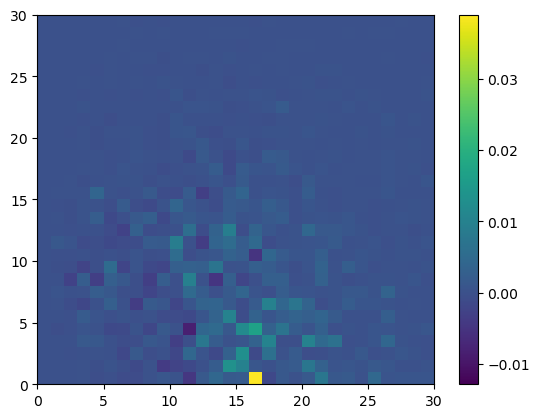

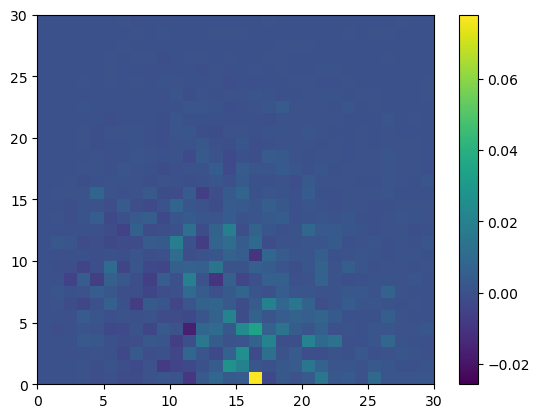

(0.0, 30.0)

In [113]:

# CBC2_h = imfilter(twodim_zeropad(rfft(ψBC)), reflect(twodim_zeropad(rfft(∂xψBT))))

# CBC2_h = conv2(twodim_zeropad(fft(ψBC)), twodim_zeropad(fft(∂xψBT)))

# CBC2 = @. S32 * (f0 / H[2]) * ψBC * ∂xψBT

# CBC2_h = S32 * (f0 / H[2]) * conv(twodim_zeropad(ψBCh), twodim_zeropad(∂xψBTh))
CBC2_h = S32 * (f0 / H[2]) * conj.(ψBCh) .* ∂xψBTh

# plt.pcolormesh(real.(NLBT[:,:,1]))

# plt.colorbar()

# plt.xlim(0,30)
# plt.ylim(0,30)



plt.figure()
plt.pcolormesh(real.(CBC2_h)')
# plt.pcolormesh((real.(conj.(ψBCh) .* ∂xψBTh))')


plt.colorbar()

edge_ind_x = 255
edge_ind_y = 512+1024-2

# plt.xlim(edge_ind_x, edge_ind_x + 30)
# plt.ylim(edge_ind_y, edge_ind_y + 30)

plt.xlim(0,30)
plt.ylim(0,30)


plt.figure()
# plt.pcolormesh((real.(T_D2h))')
plt.pcolormesh((real.(CBC))')

plt.colorbar()

plt.xlim(0,30)
plt.ylim(0,30)

# plt.figure()

# plt.plot(abs.(NLBT_x2kh)[1, 1:40])

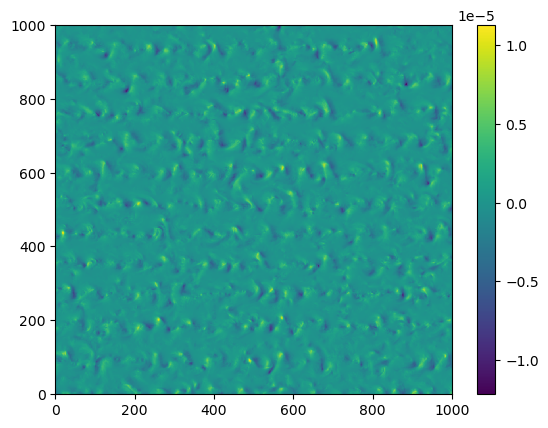

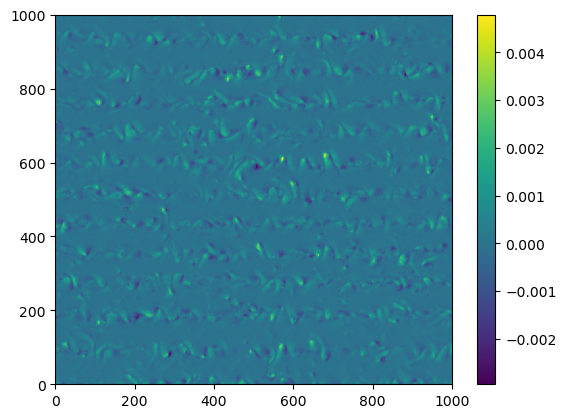

(0.0, 1000.0)

In [11]:
NLBT_cons = deepcopy(vars.u[:,:,1])



CBChh = @. S32 * (params.f₀ / params.H[1]) * ( ψBCh * ∂xψBTh ) # these are equivalent!


# ldiv2D!(NLBT_cons, rfftplan, grid.kr .* deepcopy(NLBT[:,:,1]))
ldiv2D!(NLBT_cons, rfftplan, deepcopy(CBChh))


CBC2 = @. - (f0 / H[2]) * ψBC * ∂xψBT



T_D2 = w_32 .* ψBC 
D_BC2 = @. ψBC * (ζBC - ζBT)
# r =  @. J_ψBT_ζBT

# pc1 = plt.pcolormesh(D_BC2')
pc1 = plt.pcolormesh(w_32_mask')



plt.colorbar(pc1)

# plt.contour(ζBT', levels=[0.])

xl1 = 0; xl2=1000
yl1 = 0; yl2=1000

plt.xlim(xl1, xl2)
plt.ylim(yl1, yl2)

plt.figure()

# pc2 = plt.pcolormesh(CBC2')
pc2 = plt.pcolormesh(T_D2')

plt.colorbar(pc2)

# m = maximum(abs.(ζBT))
# # plt.contour(ζBT', levels=[0.])

plt.xlim(xl1, xl2)
plt.ylim(yl1, yl2)


# # plt.xlim(0,200)
# # plt.ylim(0,200)


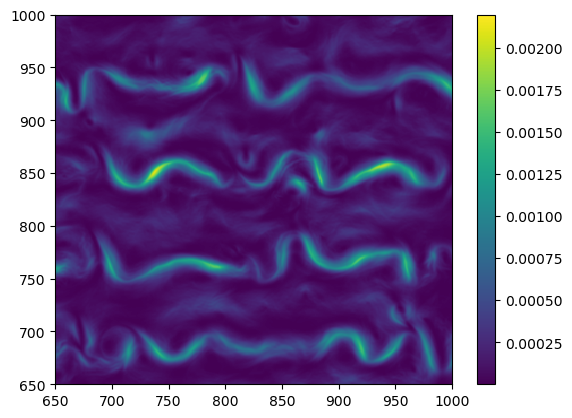

(650.0, 1000.0)

In [11]:
CBC_x = deepcopy(vars.u[:,:,1])

CBC_t = deepcopy(CBC)

CBC_alt_x = @. ∂xψBT^2 + ∂yψBT^2 


ldiv2D!(CBC_x, rfftplan, CBC_t)

pc1 = plt.pcolormesh(CBC_alt_x')
plt.colorbar(pc1)

# plt.contour(ζBT', levels=[0.])

plt.xlim(xl1, xl2)
plt.ylim(yl1, yl2)

# plt.xlim(0,200)
# plt.ylim(0,200)


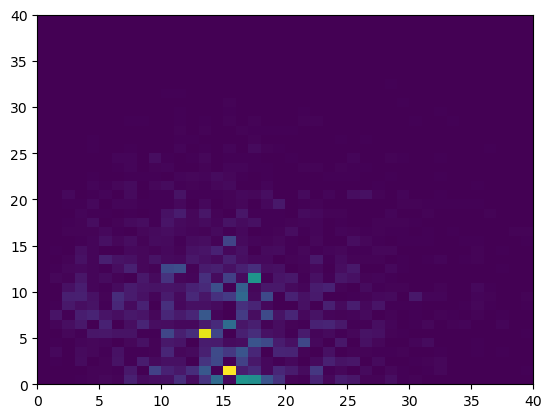

(0.0, 40.0)

In [33]:
# plt.pcolormesh(abs.(ψBCh)')      # at jet scale
# plt.pcolormesh(abs.(ψBTh)')   # at jet scale
# plt.pcolormesh(abs.(∂xψBTh)')   # at CBC scale

# plt.pcolormesh(abs.(w_32h)')    # at both scales
plt.pcolormesh(abs.(CBC)')    # at both scales
# plt.pcolormesh(abs.(J_ψBT_ζBTh)')   # mostly at CBC scale...
# plt.pcolormesh(abs.(conj.(ψBTh) .* J_ψBT_ζBTh)')   # mostly at jet scale...but at both

# CBC is set by barotropic velocities
# TD is set by baroclinic streamfunction


plt.xlim(0,40)
plt.ylim(0,40)



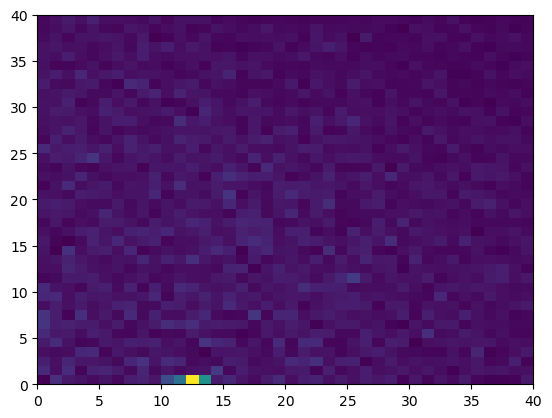

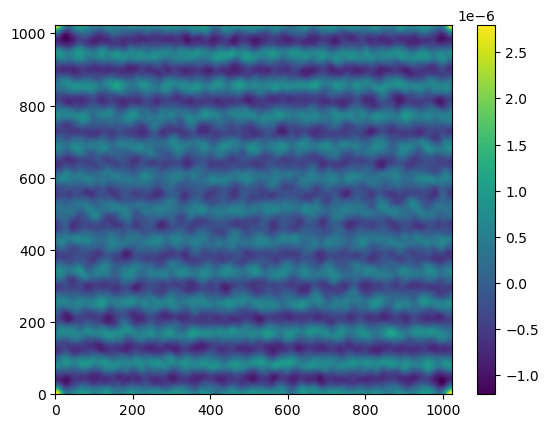

PyObject <matplotlib.colorbar.Colorbar object at 0x1459af5df160>

In [65]:
# aaa = FFTW.r2r(arr,FFTW.R2HC)
EKE_xy = @. ∂xψBT^2 + ∂yψBT^2 

plt.pcolormesh(abs.(rfft(D_BC2 .- mean(D_BC2))))

plt.xlim(0,40)
plt.ylim(0,40)

plt.figure()
plt.pcolormesh(irfft(NLBT[:,:,2], 1024)')

plt.colorbar()

0.00015675626115534851
1.216799299380645e-7
3.5593916472391297e-6


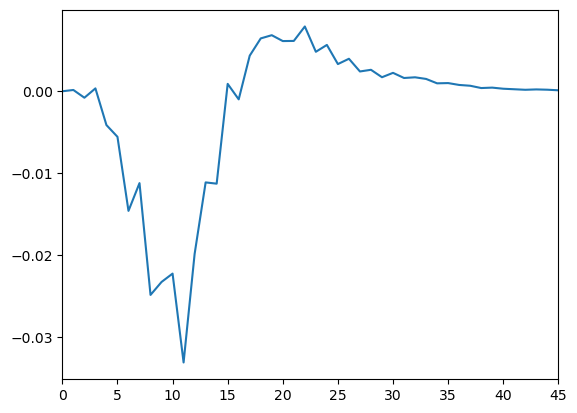

(0.0, 45.0)

In [111]:
# # plt.plot(isotropic_mean(NL_EAPE, prob.grid))
# plt.plot(isotropic_mean(NLBC[:,:,3], prob.grid))

# println(sum(grid.kr .* isotropic_mean(NL_EAPE, prob.grid)))
# println(sum(grid.kr .* isotropic_mean(NLBC[:,:,3], prob.grid)))
# println(sum(grid.kr .* isotropic_mean(CBC, prob.grid)))

# plt.xlim(0,45)

# # plt.figure()
# # plt.plot(isotropic_mean(CBC, prob.grid))


# # plt.xlim(0,45)



1.592832748231087e-5
1.8324808372015428e-7
-1.3220159039180924e-5
0.19864500599677865
-0.10590514568607934
-0.07258202182673505


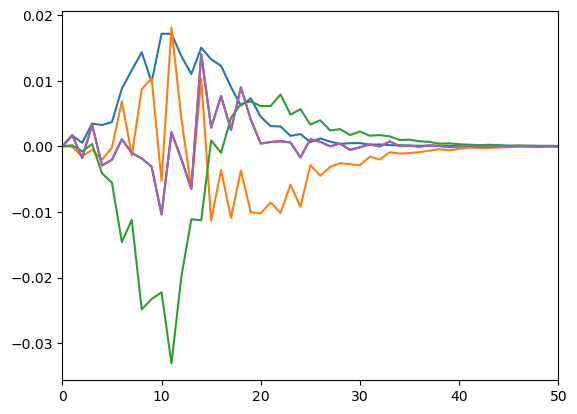

(0.0, 50.0)

In [31]:
# plt.figure()
# plt.pcolormesh(abs.(NL_EAPE))
# plt.colorbar()

# plt.xlim(0,50); plt.ylim(0,50)

# plt.figure()
# plt.pcolormesh(abs.(NLBC[:,:,3]))
# plt.colorbar()

# plt.xlim(0,50); plt.ylim(0,50)

println(mean(real((CBC))))

println(mean(real(NLBC[:,:,3])))

println(mean(real(T_Dh)))

println(sum(isotropic_mean(CBC, prob.grid)))

println(sum(isotropic_mean(NLBC[:,:,3], prob.grid)))

println(sum(isotropic_mean(T_Dh, prob.grid)))

plt.plot(isotropic_mean(CBC, prob.grid))
plt.plot(isotropic_mean(T_Dh, prob.grid))
plt.plot(isotropic_mean(NLBC[:,:,3], prob.grid))
plt.plot(isotropic_mean(CBC .+ T_Dh .+ NLBC[:,:,3], prob.grid))
plt.plot(isotropic_mean(CBC, prob.grid) .+ isotropic_mean(T_Dh, prob.grid) .+ isotropic_mean(NLBC[:,:,3], prob.grid))

plt.xlim(0,50)

In [9]:
    ### Create isotropic wavenumber grid ###
nx=Nx    
nk = Int(nx / 2 + 1)
	nl = nx

	kr = prob.grid.kr
	l = prob.grid.l
	Kr = @. sqrt(kr^2 + l^2)

	krmax = maximum(kr)
	lmax = maximum(abs.(l))
	Kmax = sqrt(krmax^2 + lmax^2)
	Kmin = 0.

	dkr = 2 * pi / Lx
	dl = dkr
	dKr = sqrt(dkr^2 + dl^2)
 
	K = Kmin:dKr:Kmax-dKr
	K_id = lastindex(K)


512

In [57]:

    ##### ENERGY BUDGET TERMS BELOW ###

    ### KEFlux1 ###

    KEFlux1 = zeros(K_id)

ψh = deepcopy(vars.ψh)
fwdtransform!(ψh, ψ, params)

	    psih = ψh
	    zetah = -grid.Krsq .* ψh


	for j = 1:K_id
        # Get stream functions and vorticity


		# Define high-pass filter matrix
		hpf = ifelse.(Kr .> K[j], Kr ./ Kr, 0 .* Kr)

		# Filter the Fourier transformed fields
		psih_hpf = hpf .* psih

		# Inverse transform the filtered fields
		psi_hpf = A(zeros(nx, nx, nlayers))
		invtransform!(psi_hpf, psih_hpf, params)

		# Calculate spectral derivatives of zeta
		zetah_ik = im .* grid.kr .* zetah
		zetah_il = im .* grid.l .* zetah

		# Calculate real derivatives of zeta
		zeta_dx = A(zeros(nx, nx, nlayers))
		invtransform!(zeta_dx, zetah_ik, params)

		zeta_dy = A(zeros(nx, nx, nlayers))
		invtransform!(zeta_dy, zetah_il, params)

		# Create views of only upper layer fields
		psi_hpf_1 = view(psi_hpf, :, :, 1)
		u_1 = u1
		v_1 = v1
		zeta_dx_1 = view(zeta_dx, :, :, 1)
		zeta_dy_1 = view(zeta_dy, :, :, 1)

		view(KEFlux1, j) .= mean(psi_hpf_1 .* u_1 .* zeta_dx_1 + psi_hpf_1 .* v_1 .* zeta_dy_1)
	end


In [55]:
k=10

		# Define high-pass filter matrix
		hpf = ifelse.(Kr .> K[j], Kr ./ Kr, 0 .* Kr)

		# Filter the Fourier transformed fields
		psih_hpf = hpf .* psih

		# Inverse transform the filtered fields
		psi_hpf = A(zeros(nx, nx, nlayers))
		invtransform!(psi_hpf, psih_hpf, params)

		# Calculate spectral derivatives of zeta
		zetah_ik = im .* grid.kr .* zetah
		zetah_il = im .* grid.l .* zetah

		# Calculate real derivatives of zeta
		zeta_dx = A(zeros(nx, nx, nlayers))
		invtransform!(zeta_dx, zetah_ik, params)

		zeta_dy = A(zeros(nx, nx, nlayers))
		invtransform!(zeta_dy, zetah_il, params)

		# Create views of only upper layer fields
		psi_hpf_1 = view(psi_hpf, :, :, 1)
		u_1 = u1
		v_1 = v1
		zeta_dx_1 = view(zeta_dx, :, :, 1)
		zeta_dy_1 = view(zeta_dy, :, :, 1)

		mean(psi_hpf_1 .* u_1 .* zeta_dx_1 + psi_hpf_1 .* v_1 .* zeta_dy_1)

-2.8272774843121063e-27

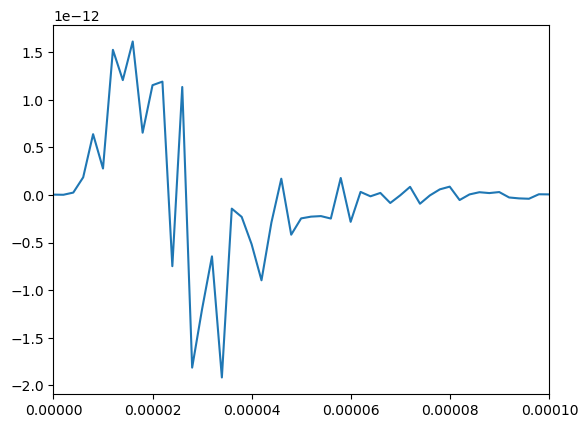

(0.0, 0.0001)

In [62]:
plt.plot(K[1:end-1], (KEFlux1[1:end-1] .- KEFlux1[2:end]))

plt.xlim(0,0.0001)

In [16]:

i=7
j=1
k=6


h0 = (h0s[i], 0.0)
kappa_loc = kappas[j]
mu_loc = mus[k]

global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
global topo_PV, eta = define_topo(model_params)
global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)

beta = betas[7]
global model_params = redef_mu_kappa_beta(model_params, mu_loc, kappa_loc, beta)


# a = load(alt_data_dir*jld_name(model_params,71.99))
a = load(alt_data_dir*jld_name(model_params,71.95))

    

# energies are: (1) BTEKE, (2) BCEKE, (3) EAPE; (4) CBC; (5) Tflat, (6) Ttopo; , (7) DBT, (8) DBC;
#               (9) NLBC2BT, (10) NLBTEKE, (11) NLBT2BC; (12) NLBVEKE (13) NLBCEAPE (14) resid

# layer2_Htot_4000.0_L_2pi4.449E+06_y_slope_h0_0.000E+00_beta3.116E-12_uni_shear_uni_strat_mu8.826E-08_kappa0.000E+00_nu0.000E+00_res1024_yr57.7.jld


    ψ = a["jld_data"]["psi_yrs_end"]

    ψh = deepcopy(vars.uh)

    # rfftplanlayered = plan_flows_rfft(A{T, 3}(undef, grid.nx, grid.ny, nlayers), [1, 2]; flags=FFTW.MEASURE)

    fwdtransform!(ψh, ψ, params);


In [18]:
    ### Create isotropic wavenumber grid ###
nx=Nx    
nk = Int(nx / 2 + 1)
	nl = nx

	kr = prob.grid.kr
	l = prob.grid.l
	Kr = @. sqrt(kr^2 + l^2)

	krmax = maximum(kr)
	lmax = maximum(abs.(l))
	Kmax = sqrt(krmax^2 + lmax^2)
	Kmin = 0.

	dkr = 2 * pi / Lx
	dl = dkr
	dKr = sqrt(dkr^2 + dl^2)
 
	K = Kmin:dKr:Kmax-dKr
	K_id = lastindex(K)

512

In [45]:



    ##### ENERGY BUDGET TERMS BELOW ###

    APEFlux1 = zeros(K_id)
    TDFlux = zeros(K_id)
    CBCFlux = zeros(K_id)

	    psih = ψh

    # assigning basic variables
    ψBC = 0.5 * (ψ[:,:,1] .- ψ[:,:,2])
    ψBT = 0.5 * (ψ[:,:,1] .+ ψ[:,:,2])

    ψBCh = deepcopy(vars.uh[:,:,1])
    ψBTh = deepcopy(vars.uh[:,:,1])

    mul2D!(ψBCh, rfftplan, deepcopy(ψBC))
    mul2D!(ψBTh, rfftplan, deepcopy(ψBT))
    
    U₁, U₂, = view(params.U, :, :, 1), view(params.U, :, :, 2)
    
    S32 = CUDA.@allowscalar f0 * U₁[1,1] / g′

    # streamfunction stuff
    ∂xψBTh = im * grid.kr .* ψBTh
    ∂yψBTh = im * grid.l .* ψBTh
    
    ∂xψBT = deepcopy(vars.u[:,:,1])
    ∂yψBT = deepcopy(vars.u[:,:,1])

    ldiv2D!(∂xψBT, rfftplan, im * grid.kr .* ψBTh)
    ldiv2D!(∂yψBT, rfftplan, im * grid.l .* ψBTh)

    ∂xψBCh = im * grid.kr .* ψBCh
    ∂yψBCh = im * grid.l .* ψBCh

    ∂xψBC = deepcopy(vars.u[:,:,1])
    ∂yψBC = deepcopy(vars.u[:,:,1])

    ldiv2D!(∂xψBC, rfftplan, im * grid.kr .* ψBCh)
    ldiv2D!(∂yψBC, rfftplan, im * grid.l .* ψBCh)

        # Create views of single layer fields
        uBT = -∂yψBT
        vBT = ∂xψBT
        uBC = -∂yψBC
        vBC = ∂xψBC

    for j = 1:K_id

		# Define high-pass filter matrix
		hpf = ifelse.(Kr .> K[j], Kr ./ Kr, 0 .* Kr)

		# Filter the Fourier transformed fields
		psi_BCh_hpf = hpf .* 0.5 .* (psih[:,:,1] .- psih[:,:,2])
    
        
        # Inverse transform the filtered fields
		psi_BC_hpf = A(zeros(nx, nx))
		ldiv2D!(psi_BC_hpf, rfftplan, psi_BCh_hpf)
        

        # for Td as well
        w_32h = calc_w_int(vars, grid, ψ, params, model_params)
        # T_Dh = @. - (f0 / H[2]) * w_32h * conj(ψBCh)
        # T_Dh .+= conj.(T_Dh)
    
        w_32 = deepcopy(vars.u[:,:,1])
        ldiv2D!(w_32, rfftplan, deepcopy(w_32h))
    

		view(APEFlux1, j) .= mean(- Ld^-2 .* psi_BC_hpf .* (uBT .* vBC .- uBC .* vBT))
        view(TDFlux, j) .= mean(- (f0 / H[2]) * psi_BC_hpf .* w_32)
        view(CBCFlux, j) .= mean(S32 * (f0 / params.H[1]) * (psi_BC_hpf .* ∂xψBT))
	end

-5.048709749436855e-29
-1.7980079667292294e-12
1.8059047105586989e-12


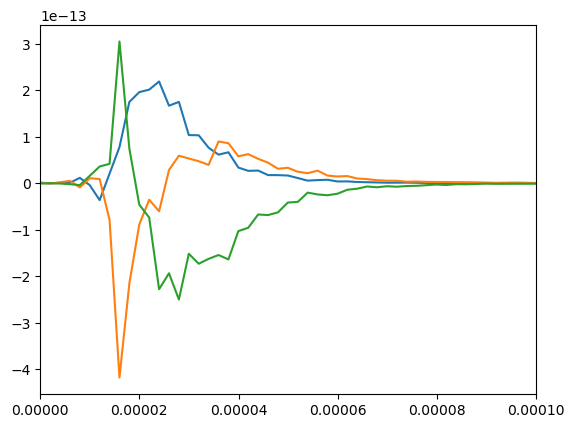

(0.0, 0.0001)

In [15]:
plt.plot(K[1:end-1], (CBCFlux[1:end-1] .- CBCFlux[2:end]))
plt.plot(K[1:end-1], (APEFlux1[1:end-1] .- APEFlux1[2:end]))
plt.plot(K[1:end-1], (TDFlux[1:end-1] .- TDFlux[2:end]))

# plt.plot(K, APEFlux1)

println(sum((APEFlux1[1:end-1] .- APEFlux1[2:end])))
println(sum((TDFlux[1:end-1] .- TDFlux[2:end])))
println(sum((CBCFlux[1:end-1] .- CBCFlux[2:end])))


plt.xlim(0,0.0001)

In [117]:
    TDFlux1 = zeros(K_id)

	    psih = ψh

    for j = 1:K_id

		# Define high-pass filter matrix
		hpf = ifelse.(Kr .> K[j], Kr ./ Kr, 0 .* Kr)

		# Filter the Fourier transformed fields
		psi_BCh_hpf = hpf .* 0.5 .* (psih[:,:,1] .- psih[:,:,2])
    
        
        # Inverse transform the filtered fields
		psi_BC_hpf = A(zeros(nx, nx))
		ldiv2D!(psi_BC_hpf, rfftplan, psi_BCh_hpf)
        
		view(TDFlux1, j) .= mean(- (f0 / H[2]) .* psi_BC_hpf .* w_32)
	end

-6.210713527794483e-12


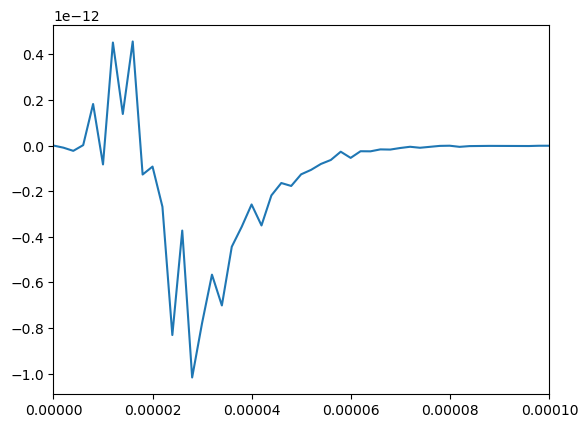

(0.0, 0.0001)

In [118]:
plt.plot(K[1:end-1], (TDFlux1[1:end-1] .- TDFlux1[2:end]))
# plt.plot(K, TDFlux1)

println(sum((TDFlux1[1:end-1] .- TDFlux1[2:end])))

plt.xlim(0,0.0001)

In [97]:
CBCFlux1 = zeros(K_id)

	    psih = ψh

    for j = 1:K_id

		# Define high-pass filter matrix
		hpf = ifelse.(Kr .> K[j], Kr ./ Kr, 0 .* Kr)

		# Filter the Fourier transformed fields
		psi_BCh_hpf = hpf .* 0.5 .* (psih[:,:,1] .- psih[:,:,2])
    
        # Inverse transform the filtered fields
		psi_BC_hpf = A(zeros(nx, nx))
		ldiv2D!(psi_BC_hpf, rfftplan, psi_BCh_hpf)

        vBT = 0.5 * (v1 .+ v2)
        
		view(CBCFlux1, j) .= mean(S32 * (params.f₀ / params.H[1]) .* psi_BC_hpf .* vBT)
	end

#     CBC = @. S32 * (params.f₀ / params.H[1]) * ( conj(ψBCh) * ∂xψBTh + ψBCh * conj(∂xψBTh)) # these are equivalent!


7.610052822553995e-12


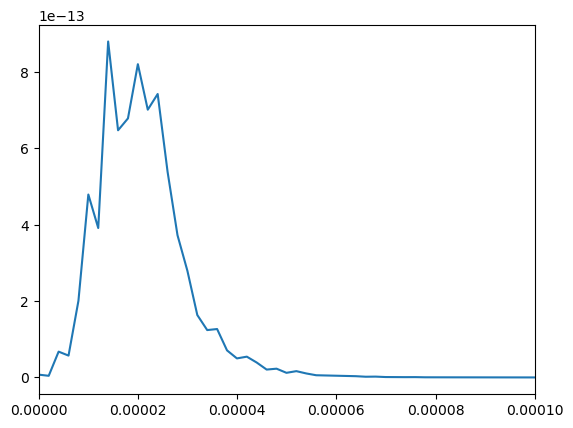

(0.0, 0.0001)

In [98]:
plt.plot(K[1:end-1], (CBCFlux1[1:end-1] .- CBCFlux1[2:end]))
# plt.plot(K, CBCFlux1)

println(sum((CBCFlux1[1:end-1] .- CBCFlux1[2:end])))

plt.xlim(0,0.0001)

-1.2048514269082298
-1.8793732373402119


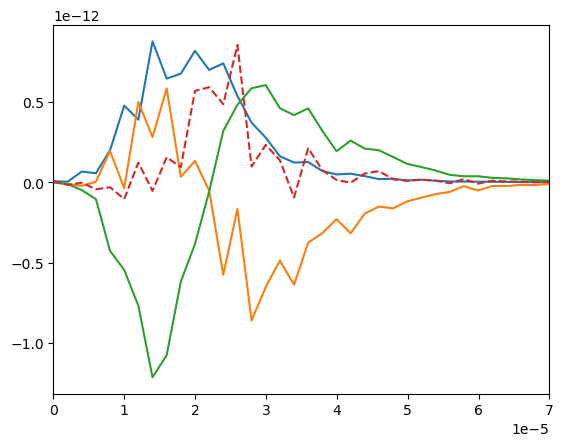

(0.0, 7.0e-5)

In [115]:
println((1.592832748231087e-5)/(-1.3220159039180924e-5))
println(sum((CBCFlux1[1:end-1] .- CBCFlux1[2:end])) / sum((TDFlux1[1:end-1] .- TDFlux1[2:end])))


plt.plot(K[1:end-1], (CBCFlux1[1:end-1] .- CBCFlux1[2:end]))
plt.plot(K[1:end-1], (TDFlux1[1:end-1] .- TDFlux1[2:end]))
plt.plot(K[1:end-1], (APEFlux1[1:end-1] .- APEFlux1[2:end]))

re = (CBCFlux1[1:end-1] .- CBCFlux1[2:end]) .+ (TDFlux1[1:end-1] .- TDFlux1[2:end]) .+ (APEFlux1[1:end-1] .- APEFlux1[2:end])
plt.plot(K[1:end-1], re, "--")

plt.xlim(0,0.00007)


1.592832748231087e-5
1.8324808372015428e-7
-8.69607840108543e-6
0.19864500599677865
-0.10590514568607934
-0.027042675417296592


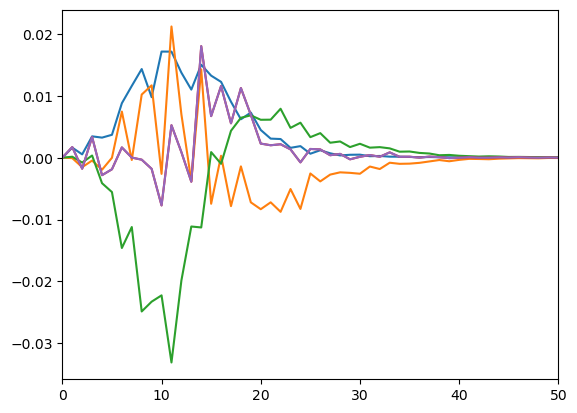

(0.0, 50.0)

In [104]:
# plt.figure()
# plt.pcolormesh(abs.(NL_EAPE))
# plt.colorbar()

# plt.xlim(0,50); plt.ylim(0,50)

# plt.figure()
# plt.pcolormesh(abs.(NLBC[:,:,3]))
# plt.colorbar()

# plt.xlim(0,50); plt.ylim(0,50)

println(mean(real((CBC))))

println(mean(real(NLBC[:,:,3])))

println(mean(real(T_Dh)))

println(sum(isotropic_mean(CBC, prob.grid)))

println(sum(isotropic_mean(NLBC[:,:,3], prob.grid)))

println(sum(isotropic_mean(T_Dh, prob.grid)))

plt.plot(isotropic_mean(CBC, prob.grid))
plt.plot(isotropic_mean(T_Dh, prob.grid))
plt.plot(isotropic_mean(NLBC[:,:,3], prob.grid))
plt.plot(isotropic_mean(CBC .+ T_Dh .+ NLBC[:,:,3], prob.grid))
plt.plot(isotropic_mean(CBC, prob.grid) .+ isotropic_mean(T_Dh, prob.grid) .+ isotropic_mean(NLBC[:,:,3], prob.grid))

plt.xlim(0,50)

In [12]:

    KEBCFlux = zeros(K_id)

	    psih = ψh

        # Create views of single layer fields
        # uBT = 0.5 * (u1 .+ u2)
        # vBT = 0.5 * (v1 .+ v2)
        uBC = deepcopy(-∂yψBC)
        vBC = deepcopy(∂xψBC)
    

    ###################################################
        zeta_BTh = -grid.Krsq .* 0.5 .* (psih[:,:,1] .+ psih[:,:,2])

		# Calculate real derivatives of zeta
		zeta_BT_dx = A(zeros(nx, nx))
		ldiv2D!(zeta_BT_dx, rfftplan, im .* grid.kr .* zeta_BTh)

		zeta_BT_dy = A(zeros(nx, nx))
		ldiv2D!(zeta_BT_dy, rfftplan,im .* grid.l .* zeta_BTh)

    for j = 1:K_id

		# Define high-pass filter matrix
		hpf = ifelse.(Kr .> K[j], Kr ./ Kr, 0 .* Kr)

		# Filter the Fourier transformed fields
		psi_BCh_hpf = hpf .* 0.5 .* (psih[:,:,1] .- psih[:,:,2])
    
        # Inverse transform the filtered fields
		psi_BC_hpf = A(zeros(nx, nx))
		ldiv2D!(psi_BC_hpf, rfftplan, psi_BCh_hpf)


    ########################################################
    
		view(KEBCFlux, j) .= mean(- Ld^-2 .* psi_BC_hpf .* (uBC .* zeta_BT_dx .+ vBC .* zeta_BT_dy))
	end



# @views NLBC[:,:,2] = @. conj(ψBCh) * im * (uBC * zeta_BT_dx + vBC * zeta_BT_dy)

-2.5860865585219735e-37
-2.0576055517649314e-7


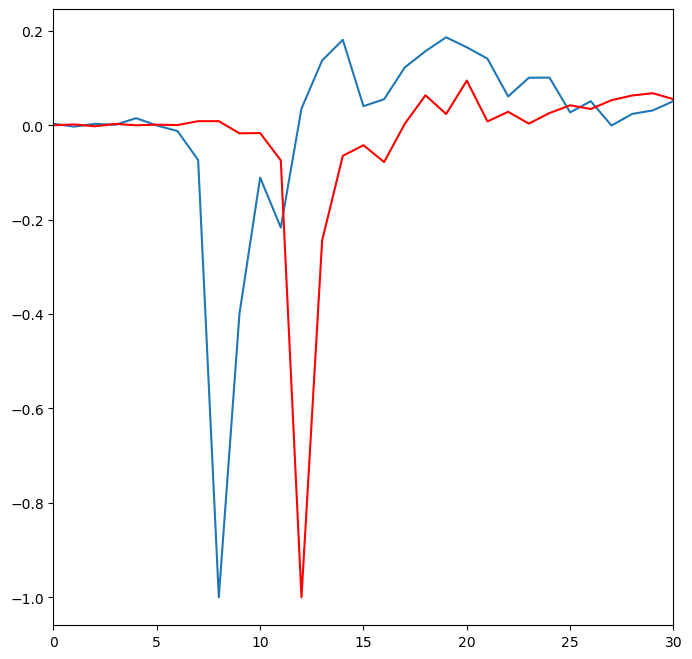

(0.0, 30.0)

In [30]:
fig,ax = plt.subplots(1,1, figsize=(8,8))

ax.plot(K[1:end-1], (KEBCFlux[1:end-1] .- KEBCFlux[2:end]) ./ maximum(abs.(KEBCFlux[1:end-1] .- KEBCFlux[2:end])))
# plt.plot(K, APEFlux1)

# axt = ax.twinx()
ax.plot(grid.kr, -grid.kr .* isotropic_mean(NLBC[:,:,2], prob.grid) ./ maximum(abs.(grid.kr .* isotropic_mean(-NLBC[:,:,2], prob.grid))), "r-")

println(sum((KEBCFlux[1:end-1] .- KEBCFlux[2:end])))
println(sum(-grid.kr .* isotropic_mean(NLBC[:,:,2], prob.grid) ))

# plt.xlim(0,0.0001)

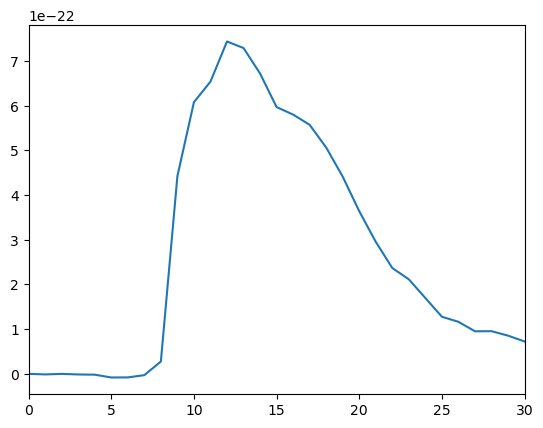

(0.0, 30.0)

In [37]:
plt.plot(KEBCFlux)
plt.xlim(0,30)

179

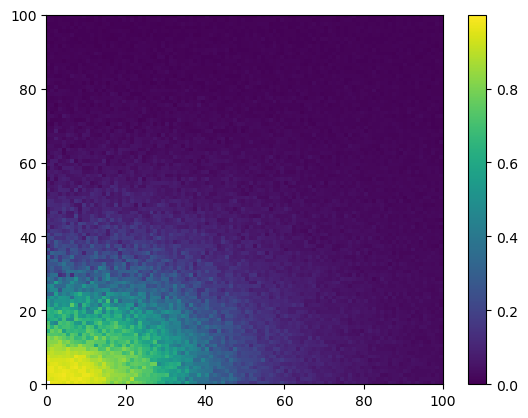

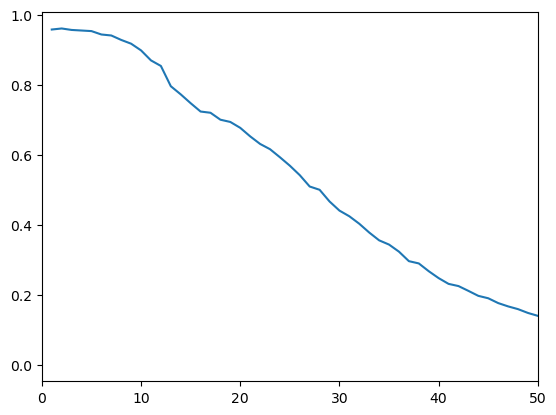

(0.0, 50.0)

In [72]:
plt.pcolormesh(a["jld_data"]["coh_DBC_TD"])
plt.colorbar()

plt.xlim(0,100)
plt.ylim(0,100)

plt.figure()
plt.plot(isotropic_mean(a["jld_data"]["coh_DBC_TD"] , prob.grid))

plt.xlim(0,50)

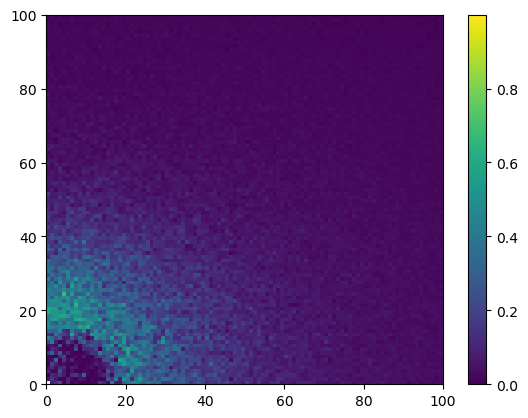

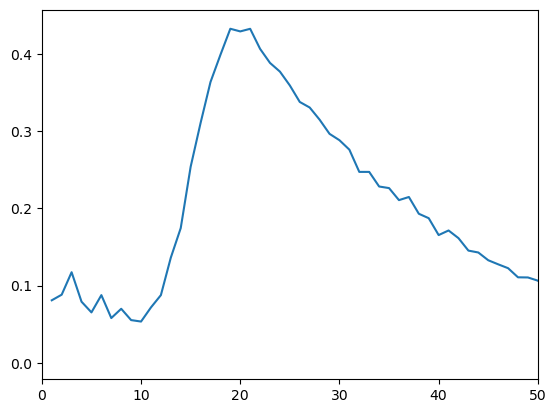

(0.0, 50.0)

In [73]:
plt.pcolormesh(a["jld_data"]["coh_DBC_NLBC2BT"] )
plt.colorbar()

plt.xlim(0,100)
plt.ylim(0,100)

plt.figure()
plt.plot(isotropic_mean(a["jld_data"]["coh_DBC_NLBC2BT"], prob.grid))

plt.xlim(0,50)

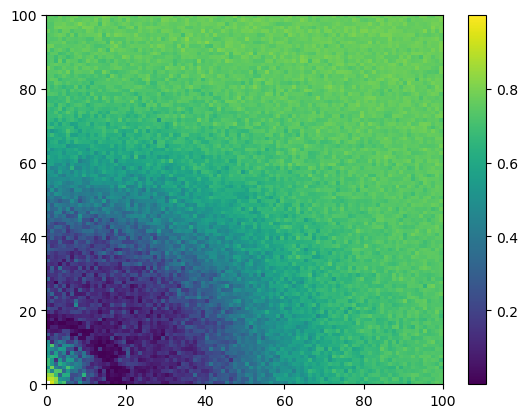

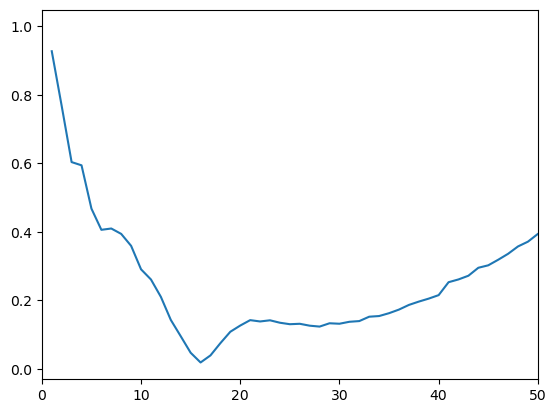

(0.0, 50.0)

In [74]:
plt.pcolormesh(a["jld_data"]["coh_NLBCEKE_NLBC2BT"] )
plt.colorbar()

plt.xlim(0,100)
plt.ylim(0,100)

plt.figure()
plt.plot(isotropic_mean(a["jld_data"]["coh_NLBCEKE_NLBC2BT"] , prob.grid))

plt.xlim(0,50)

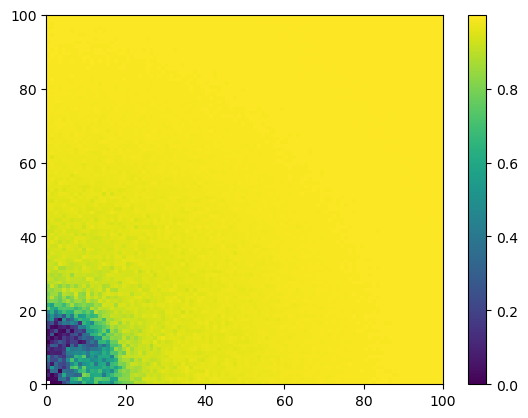

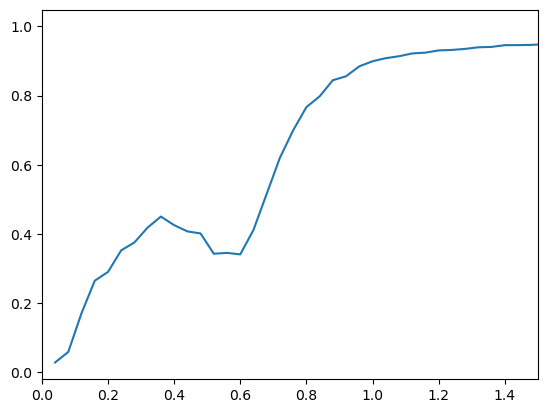

(0.0, 1.5)

In [76]:
plt.pcolormesh(a["jld_data"]["coh_NLBCEKE_TD"] )
plt.colorbar()

plt.xlim(0,100)
plt.ylim(0,100)

plt.figure()
plt.plot(prob.grid.kr .* Ld, isotropic_mean(a["jld_data"]["coh_NLBCEKE_TD"], prob.grid))

plt.xlim(0, 1.5)

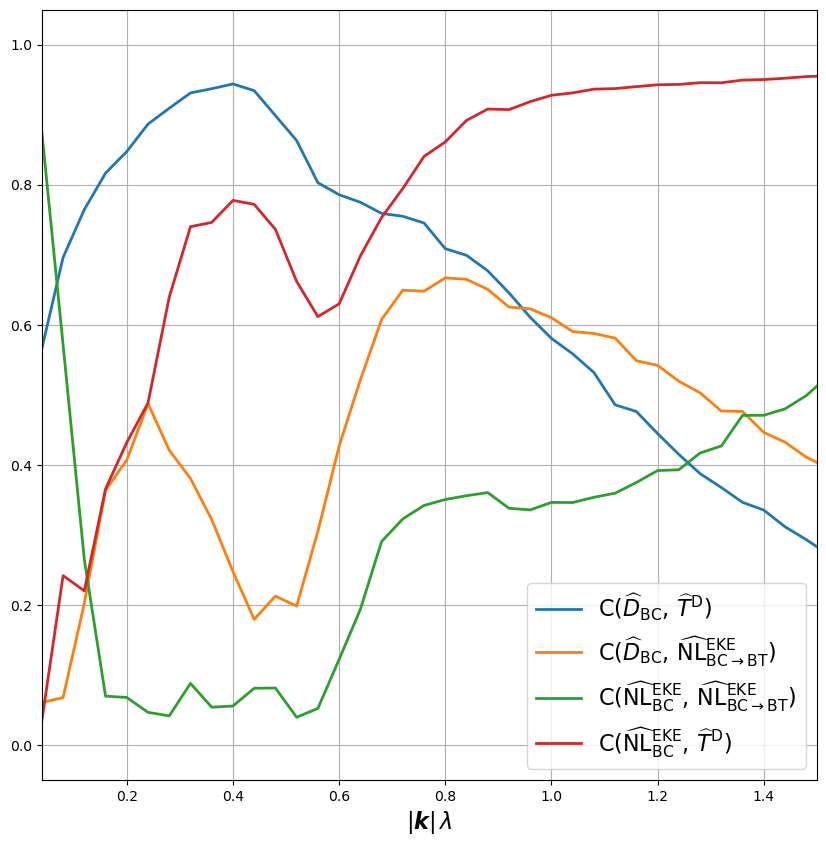

PyObject Text(0.5, 36.99999999999999, '$|\\boldsymbol{k}| \\, \\lambda$')

In [29]:
# coherence plot for kappa*=4.0, beta* = 0.

fig, ax = plt.subplots(1, 1, figsize=(10,10))

fsize = 16

x = prob.grid.kr .* Ld

ax.plot(x, isotropic_mean(a["jld_data"]["coh_DBC_TD"] , prob.grid), label=L"\mathrm{C} ( \widehat{D}_\mathrm{BC}, \, \widehat{T}^\mathrm{D})", linewidth=2.0)
ax.plot(x, isotropic_mean(a["jld_data"]["coh_DBC_NLBC2BT"] , prob.grid), label=L"\mathrm{C} ( \widehat{D}_\mathrm{BC}, \, \widehat{\mathrm{NL}}^\mathrm{EKE}_{\mathrm{BC} \rightarrow \mathrm{BT}})", linewidth=2.0)
ax.plot(x, isotropic_mean(a["jld_data"]["coh_NLBCEKE_NLBC2BT"] , prob.grid), label=L"\mathrm{C} ( \widehat{\mathrm{NL}}_\mathrm{BC}^\mathrm{EKE}, \, \widehat{\mathrm{NL}}^\mathrm{EKE}_{\mathrm{BC} \rightarrow \mathrm{BT}})", linewidth=2.0)
ax.plot(x, isotropic_mean(a["jld_data"]["coh_NLBCEKE_TD"] , prob.grid), label=L"\mathrm{C} ( \widehat{\mathrm{NL}}_\mathrm{BC}^\mathrm{EKE}, \,  \widehat{T}^\mathrm{D})", linewidth=2.0)


ax.set_xlim(x[2], 1.5)

ax.legend(fontsize = fsize)

ax.grid()

ax.set_xlabel(L"|\boldsymbol{k}| \, \lambda", fontsize = fsize)

In [88]:

i=7
j=1
k=2


h0 = (h0s[i], 0.0)
kappa_loc = kappas[j]
mu_loc = mus[k]

global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
global topo_PV, eta = define_topo(model_params)
global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)

beta = betas[7]
global model_params = redef_mu_kappa_beta(model_params, mu_loc, kappa_loc, beta)


# a = load(alt_data_dir*jld_name(model_params,71.99))
a = load(alt_data_dir*jld_name(model_params,71.95))

    

Dict{String, Any} with 1 entry:
  "jld_data" => Dict{String, Any}("ph_slices"=>0.031725, "two_layer_modal_lengt…

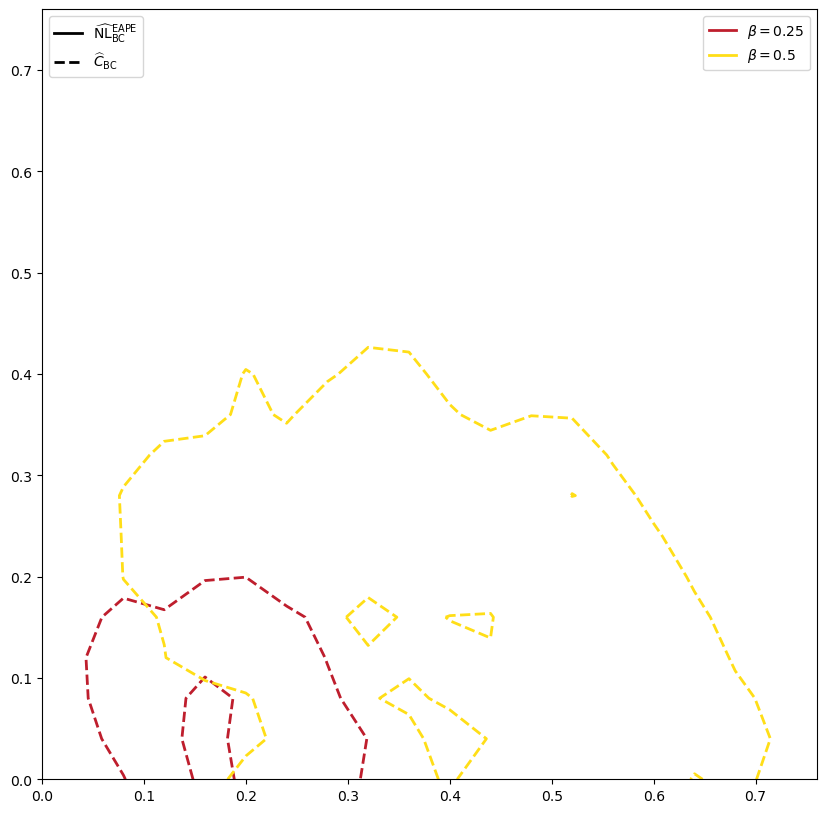

(0.0, 0.76)

In [74]:
fig, ax = plt.subplots(1,3, figsize=(20,7.5))


beta_cont = [betas[8], betas[9]]
Bauhaus_colors = ["#000000", "#be1e2d", "#ffde17", "#ffffff"]

x = prob.grid.kr .* Ld
y = prob.grid.l .* Ld

xv = first.(Iterators.product(x,y))[:,1,1,:]
yv = last.(Iterators.product(x,y))[:,1,1,:]

labels = []
custom_lines = []

mu_loc = mus[2]

for (i, b) in enumerate(beta_cont)
    global model_params = redef_mu_kappa_beta(model_params, mu_loc, kappa_loc, b)

    a = load(alt_data_dir*jld_name(model_params,71.95))

    ac = ax.contour(xv, yv, a["jld_data"]["CBC"] ./ maximum(a["jld_data"]["CBC"]), colors=Bauhaus_colors[i+1], linestyles="dashed", levels=[0.25, 0.75], linewidths=2.0)
    # ac = ax.contour(xv, yv,  a["jld_data"]["NL_BC_EAPE"] ./ maximum(a["jld_data"]["NL_BC_EAPE"]), colors=Bauhaus_colors[i+1], linestyles="solid", levels=[0.25, 0.75], linewidths=2.0)

    ax.clabel(ac, inline=1, fontsize=14)

    labels = [labels; L"\beta = "*string(round(b * 2 * Ld^2 / U[1],digits=3))]
    custom_lines = [custom_lines; matplotlib.lines.Line2D([0], [0], color=Bauhaus_colors[i+1], lw=2.0)]

end

########################################
## legend
########################################

# legend for beta values
legend1 = ax.legend(custom_lines, labels, loc="upper right")

# legend for two variables plotted
ax.legend([matplotlib.lines.Line2D([0], [0], color="black", linestyle="solid", lw=2.0), matplotlib.lines.Line2D([0], [0], color="black", linestyle="dashed", lw=2.0)], [L"\widehat{\mathrm{NL}}_\mathrm{BC}^\mathrm{EAPE}", L"\widehat{C}_\mathrm{BC}"], loc="upper left")

PyPlot.gca().add_artist(legend1)
########################################
## legend end
########################################


ax.set_xlim(x[1], x[20])
ax.set_ylim(y[1], y[20])

# note that plotted values are positive



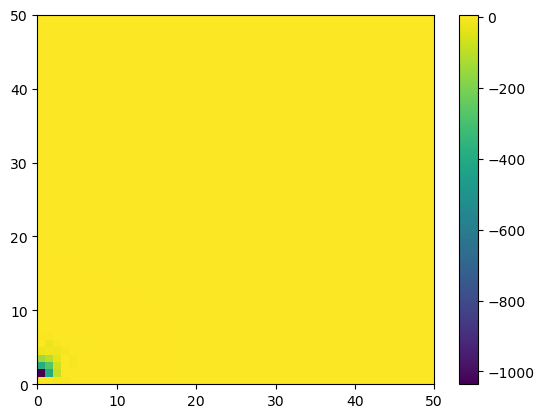

(0.0, 50.0)

In [23]:

x = prob.grid.kr .* Ld
y = prob.grid.l .* Ld

xv = first.(Iterators.product(x,y))[:,1,1,:]
yv = last.(Iterators.product(x,y))[:,1,1,:]


# plt.contourf(xv, yv, grid.Krsq .* real.(CBC))
plt.pcolormesh(a["jld_data"]["NL_BC_EAPE"])

plt.colorbar()

# plt.xlim(x[1], x[50])
# plt.ylim(y[1], y[50])
# plt.ylim(-y[30], y[5])

plt.xlim(0, 50)
plt.ylim(0, 50)

# for mus[2], betas[9]

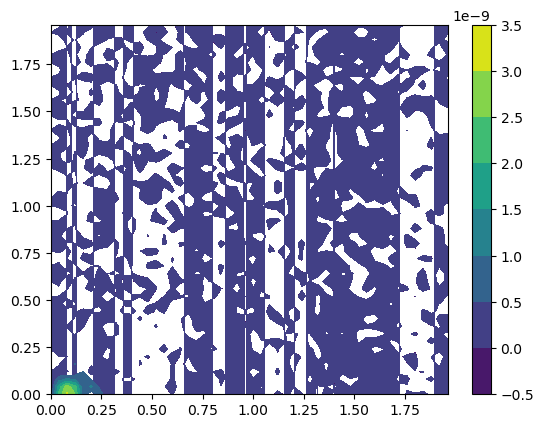

(0.0, 1.96)

In [10]:
plt.contourf(xv, yv, grid.Krsq .* a["jld_data"]["CBC"])
plt.colorbar()

plt.xlim(x[1], x[50])
plt.ylim(y[1], y[50])


4.294311382839453e-9
-7.57023224875642e-7
9.423912808609646e-7
-1.810737446024835e-7


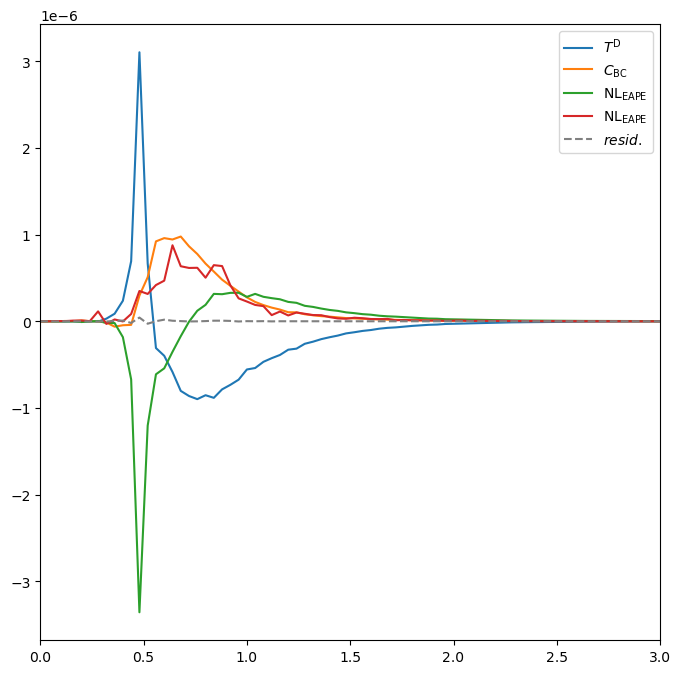

PyObject <matplotlib.legend.Legend object at 0x14732c7d0ee0>

In [103]:
fig,ax = plt.subplots(1,1, figsize=(8,8))

norm = a["jld_data"]["two_layer_vBT_scale"]^-3 * Ld^-1
ax.plot(grid.kr*Ld, grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .* norm, label=L"T^\mathrm{D}")
ax.plot(grid.kr*Ld, grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .* norm, label=L"C_\mathrm{BC}")
ax.plot(grid.kr*Ld, grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14] .* norm , label=L"\mathrm{NL}_\mathrm{EAPE}")

# ax.plot(grid.kr*Ld, (a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14]).* norm , label=L"sum")

ax.plot(grid.kr*Ld, grid.kr .* isotropic_mean(CBC, prob.grid) .* norm , label=L"\mathrm{NL}_\mathrm{EAPE}")



residual_EAPE = (a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5] .+ a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14]) 
ax.plot(grid.kr*Ld, grid.kr .* residual_EAPE .* norm , color="gray", linestyle="--", label=L"resid.")


println(sum(grid.kr .* residual_EAPE))
println(sum(grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,4]))
println(sum(grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,5]))
println(sum(grid.kr .* a["jld_data"]["two_layer_kspace_modal_nrg_budget"][:,14]))

ax.set_xlim(0.0, 3.)
ax.legend()

# ax.set_xscale("log")

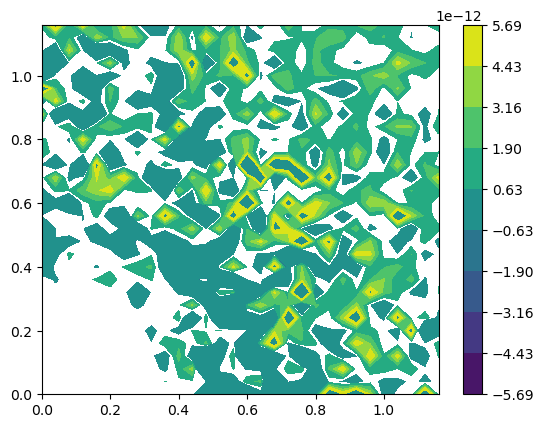

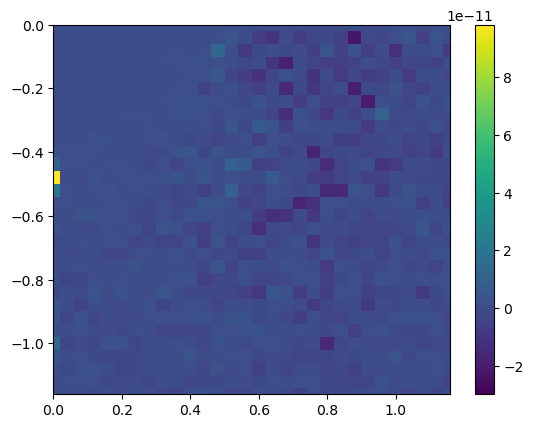

(-1.16, 0.0)

In [129]:
lb = maximum(abs.(grid.Krsq .* real(NLBC[:,:,3])))/10

plt.contourf(xv, yv, grid.Krsq .* real(NLBC[:,:,3]), levels = collect(range(-lb, lb, 10)) )
plt.colorbar()

plt.xlim(x[1], x[30])
plt.ylim(y[1], y[30])
# plt.ylim(-y[30], y[5])

# for mus[2], betas[9]

plt.figure()
plt.pcolormesh(xv, yv, (grid.Krsq .* real(T_Dh)))
plt.colorbar()

plt.xlim(x[1], x[30])
# plt.ylim(y[1], y[30])
plt.ylim(-y[30], y[1])

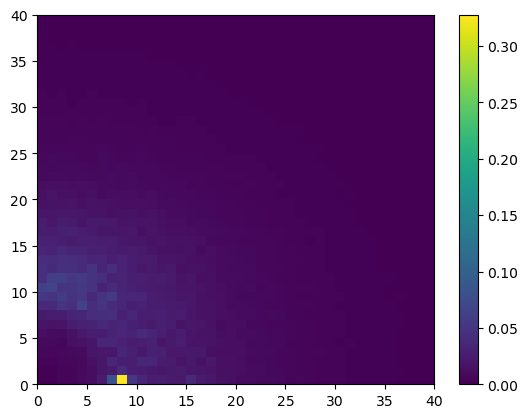

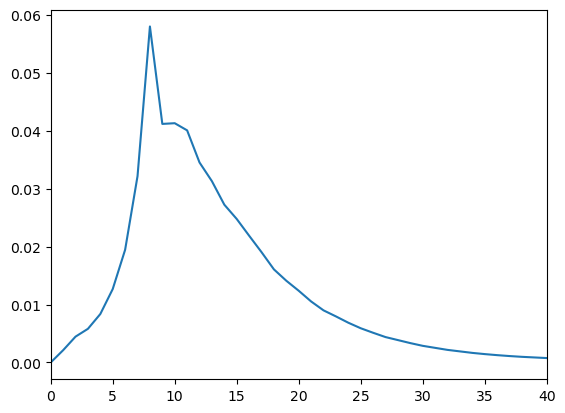

(0.0, 40.0)

In [26]:



plt.pcolormesh(a["jld_data"]["NL_BC_EAPE"], norm=norm, cmap = PyPlot.cm.bwr)
plt.colorbar()

plt.xlim(0,40)
plt.ylim(0,40)

plt.figure()
plt.plot(isotropic_mean(a["jld_data"]["NL_BC_EAPE"], prob.grid))

plt.xlim(0,40)


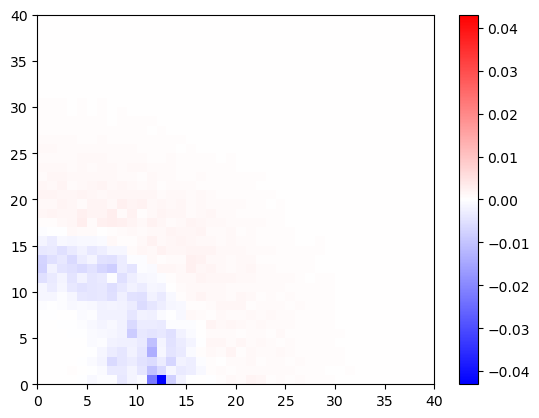

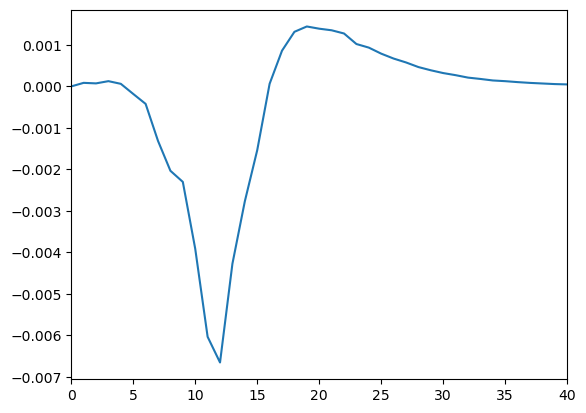

(0.0, 40.0)

In [36]:

lim = maximum(abs.(a["jld_data"]["NL_BC_EAPE"]))

norm = matplotlib.colors.TwoSlopeNorm(vcenter=0., vmin=-lim, vmax=lim) 

plt.pcolormesh(a["jld_data"]["NL_BC_EAPE"], norm=norm, cmap = PyPlot.cm.bwr)
plt.colorbar()

plt.xlim(0,40)
plt.ylim(0,40)

plt.figure()
plt.plot(isotropic_mean(a["jld_data"]["NL_BC_EAPE"], prob.grid))

plt.xlim(0,40)


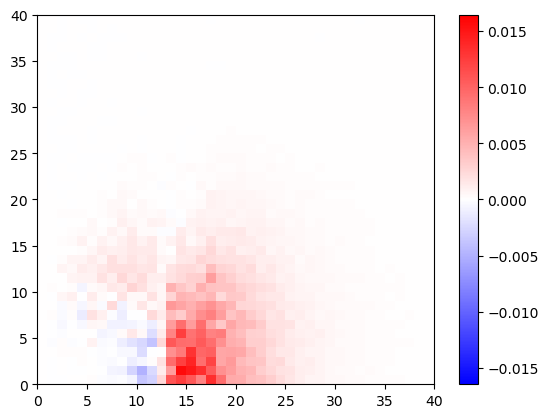

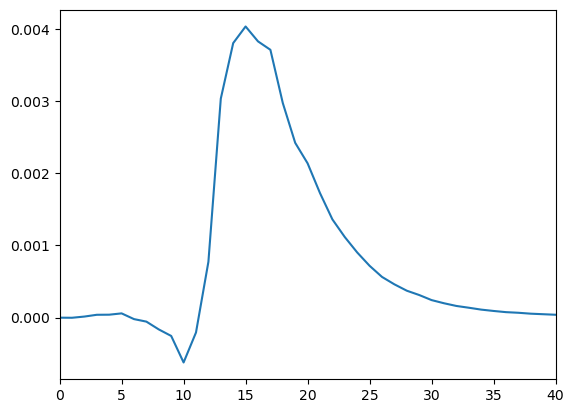

(0.0, 40.0)

In [31]:


lim = maximum(abs.(a["jld_data"]["CBC"]))

norm = matplotlib.colors.TwoSlopeNorm(vcenter=0., vmin=-lim, vmax=lim) 

plt.pcolormesh(a["jld_data"]["CBC"]', norm=norm, cmap = PyPlot.cm.bwr)
plt.colorbar()

plt.xlim(0,40)
plt.ylim(0,40)

plt.figure()
plt.plot(isotropic_mean(a["jld_data"]["CBC"], prob.grid))

plt.xlim(0,40)


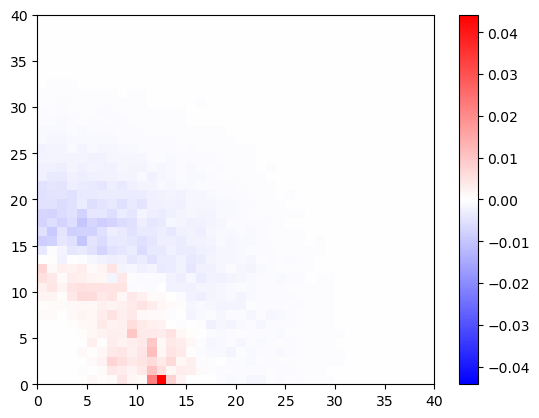

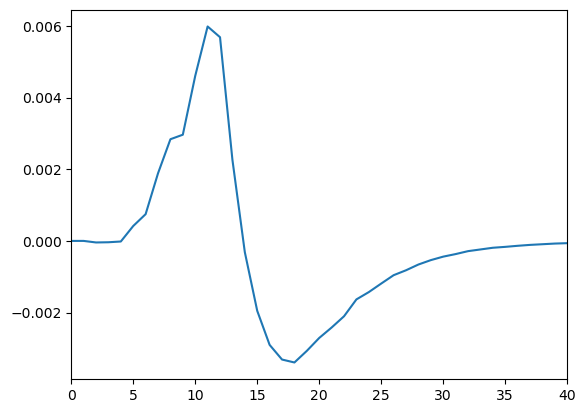

(0.0, 40.0)

In [35]:
lim = maximum(abs.(a["jld_data"]["T_D"]))

norm = matplotlib.colors.TwoSlopeNorm(vcenter=0., vmin=-lim, vmax=lim) 

plt.pcolormesh(a["jld_data"]["T_D"], norm=norm, cmap = PyPlot.cm.bwr)
plt.colorbar()

plt.xlim(0,40)
plt.ylim(0,40)

plt.figure()
plt.plot(isotropic_mean(a["jld_data"]["T_D"], prob.grid))

plt.xlim(0,40)


In [21]:

i=7
j=1
k=2


h0 = (h0s[i], 0.0)
kappa_loc = kappas[j]
mu_loc = mus[k]

global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, (0., 0.), h0)
global topo_PV, eta = define_topo(model_params)
global model_params = redef_mu_kappa_topoPV_h0(model_params, mu_loc, kappa_loc, topo_PV, h0)

beta = betas[9]
global model_params = redef_mu_kappa_beta(model_params, mu_loc, kappa_loc, beta)


# a = load(alt_data_dir*jld_name(model_params,71.99))
a = load(alt_data_dir*jld_name(model_params,71.95))

    

Dict{String, Any} with 1 entry:
  "jld_data" => Dict{String, Any}("ph_slices"=>0.0546627, "two_layer_modal_leng…

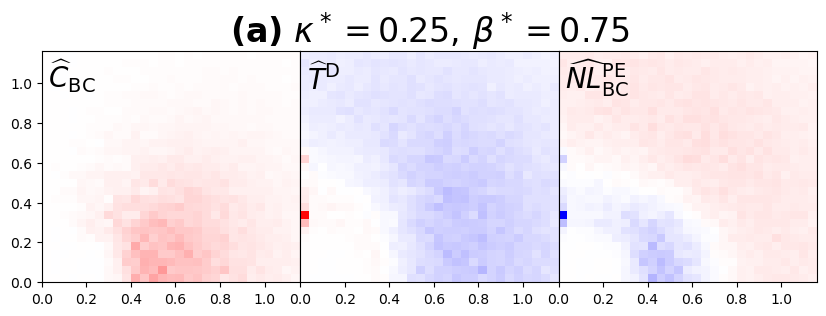

In [22]:
fig, ax = plt.subplots(1,3, figsize=(10,3))
# fig.tight_layout(pad=-2.0)

ax1=ax[1]; ax2=ax[2]; ax3=ax[3];

tsize = 24
fsize = 20

x = prob.grid.kr .* Ld
y = prob.grid.l .* Ld

x = append!(x[:,1], [x[end] + x[end] - x[end-1]])
# y = append!(y[1,:], [y[end] + y[end] - y[end-1]])

y = fftshift(y)
y = append!(y[1,:], [20.48])

lim_range = 30

lim = 1. * maximum([abs.(grid.Krsq .* a["jld_data"]["CBC"]); abs.(grid.Krsq .* a["jld_data"]["T_D"]); abs.(grid.Krsq .* a["jld_data"]["NL_BC_EAPE"])])

lim1 = lim2 = lim3 = lim
########################################################################################################
########################################################################################################

# lim1 = maximum(abs.(a["jld_data"]["CBC"]))

pc1 = ax1.pcolormesh(x, y, fftshift(grid.Krsq .* a["jld_data"]["CBC"],2)', vmin=-lim1, vmax=lim1, cmap = PyPlot.cm.bwr)
# plt.colorbar(pc1, location="bottom")

ax1.set_xlim(x[1],x[lim_range])
ax1.set_ylim(0,y[512+lim_range])



########################################################################################################
########################################################################################################

# lim2 = maximum(abs.(a["jld_data"]["T_D"]))

pc2 = ax2.pcolormesh(x, y, fftshift(grid.Krsq .* a["jld_data"]["T_D"],2)', vmin=-lim2, vmax=lim2, cmap = PyPlot.cm.bwr)
# plt.colorbar(pc1, location="bottom")

ax2.set_xlim(x[1],x[lim_range])
ax2.set_ylim(0,y[512+lim_range])




########################################################################################################
########################################################################################################

# lim3 = maximum(abs.(a["jld_data"]["NL_BC_EAPE"]))

pc3 = ax3.pcolormesh(x, y, fftshift(grid.Krsq .* a["jld_data"]["NL_BC_EAPE"],2)', vmin=-lim3, vmax=lim3, cmap = PyPlot.cm.bwr)
# plt.colorbar(pc1, location="bottom")

ax3.set_xlim(x[1],x[lim_range])
ax3.set_ylim(0,y[512+lim_range])





########################################################################################################
########################################################################################################

ax2.set_yticks([])
ax3.set_yticks([])

ax2.set_title(L"\mathbf{(a)} \ \kappa^* = 0.25, \, \beta^* = 0.75", fontsize=tsize)

ax1.text(0.025, 0.975, L"\widehat{C}_\mathrm{BC}", fontsize=fsize, horizontalalignment="left",verticalalignment="top", transform = ax1.transAxes);
ax2.text(0.025, 0.95, L"\widehat{T}^\mathrm{D}", fontsize=fsize, horizontalalignment="left",verticalalignment="top", transform = ax2.transAxes);
ax3.text(0.025, 0.975, L"\widehat{NL}^\mathrm{PE}_\mathrm{BC}", fontsize=fsize, horizontalalignment="left",verticalalignment="top", transform = ax3.transAxes);


plt.subplots_adjust(wspace=0, hspace=0)

